# Single-Cell RNA-seq Analysis of Influenza Vaccine Responses

## Project overview

This notebook documents an exploratory analysis of publicly available single-cell RNA-sequencing data (**GEO: GSE211560**) from PBMCs of older adults (65–80 years) vaccinated with the MF59-adjuvanted influenza vaccine (Fluad). The dataset comprises six donors (three triple responders and three triple non-responders) sampled at baseline (Day 0) and Day 7 post-vaccination (12 total samples), with PBMCs re-stimulated in vitro with vaccine antigens prior to 10x Genomics 5′ sequencing.
[Original Article Link](https://doi.org/10.1038/s41467-022-34487-z)

The workflow covers quality control, normalization, dimensionality reduction, clustering, marker-based cell annotation, cell-type composition, and focused B-cell, T-cell, and NK-cell analyses. A separate Seurat workflow was used as an independent check of the broad cellular structure.

## Reproducibility notes

- **Data:** Obtain the original dataset from the source study and place the 12 sample folders in the directory configured in the setup section. Raw data are not bundled with this notebook.
- **Environment:** The notebook was developed in Google Colab. Some setup cells use Colab/Google Drive; update the data path for your environment before running.
- **Execution:** Run cells sequentially from top to bottom. Later sections reuse objects created earlier in the notebook.
- **Interpretation:** The study includes only six biological donors. Cells from the same donor are not independent biological replicates; group comparisons and cell-level differential-expression results should therefore be interpreted as exploratory.
- **Annotation:** Cell labels are working biological annotations based on marker-gene patterns, not experimentally confirmed identities. Rare subpopulations and antibody-secreting-cell labels require particular caution.

## Analysis roadmap

1. Setup and pilot quality control
2. Load and filter all 12 samples
3. Normalize, select highly variable genes, and perform PCA/UMAP/clustering
4. Annotate broad cell populations and compare cell-type composition
5. Investigate B-cell subpopulations and their transcriptional features
6. Investigate T-cell and NK-cell states, differential expression, and gene-set enrichment

---


## 1. Setup and data access


In [ ]:
import sys
import platform
import importlib.metadata as metadata

print("Python version:", sys.version)
print("Platform:", platform.platform())

packages = [
    "scanpy",
    "anndata",
    "pandas",
    "numpy",
    "scipy",
    "matplotlib",
    "seaborn",
    "leidenalg",
    "igraph",
    "gseapy",

]

for package in packages:
    try:
        version = metadata.version(package)
        print(f"{package}: {version}")
    except metadata.PackageNotFoundError:
        print(f"{package}: not installed")

Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Platform: Linux-6.6.122+-x86_64-with-glibc2.39
scanpy: 1.12.4
anndata: 0.13.4
pandas: 3.1.0
numpy: 2.1.3
scipy: 1.16.3
matplotlib: 3.10.0
seaborn: 0.13.2
leidenalg: 0.12.0
igraph: 1.0.0
gseapy: 1.3.1


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
data_path = "Replace with your data path"

In [ ]:
import os

print(os.listdir(data_path))

['Day7_R3', 'Day7_R2', 'Day0_R2', 'Day7_NR1', 'Day7_NR2', 'Day7_R1', 'Day0_R1', 'Day7_NR3', 'Day0_R3', 'Day0_NR3', 'Day0_NR2', 'Day0_NR1']


In [ ]:
%pip install scanpy
import scanpy as sc

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 64.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 103.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 59.9 MB/s  0:00:00
  Attempting uninstall: pandas
    Found existing installation: pandas 2.2.3
    Uninstalling pandas-2.2.3:
      Successfully uninstalled pandas-2.2.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13/13 [scanpy]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.0 which is incompatible.


/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


In [ ]:
adata = sc.read_10x_mtx(
    f"{data_path}/Day0_NR1/",
    var_names = "gene_symbols",
    make_unique = True,
    compressed = False #Files are already uncompressed
)

In [ ]:
print(adata)
print(adata.shape)

AnnData object with n_obs × n_vars = 2499 × 33538
    var: 'gene_ids', 'feature_types'
    layers: None (.X)
(2499, 33538)


## 2. Pilot quality control: Day0_NR1


This pilot sample was used to inspect QC distributions and choose preliminary thresholds before applying the same thresholds across all samples.


In [ ]:
print(adata.obs.head())

Empty DataFrame
Columns: []
Index: [AAACCTGAGCATCATC-1, AAACCTGAGTACGACG-1, AAACCTGGTACCTACA-1, AAACCTGTCTGAAAGA-1, AAACGGGAGACAGAGA-1]


In [ ]:
print(adata.var.head())

                    gene_ids    feature_types
MIR1302-2HG  ENSG00000243485  Gene Expression
FAM138A      ENSG00000237613  Gene Expression
OR4F5        ENSG00000186092  Gene Expression
AL627309.1   ENSG00000238009  Gene Expression
AL627309.3   ENSG00000239945  Gene Expression


In [ ]:
print(adata.var['feature_types'].value_counts())

feature_types
Gene Expression    33538
Name: count, dtype: int64


In [ ]:
print(adata.X.shape)

(2499, 33538)


In [ ]:
print(adata.X.nnz) #nnz means number of non-zero entries

3995718


In [ ]:
print(adata.X.dtype)

float32


In [ ]:
print(adata.X.nnz / (adata.shape[0] * adata.shape[1]))

0.04767507814145994


In [ ]:
print(1 - adata.X.nnz / (adata.shape[0] * adata.shape[1]))

0.9523249218585401


In [ ]:
print(adata.X.data[:20]) #.data only shows non-zero values

[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [ ]:
print(adata.X.data.min())
print(adata.X.data.max())

1.0
1359.0


In [ ]:
print(adata.X.data[:100])

[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 2. 2.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 2. 1. 1. 1. 2. 1. 2. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 2. 1. 1. 1. 4. 2. 2. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 2. 1. 1. 1. 1. 1. 2. 1. 2. 1. 2. 1. 1. 1.
 2. 2. 1. 2.]


In [ ]:
n_genes = (adata.X > 0).sum(axis=1) #How many genes are detected in each cell (>0 values)
print(n_genes[:10])

[[1318]
 [1958]
 [1929]
 [ 781]
 [1826]
 [1691]
 [1839]
 [2033]
 [2236]
 [2129]]


In [ ]:
total_counts = adata.X.sum(axis=1).A1 #total counts per cell
print(total_counts[:10])

[4141. 4770. 5696. 1370. 4217. 4899. 5008. 4291. 5139. 4970.]


In [ ]:
adata.obs["n_genes"] = n_genes
adata.obs["total_counts"] = total_counts

In [ ]:
print(adata.obs.head())

                    n_genes  total_counts
AAACCTGAGCATCATC-1     1318        4141.0
AAACCTGAGTACGACG-1     1958        4770.0
AAACCTGGTACCTACA-1     1929        5696.0
AAACCTGTCTGAAAGA-1      781        1370.0
AAACGGGAGACAGAGA-1     1826        4217.0


Visualizing QC distributions

In [ ]:
import matplotlib.pyplot as plt

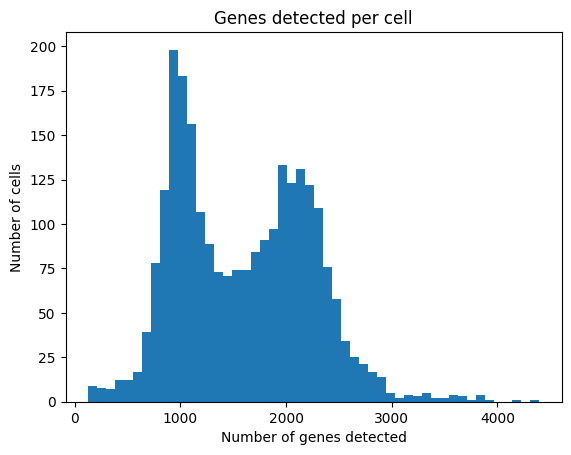

In [ ]:
plt.hist(adata.obs["n_genes"], bins = 50)
plt.xlabel("Number of genes detected")
plt.ylabel("Number of cells")
plt.title("Genes detected per cell")
plt.show()

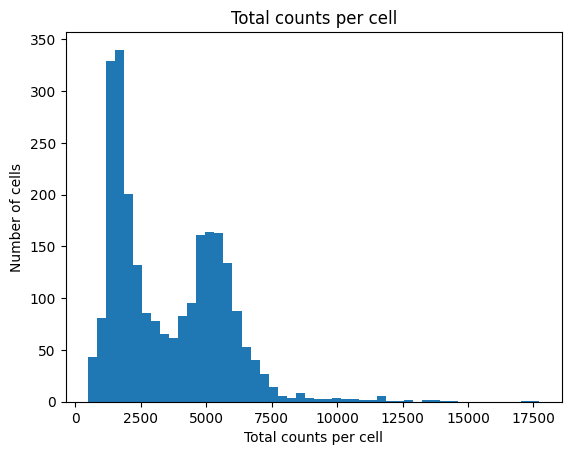

In [ ]:
plt.hist(adata.obs["total_counts"], bins=50)
plt.xlabel("Total counts per cell")
plt.ylabel("Number of cells")
plt.title("Total counts per cell")
plt.show()

In [ ]:
mt_genes = adata.var_names.str.startswith("MT-") #to find mitochondrial genes
print(mt_genes.sum())

13


In [ ]:
mt_counts = adata[:, mt_genes].X.sum(axis=1).A1 #total mt genes in each cell
print(mt_counts[:10])

[ 16. 311.  83. 150.  97.  64. 139.  29. 148.  91.]


In [ ]:
mt_percent = (mt_counts / total_counts) * 100
print(mt_percent[:10])

[ 0.3863801  6.519916   1.457163  10.948905   2.3002136  1.3063891
  2.775559   0.6758331  2.8799376  1.8309859]


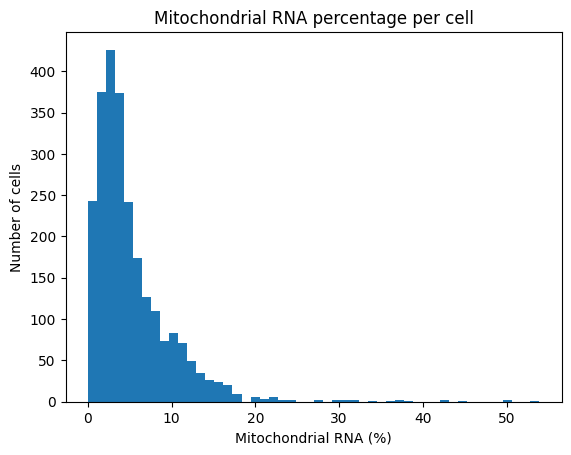

In [ ]:
plt.hist(mt_percent, bins=50)
plt.xlabel("Mitochondrial RNA (%)")
plt.ylabel("Number of cells")
plt.title("Mitochondrial RNA percentage per cell")
plt.show()

Plot of Genes detected vs mitochondrial percentage

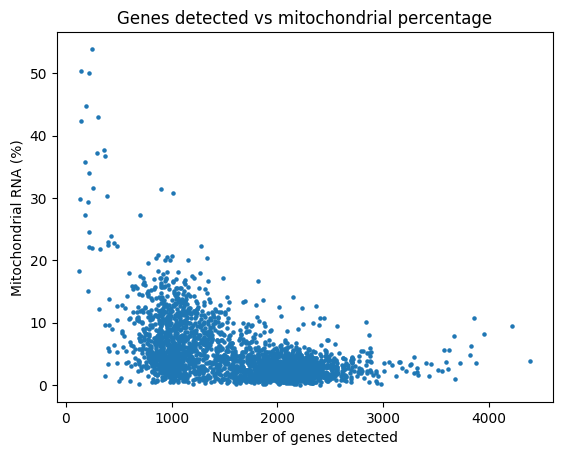

In [ ]:
plt.scatter(
    adata.obs["n_genes"],
    mt_percent,
    s=5
)

plt.xlabel("Number of genes detected")
plt.ylabel("Mitochondrial RNA (%)")
plt.title("Genes detected vs mitochondrial percentage")
plt.show()

In [ ]:
print("Minimum genes:", adata.obs["n_genes"].min())
print("Maximum genes:", adata.obs["n_genes"].max())

print("Minimum counts:", adata.obs["total_counts"].min())
print("Maximum counts:", adata.obs["total_counts"].max())

print("Minimum mt%:", mt_percent.min())
print("Maximum mt%:", mt_percent.max())

Minimum genes: 128
Maximum genes: 4394
Minimum counts: 500.0
Maximum counts: 17715.0
Minimum mt%: 0.03579098
Maximum mt%: 53.88471


In [ ]:
print("Cells with <500 genes:", (adata.obs["n_genes"] < 500).sum())
print("Cells with <1000 genes:", (adata.obs["n_genes"] < 1000).sum())

print("Cells with >10% mt:", (mt_percent > 10).sum())
print("Cells with >20% mt:", (mt_percent > 20).sum())

Cells with <500 genes: 41
Cells with <1000 genes: 534
Cells with >10% mt: 329
Cells with >20% mt: 37


In [ ]:
high_mt = mt_percent > 20

print(adata.obs.loc[high_mt, ["n_genes", "total_counts"]].describe())

           n_genes  total_counts
count    37.000000     37.000000
mean    512.189189   1153.648682
std     365.486118    706.704956
min     136.000000    509.000000
25%     216.000000    648.000000
50%     367.000000    798.000000
75%     867.000000   1661.000000
max    1338.000000   3388.000000


Preliminary QC decision

Remove cells with:
n_genes < 500
OR
mt_percent > 20%

In [ ]:
low_genes = adata.obs["n_genes"] < 500
high_mt = mt_percent > 20

print("Low-gene cells:", low_genes.sum())
print("High-mt cells:", high_mt.sum())
print("Both low-gene and high-mt:", (low_genes & high_mt).sum())
print("Either criterion:", (low_genes | high_mt).sum())

Low-gene cells: 41
High-mt cells: 37
Both low-gene and high-mt: 25
Either criterion: 53


In [ ]:
qc_filter = (
    (adata.obs["n_genes"] >= 500) &
    (mt_percent <= 20)
)

Genes detected vs total counts

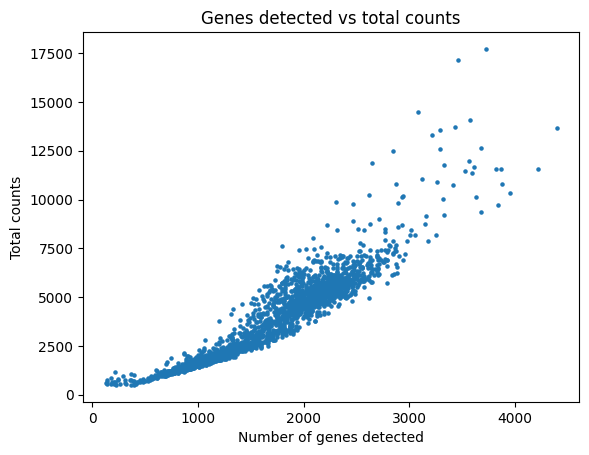

In [ ]:
plt.scatter(
    adata.obs["n_genes"],
    adata.obs["total_counts"],
    s=5
)

plt.xlabel("Number of genes detected")
plt.ylabel("Total counts")
plt.title("Genes detected vs total counts")
plt.show()

In [ ]:
print("Cells before QC:", adata.n_obs)
print("Cells after QC:", qc_filter.sum())
print("Cells removed:", (~qc_filter).sum())

Cells before QC: 2499
Cells after QC: 2446
Cells removed: 53


In [ ]:
print("Percentage retained:", (qc_filter.sum() / adata.n_obs) * 100)

Percentage retained: 97.87915166066426


97.9% cells were ratained after QC filtering

In [ ]:
adata = adata[qc_filter].copy()

In [ ]:
print(adata)
print(adata.obs[["n_genes", "total_counts"]].describe())

AnnData object with n_obs × n_vars = 2446 × 33538
    obs: 'n_genes', 'total_counts'
    var: 'gene_ids', 'feature_types'
    layers: None (.X)
           n_genes  total_counts
count  2446.000000   2446.000000
mean   1623.281276   3634.793457
std     619.379546   2145.374512
min     503.000000    706.000000
25%    1058.000000   1716.250000
50%    1605.500000   3188.500000
75%    2112.750000   5254.750000
max    4394.000000  17715.000000


## 3. Load all 12 samples


In [ ]:
samples = [
    "Day0_NR1",
    "Day0_NR2",
    "Day0_NR3",
    "Day0_R1",
    "Day0_R2",
    "Day0_R3",
    "Day7_NR1",
    "Day7_NR2",
    "Day7_NR3",
    "Day7_R1",
    "Day7_R2",
    "Day7_R3"
]

print(samples)
print("Number of samples:", len(samples))

['Day0_NR1', 'Day0_NR2', 'Day0_NR3', 'Day0_R1', 'Day0_R2', 'Day0_R3', 'Day7_NR1', 'Day7_NR2', 'Day7_NR3', 'Day7_R1', 'Day7_R2', 'Day7_R3']
Number of samples: 12


In [ ]:
for sample in samples:
    sample_path = f"{data_path}/{sample}"
    print(sample, os.path.exists(sample_path))

Day0_NR1 True
Day0_NR2 True
Day0_NR3 True
Day0_R1 True
Day0_R2 True
Day0_R3 True
Day7_NR1 True
Day7_NR2 True
Day7_NR3 True
Day7_R1 True
Day7_R2 True
Day7_R3 True


In [ ]:
adatas = {}

for sample in samples:
  adatas[sample] = sc.read_10x_mtx(
      f"{data_path}/{sample}",
      var_names = "gene_symbols",
      make_unique = True,
      compressed = False
  )

print("Number of loaded samples:", len(adatas))

Number of loaded samples: 12


In [ ]:
for sample in adatas:
  print(sample, adatas[sample].shape)

Day0_NR1 (2499, 33538)
Day0_NR2 (2625, 33538)
Day0_NR3 (2422, 33538)
Day0_R1 (6374, 33538)
Day0_R2 (5061, 33538)
Day0_R3 (3742, 33538)
Day7_NR1 (2336, 33538)
Day7_NR2 (3835, 33538)
Day7_NR3 (5518, 33538)
Day7_R1 (3402, 33538)
Day7_R2 (10219, 33538)
Day7_R3 (9736, 33538)


## 4. Quality control across all samples


The working filter retains cells with at least 500 detected genes and no more than 20% mitochondrial reads. These thresholds are pragmatic choices for this dataset and should be reported as analysis parameters, not universal cutoffs.


In [ ]:
adata_test = adatas["Day0_NR2"]

mt_genes = adata_test.var_names.str.startswith("MT-")

n_genes = (adata_test.X > 0).sum(axis=1).A1
total_counts = adata_test.X.sum(axis=1).A1
mt_counts = adata_test[:, mt_genes].X.sum(axis=1).A1

adata_test.obs["n_genes"] = n_genes
adata_test.obs["total_counts"] = total_counts
adata_test.obs["mt_percent"] = (mt_counts / total_counts) * 100

print(adata_test.obs[["n_genes", "total_counts", "mt_percent"]].head())

                    n_genes  total_counts  mt_percent
AAACCTGCAAGACACG-1      957        1550.0    2.258065
AAACCTGCAGACGCAA-1      946        1542.0    6.744488
AAACCTGCAGCTCGAC-1     2246        4406.0    9.305492
AAACCTGCATCCGCGA-1     1005        1610.0    4.906832
AAACCTGGTCAGCTAT-1     1317        2173.0    6.166590


In [ ]:
for sample in adatas:

    adata_sample = adatas[sample]

    mt_genes = adata_sample.var_names.str.startswith("MT-")

    n_genes = (adata_sample.X > 0).sum(axis=1).A1
    total_counts = adata_sample.X.sum(axis=1).A1
    mt_counts = adata_sample[:, mt_genes].X.sum(axis=1).A1

    adata_sample.obs["n_genes"] = n_genes
    adata_sample.obs["total_counts"] = total_counts
    adata_sample.obs["mt_percent"] = (mt_counts / total_counts) * 100

In [ ]:
for sample in adatas:
    print(sample, adatas[sample].obs.columns.tolist())

Day0_NR1 ['n_genes', 'total_counts', 'mt_percent']
Day0_NR2 ['n_genes', 'total_counts', 'mt_percent']
Day0_NR3 ['n_genes', 'total_counts', 'mt_percent']
Day0_R1 ['n_genes', 'total_counts', 'mt_percent']
Day0_R2 ['n_genes', 'total_counts', 'mt_percent']
Day0_R3 ['n_genes', 'total_counts', 'mt_percent']
Day7_NR1 ['n_genes', 'total_counts', 'mt_percent']
Day7_NR2 ['n_genes', 'total_counts', 'mt_percent']
Day7_NR3 ['n_genes', 'total_counts', 'mt_percent']
Day7_R1 ['n_genes', 'total_counts', 'mt_percent']
Day7_R2 ['n_genes', 'total_counts', 'mt_percent']
Day7_R3 ['n_genes', 'total_counts', 'mt_percent']


In [ ]:
for sample in adatas:

    adata_sample = adatas[sample]

    qc_filter = (
        (adata_sample.obs["n_genes"] >= 500) &
        (adata_sample.obs["mt_percent"] <= 20)
    )

    adatas[sample] = adata_sample[qc_filter].copy()

In [ ]:
for sample in adatas:
    print(sample, adatas[sample].n_obs, "cells remaining")

Day0_NR1 2446 cells remaining
Day0_NR2 2556 cells remaining
Day0_NR3 2378 cells remaining
Day0_R1 6199 cells remaining
Day0_R2 4985 cells remaining
Day0_R3 3653 cells remaining
Day7_NR1 2275 cells remaining
Day7_NR2 3756 cells remaining
Day7_NR3 5439 cells remaining
Day7_R1 3299 cells remaining
Day7_R2 9865 cells remaining
Day7_R3 9594 cells remaining


## 5. Add biological metadata


In [ ]:
for sample in adatas:

    adata_sample = adatas[sample]

    # Add sample ID
    adata_sample.obs["Sample"] = sample

    # Extract time point
    adata_sample.obs["Time"] = sample.split("_")[0]

    # Extract donor/response ID
    donor = sample.split("_")[1]
    adata_sample.obs["Donor"] = donor

    # Define response group
    if donor.startswith("NR"):
        adata_sample.obs["Response"] = "Non-responder"
    else:
        adata_sample.obs["Response"] = "Responder"

In [ ]:
print(
    adatas["Day7_R2"].obs[
        ["Sample", "Donor", "Response", "Time"]
    ].head()
)

                     Sample Donor   Response  Time
AAACCTGAGCACAGGT-1  Day7_R2    R2  Responder  Day7
AAACCTGAGCCCTAAT-1  Day7_R2    R2  Responder  Day7
AAACCTGAGCTCAACT-1  Day7_R2    R2  Responder  Day7
AAACCTGCAAACCCAT-1  Day7_R2    R2  Responder  Day7
AAACCTGCACAACTGT-1  Day7_R2    R2  Responder  Day7


In [ ]:
for sample in adatas:
    print(
        sample,
        adatas[sample].obs["Donor"].unique(),
        adatas[sample].obs["Response"].unique(),
        adatas[sample].obs["Time"].unique()
    )

Day0_NR1 <ArrowStringArray>
['NR1']
Length: 1, dtype: str <ArrowStringArray>
['Non-responder']
Length: 1, dtype: str <ArrowStringArray>
['Day0']
Length: 1, dtype: str
Day0_NR2 <ArrowStringArray>
['NR2']
Length: 1, dtype: str <ArrowStringArray>
['Non-responder']
Length: 1, dtype: str <ArrowStringArray>
['Day0']
Length: 1, dtype: str
Day0_NR3 <ArrowStringArray>
['NR3']
Length: 1, dtype: str <ArrowStringArray>
['Non-responder']
Length: 1, dtype: str <ArrowStringArray>
['Day0']
Length: 1, dtype: str
Day0_R1 <ArrowStringArray>
['R1']
Length: 1, dtype: str <ArrowStringArray>
['Responder']
Length: 1, dtype: str <ArrowStringArray>
['Day0']
Length: 1, dtype: str
Day0_R2 <ArrowStringArray>
['R2']
Length: 1, dtype: str <ArrowStringArray>
['Responder']
Length: 1, dtype: str <ArrowStringArray>
['Day0']
Length: 1, dtype: str
Day0_R3 <ArrowStringArray>
['R3']
Length: 1, dtype: str <ArrowStringArray>
['Responder']
Length: 1, dtype: str <ArrowStringArray>
['Day0']
Length: 1, dtype: str
Day7_NR1 <ArrowS

## 6. Concatenate the 12 samples


In [ ]:
adata = sc.concat(
    adatas,
    label="Sample",
    join="outer",
    index_unique="-"
)

print(adata)

AnnData object with n_obs × n_vars = 56445 × 33538
    obs: 'n_genes', 'total_counts', 'mt_percent', 'Sample', 'Time', 'Donor', 'Response'
    layers: None (.X)


In [ ]:
print(adata.obs["Sample"].value_counts())

Sample
Day7_R2     9865
Day7_R3     9594
Day0_R1     6199
Day7_NR3    5439
Day0_R2     4985
Day7_NR2    3756
Day0_R3     3653
Day7_R1     3299
Day0_NR2    2556
Day0_NR1    2446
Day0_NR3    2378
Day7_NR1    2275
Name: count, dtype: int64


In [ ]:
print(adata.obs["Response"].value_counts())
print(adata.obs["Time"].value_counts())

Response
Responder        37595
Non-responder    18850
Name: count, dtype: int64
Time
Day7    34228
Day0    22217
Name: count, dtype: int64


## 7. Normalization and highly variable genes


Raw counts are retained in `adata.layers['counts']` before library-size normalization and log transformation. Batch-aware highly variable gene selection uses `Sample` as the batch key.


In [ ]:
adata.layers["counts"] = adata.X.copy()

In [ ]:
print(adata.layers.keys())

KeysView(Layers with keys: None, 'counts')


In [ ]:
sc.pp.normalize_total(adata, target_sum=1e4)

In [ ]:
print(adata.X.sum(axis=1)[:5])

[[10000.   ]
 [ 9999.999]
 [10000.   ]
 [10000.   ]
 [ 9999.999]]


In [ ]:
sc.pp.log1p(adata)

In [ ]:
print(adata.X.sum(axis=1)[:5])

[[2077.2373]
 [2847.3645]
 [2612.2676]
 [1792.2489]
 [2796.373 ]]


In [ ]:
sc.pp.highly_variable_genes(
    adata,
    n_top_genes=2000,
    batch_key="Sample"
)

In [ ]:
print(adata.var['highly_variable'].sum())

2000


In [ ]:
print(adata.var[["highly_variable", "means"]].head())

             highly_variable     means
MIR1302-2HG            False  0.000039
FAM138A                False  0.000000
OR4F5                  False  0.000000
AL627309.1             False  0.007004
AL627309.3             False  0.000936


In [ ]:
print(adata.var.columns)

Index(['highly_variable', 'means', 'dispersions', 'dispersions_norm',
       'highly_variable_nbatches', 'highly_variable_intersection'],
      dtype='str')


## 8. Principal component analysis and neighborhood graph


In [ ]:
sc.tl.pca(
    adata,
    n_comps = 50,
    mask_var = "highly_variable"
)

In [ ]:
print(adata.obsm['X_pca'].shape)

(56445, 50)


In [ ]:
print(adata.uns['pca']['variance_ratio'][:20])

[0.06487752 0.06287686 0.02902297 0.01705653 0.0140942  0.0101538
 0.00818109 0.00673575 0.00565311 0.00559445 0.00474243 0.00455097
 0.00399895 0.00364801 0.00352823 0.00340918 0.00314132 0.00291023
 0.0028123  0.00277641]


In [ ]:
print(adata.uns['pca']['variance_ratio'].sum())

0.3226314


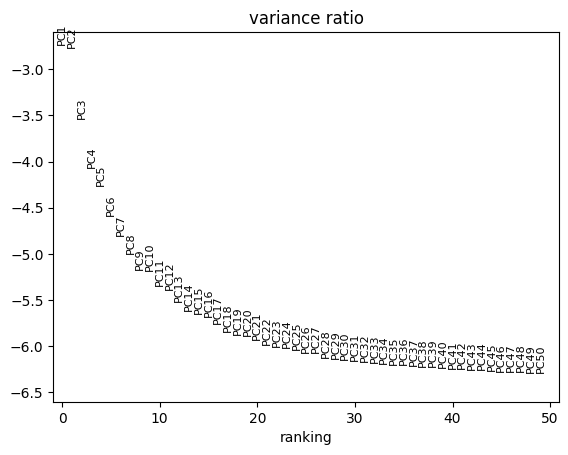

In [ ]:
sc.pl.pca_variance_ratio(
    adata,
    n_pcs = 50,
    log = True
)

In [ ]:
sc.pp.neighbors(
    adata,
    n_neighbors = 15,
    n_pcs = 30
)

In [ ]:
sc.tl.umap(adata)


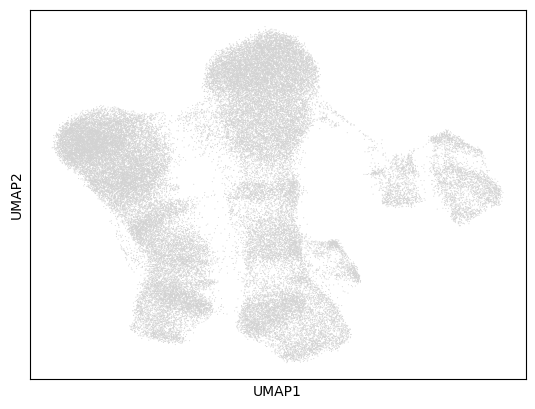

In [ ]:
sc.pl.umap(adata)

In [ ]:
%pip install -q igraph leidenalg

In [ ]:
sc.tl.leiden(
    adata,
    resolution = 0.5,
    key_added = "leiden",
    flavor="igraph",
    n_iterations=2,
    directed=False
)

In [ ]:
print(adata.obs["leiden"].value_counts().sort_index())

leiden
0    11763
1     4693
2     8538
3     8450
4     5644
5     5526
6     1248
7     6934
8      849
9     2800
Name: count, dtype: int64


## 9. Global clustering and marker genes


Leiden clusters are interpreted using marker combinations and biological context. Cluster IDs are arbitrary and should not be treated as cell identities without marker evidence.


In [ ]:
sc.tl.rank_genes_groups(
    adata,
    groupby="leiden",
    method="wilcoxon"
)

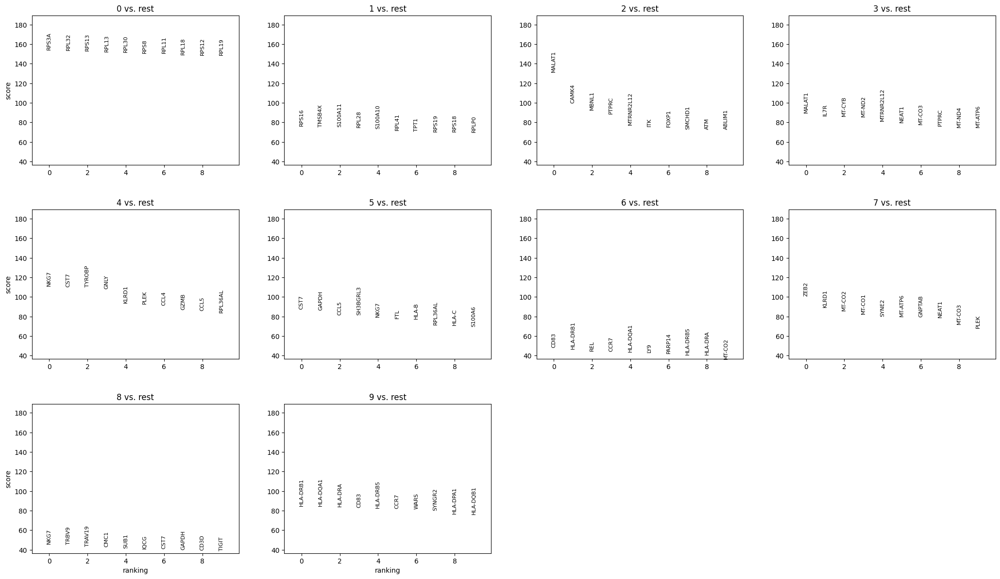

In [ ]:
sc.pl.rank_genes_groups(
    adata,
    n_genes=10,
    sharex=False
)

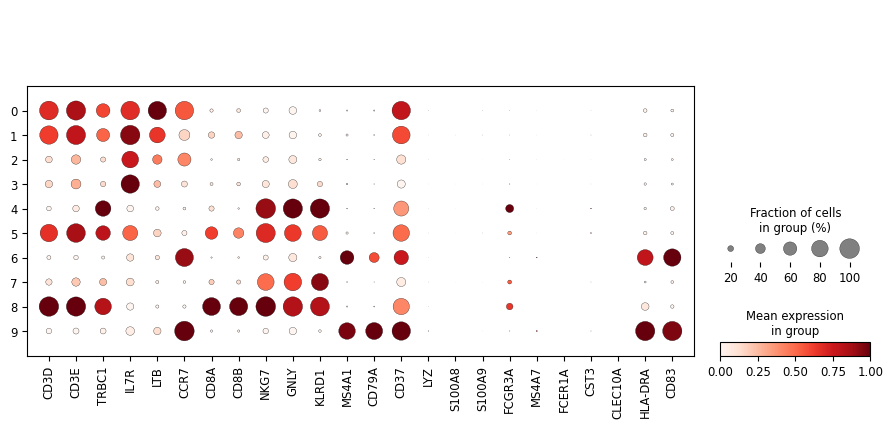

In [ ]:
marker_genes = [
    "CD3D", "CD3E", "TRBC1",       # T cells
    "IL7R", "LTB", "CCR7",         # CD4/naive-memory T
    "CD8A", "CD8B",               # CD8 T
    "NKG7", "GNLY", "KLRD1",      # NK cells
    "MS4A1", "CD79A", "CD37",     # B cells
    "LYZ", "S100A8", "S100A9",    # monocytes
    "FCGR3A", "MS4A7",            # FCGR3A+ monocytes
    "FCER1A", "CST3", "CLEC10A",  # dendritic/APC
    "HLA-DRA", "CD83"             # activated APC
]

sc.pl.dotplot(
    adata,
    var_names=marker_genes,
    groupby="leiden",
    standard_scale="var"
)

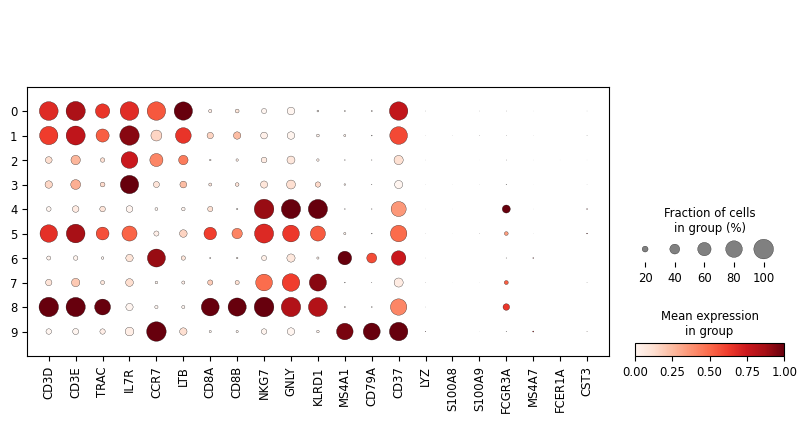

In [ ]:
lineage_markers = [
    "CD3D", "CD3E", "TRAC",
    "IL7R", "CCR7", "LTB",
    "CD8A", "CD8B",
    "NKG7", "GNLY", "KLRD1",
    "MS4A1", "CD79A", "CD37",
    "LYZ", "S100A8", "S100A9",
    "FCGR3A", "MS4A7",
    "FCER1A", "CST3"
]

sc.pl.dotplot(
    adata,
    var_names=lineage_markers,
    groupby="leiden",
    standard_scale="var"
)

## 10. Broad cell-type annotation


In [ ]:
cell_type_map = {
    "0": "Naive/Central Memory CD4 T cells",
    "1": "Naive/central memory mixed T cells",
    "2": "Resting CD4 T cells",
    "3": "NK/T-like cytotoxic cells",
    "4": "NK cells",
    "5": "Cytotoxic CD8 T cells",
    "6": "B cells",
    "7": "NK cells",
    "8": "Cytotoxic CD8 T cells",
    "9": "B cells"
}

In [ ]:
adata.obs["cell_type"] = adata.obs["leiden"].map(cell_type_map)

In [ ]:
print(adata.obs["cell_type"].value_counts())

cell_type
NK cells                              12578
Naive/Central Memory CD4 T cells      11763
Resting CD4 T cells                    8538
NK/T-like cytotoxic cells              8450
Cytotoxic CD8 T cells                  6375
Naive/central memory mixed T cells     4693
B cells                                4048
Name: count, dtype: int64


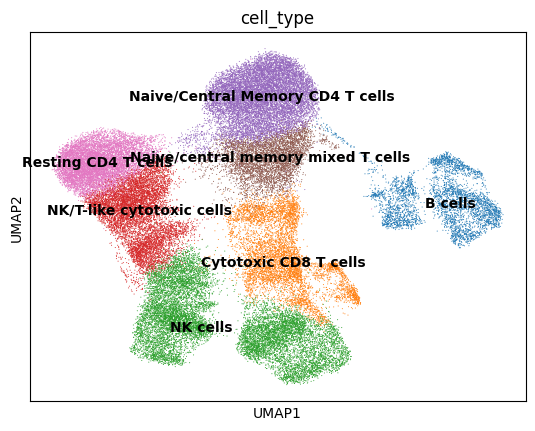

In [ ]:
sc.pl.umap(
    adata,
    color="cell_type",
    legend_loc="on data"
)

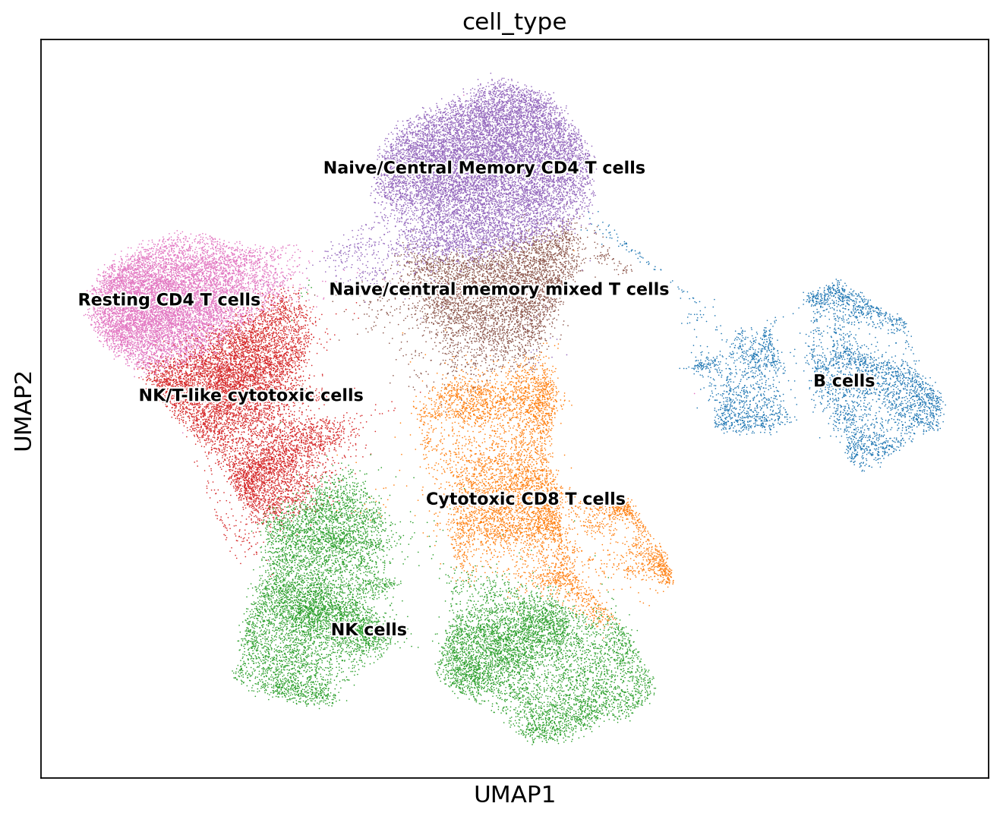

In [ ]:
sc.set_figure_params(figsize=(10,8))

sc.pl.umap(
    adata,
    color="cell_type",
    legend_loc="on data",
    legend_fontsize=10,
    legend_fontweight="bold",
    legend_fontoutline=2
)

## 11. Biological characterization of cell populations


In [ ]:
print(adata.obs["cell_type"].value_counts())

cell_type
NK cells                              12578
Naive/Central Memory CD4 T cells      11763
Resting CD4 T cells                    8538
NK/T-like cytotoxic cells              8450
Cytotoxic CD8 T cells                  6375
Naive/central memory mixed T cells     4693
B cells                                4048
Name: count, dtype: int64


In [ ]:
print(
    adata.obs.groupby(["Sample", "cell_type"]).size()
)

Sample    cell_type                         
Day0_NR1  B cells                                 20
          Cytotoxic CD8 T cells                  448
          NK cells                              1333
          NK/T-like cytotoxic cells              283
          Naive/Central Memory CD4 T cells       101
                                                ... 
Day7_R3   NK cells                               765
          NK/T-like cytotoxic cells              771
          Naive/Central Memory CD4 T cells      2627
          Naive/central memory mixed T cells    1668
          Resting CD4 T cells                    598
Length: 84, dtype: int64


In [ ]:
import pandas as pd

cell_counts = pd.crosstab(
    adata.obs["Sample"],
    adata.obs["cell_type"]
)

print(cell_counts)

cell_type  B cells  Cytotoxic CD8 T cells  NK cells  \
Sample                                                
Day0_NR1        20                    448      1333   
Day0_NR2        97                     38       895   
Day0_NR3        78                    182       819   
Day0_R1        132                    527      1158   
Day0_R2        579                    621       699   
Day0_R3        130                    483       387   
Day7_NR1        35                    371      1046   
Day7_NR2       168                     95      1431   
Day7_NR3        96                    592      1866   
Day7_R1         74                    251      1077   
Day7_R2       1143                   1098      1102   
Day7_R3       1496                   1669       765   

cell_type  NK/T-like cytotoxic cells  Naive/Central Memory CD4 T cells  \
Sample                                                                   
Day0_NR1                         283                               101   
Day0_NR

In [ ]:
cell_percent = cell_counts.div(
    cell_counts.sum(axis=1),
    axis=0
) * 100

print(cell_percent.round(2))

cell_type  B cells  Cytotoxic CD8 T cells  NK cells  \
Sample                                                
Day0_NR1      0.82                  18.32     54.50   
Day0_NR2      3.79                   1.49     35.02   
Day0_NR3      3.28                   7.65     34.44   
Day0_R1       2.13                   8.50     18.68   
Day0_R2      11.61                  12.46     14.02   
Day0_R3       3.56                  13.22     10.59   
Day7_NR1      1.54                  16.31     45.98   
Day7_NR2      4.47                   2.53     38.10   
Day7_NR3      1.77                  10.88     34.31   
Day7_R1       2.24                   7.61     32.65   
Day7_R2      11.59                  11.13     11.17   
Day7_R3      15.59                  17.40      7.97   

cell_type  NK/T-like cytotoxic cells  Naive/Central Memory CD4 T cells  \
Sample                                                                   
Day0_NR1                       11.57                              4.13   
Day0_NR

In [ ]:
print(cell_percent.sum(axis=1).round(2))

Sample
Day0_NR1    100.0
Day0_NR2    100.0
Day0_NR3    100.0
Day0_R1     100.0
Day0_R2     100.0
Day0_R3     100.0
Day7_NR1    100.0
Day7_NR2    100.0
Day7_NR3    100.0
Day7_R1     100.0
Day7_R2     100.0
Day7_R3     100.0
dtype: float64


In [ ]:
sample_order = [
    "Day0_NR1", "Day7_NR1",
    "Day0_NR2", "Day7_NR2",
    "Day0_NR3", "Day7_NR3",
    "Day0_R1",  "Day7_R1",
    "Day0_R2",  "Day7_R2",
    "Day0_R3",  "Day7_R3"
]

cell_percent_plot = cell_percent.loc[sample_order]

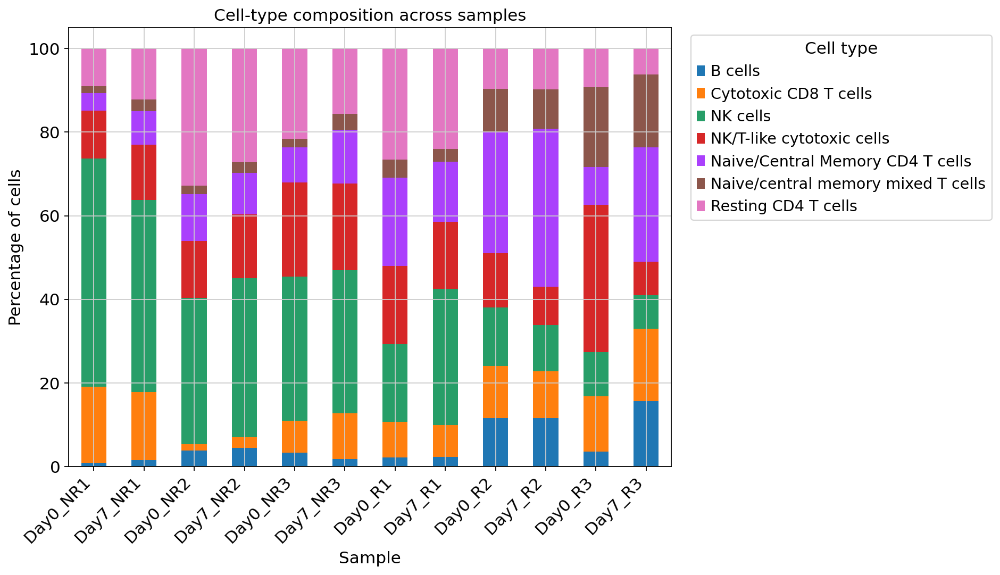

In [ ]:
import matplotlib.pyplot as plt

ax = cell_percent_plot.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 7)
)

ax.set_ylabel("Percentage of cells")
ax.set_xlabel("Sample")
ax.set_title("Cell-type composition across samples")
plt.xticks(rotation=45, ha="right")
plt.legend(
    title="Cell type",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

## 12. UMAP by response group and time point


In [ ]:
#First create a simple Day variable within each response group:
adata.obs["Time_Group"] = adata.obs["Time"].astype(str)

/usr/local/lib/python3.13/dist-packages/scanpy/_utils/__init__.py:471: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata._sanitize()
/usr/local/lib/python3.13/dist-packages/scanpy/_utils/__init__.py:471: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata._sanitize()


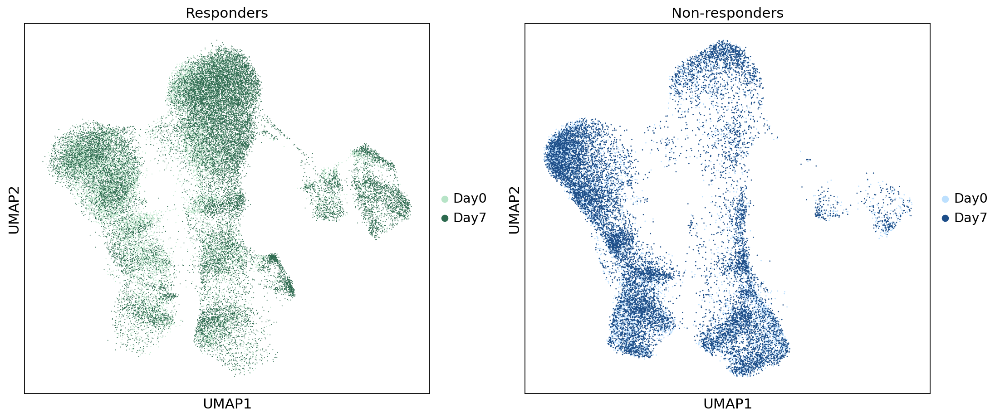

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Responder
sc.pl.umap(
    adata[adata.obs["Response"] == "Responder"],
    color="Time_Group",
    palette=["#b7e4c7", "#2d6a4f"],
    title="Responders",
    ax=axes[0],
    show=False,
    legend_loc="right margin"
)

# Non-responder
sc.pl.umap(
    adata[adata.obs["Response"] == "Non-responder"],
    color="Time_Group",
    palette=["#bde0fe", "#1d4e89"],
    title="Non-responders",
    ax=axes[1],
    show=False,
    legend_loc="right margin"
)

plt.tight_layout()
plt.show()

/usr/local/lib/python3.13/dist-packages/scanpy/_utils/__init__.py:471: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata._sanitize()
/usr/local/lib/python3.13/dist-packages/scanpy/_utils/__init__.py:471: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata._sanitize()


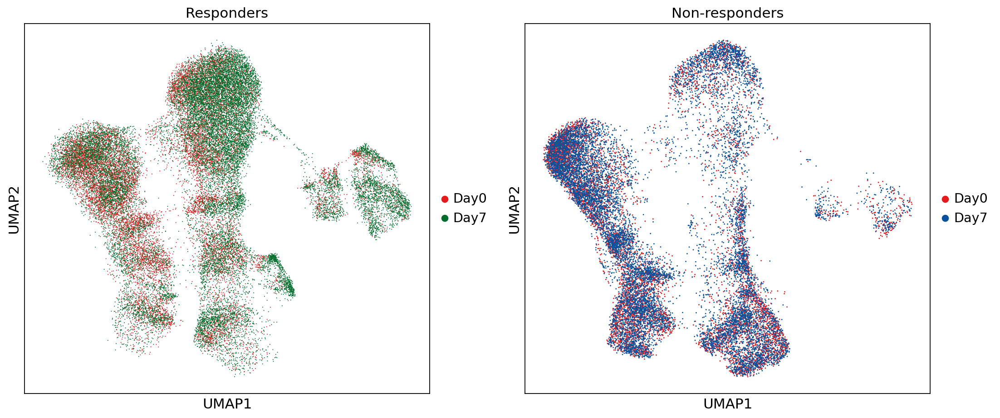

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Responders
sc.pl.umap(
    adata[adata.obs["Response"] == "Responder"],
    color="Time_Group",
    palette=["#E41A1C", "#006D2C"],
    title="Responders",
    ax=axes[0],
    show=False,
    legend_loc="right margin"
)

# Non-responders
sc.pl.umap(
    adata[adata.obs["Response"] == "Non-responder"],
    color="Time_Group",
    palette=["#E41A1C", "#08519C"],
    title="Non-responders",
    ax=axes[1],
    show=False,
    legend_loc="right margin"
)

plt.tight_layout()
plt.show()

## 13. Cell-type composition by response and time point


Composition plots are descriptive. With three donors per response group, avoid treating cells as independent replicates or interpreting cell-level tests as definitive donor-level evidence.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
plot_data = cell_percent.copy()

plot_data["Sample"] = plot_data.index
plot_data["Time"] = plot_data["Sample"].str.extract(r"^(Day0|Day7)")
plot_data["Response"] = np.where(
    plot_data["Sample"].str.contains("NR"),
    "NR",
    "R"
)

plot_data = plot_data.melt(
    id_vars=["Sample", "Time", "Response"],
    var_name="Cell type",
    value_name="Proportion"
)

print(plot_data.head())

     Sample  Time Response Cell type  Proportion
0  Day0_NR1  Day0       NR   B cells    0.817661
1  Day0_NR2  Day0       NR   B cells    3.794992
2  Day0_NR3  Day0       NR   B cells    3.280067
3   Day0_R1  Day0        R   B cells    2.129376
4   Day0_R2  Day0        R   B cells   11.614845


In [ ]:
plot_data["Condition"] = (
    plot_data["Time"] + "_" + plot_data["Response"]
)

condition_order = [
    "Day0_NR",
    "Day0_R",
    "Day7_NR",
    "Day7_R"
]

plot_data["Condition"] = pd.Categorical(
    plot_data["Condition"],
    categories=condition_order,
    ordered=True
)

In [ ]:
from scipy.stats import mannwhitneyu

In [ ]:
def significance_stars(p):
    if p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    else:
        return "ns"

In [ ]:
cell_types = plot_data["Cell type"].unique()

p_values = {}

for cell_type in cell_types:

    subset = plot_data[
        plot_data["Cell type"] == cell_type
    ]

    d0_nr = subset[
        (subset["Time"] == "Day0") &
        (subset["Response"] == "NR")
    ]["Proportion"]

    d0_r = subset[
        (subset["Time"] == "Day0") &
        (subset["Response"] == "R")
    ]["Proportion"]

    d7_nr = subset[
        (subset["Time"] == "Day7") &
        (subset["Response"] == "NR")
    ]["Proportion"]

    d7_r = subset[
        (subset["Time"] == "Day7") &
        (subset["Response"] == "R")
    ]["Proportion"]

    p_d0 = mannwhitneyu(
        d0_nr,
        d0_r,
        alternative="two-sided"
    ).pvalue

    p_d7 = mannwhitneyu(
        d7_nr,
        d7_r,
        alternative="two-sided"
    ).pvalue

    p_values[cell_type] = {
        "D0": p_d0,
        "D7": p_d7
    }

print(p_values)

{'B cells': {'D0': np.float64(0.7), 'D7': np.float64(0.2)}, 'Cytotoxic CD8 T cells': {'D0': np.float64(0.7), 'D7': np.float64(0.7)}, 'NK cells': {'D0': np.float64(0.1), 'D7': np.float64(0.1)}, 'NK/T-like cytotoxic cells': {'D0': np.float64(0.7), 'D7': np.float64(0.4)}, 'Naive/Central Memory CD4 T cells': {'D0': np.float64(0.2), 'D7': np.float64(0.1)}, 'Naive/central memory mixed T cells': {'D0': np.float64(0.1), 'D7': np.float64(0.2)}, 'Resting CD4 T cells': {'D0': np.float64(1.0), 'D7': np.float64(0.4)}}


/tmp/ipykernel_1576/2602377598.py:22: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(
/tmp/ipykernel_1576/2602377598.py:22: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(
/tmp/ipykernel_1576/2602377598.py:22: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(
/tmp/ipykernel_1576/2602377598.py:22: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(
/tmp/ipykernel_1576/2602377598.py:22: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been ren

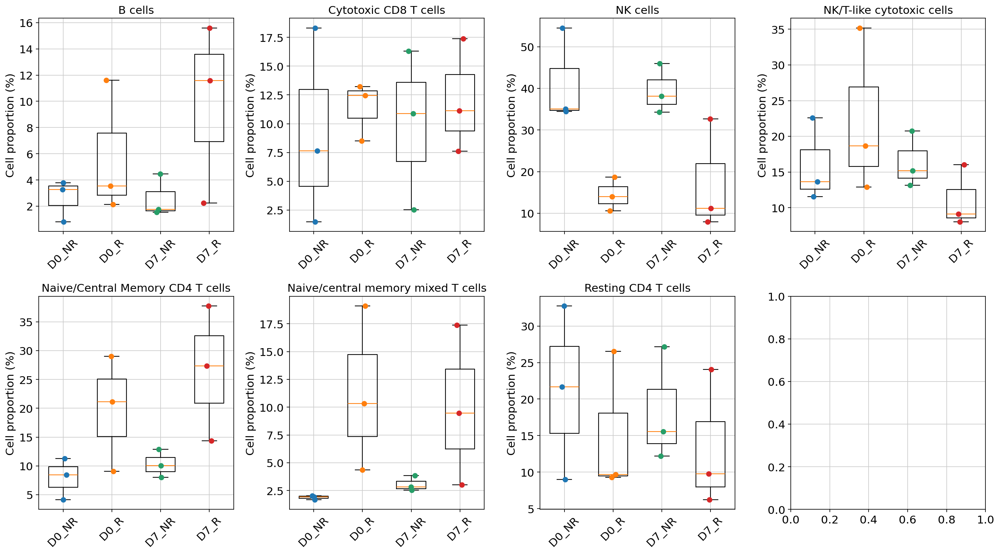

In [ ]:
fig, axes = plt.subplots(
    2,
    4,
    figsize=(18, 10)
)

axes = axes.flatten()

for ax, cell_type in zip(axes, cell_types):

    subset = plot_data[
        plot_data["Cell type"] == cell_type
    ]

    data = [
        subset[
            subset["Condition"] == condition
        ]["Proportion"].values
        for condition in condition_order
    ]

    ax.boxplot(
        data,
        labels=["D0_NR", "D0_R", "D7_NR", "D7_R"],
        widths=0.6
    )

    # Add individual donor points
    for i, condition in enumerate(condition_order, start=1):

        values = subset[
            subset["Condition"] == condition
        ]["Proportion"].values

        x = np.random.normal(
            i,
            0.04,
            size=len(values)
        )

        ax.scatter(
            x,
            values,
            s=35,
            zorder=3
        )

    ax.set_title(cell_type)
    ax.set_ylabel("Cell proportion (%)")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

## 14. B-cell subpopulation analysis


B cells are reprocessed separately to improve resolution of within-lineage variation. Subcluster identities should be supported by coherent marker programs; rare clusters and potential non-B-cell contamination require additional caution.


In [ ]:
bdata = adata[
    adata.obs["cell_type"] == "B cells"
].copy()

print(bdata)

AnnData object with n_obs × n_vars = 4048 × 33538
    obs: 'n_genes', 'total_counts', 'mt_percent', 'Sample', 'Time', 'Donor', 'Response', 'leiden', 'cell_type', 'Time_Group'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'log1p', 'hvg', 'pca', 'neighbors', 'umap', 'leiden', 'rank_genes_groups', 'cell_type_colors'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'
    layers: None (.X), 'counts'


In [ ]:
print(bdata.obs["leiden"].value_counts())

leiden
9    2800
6    1248
Name: count, dtype: int64


In [ ]:
bdata.X = bdata.layers["counts"].copy()

In [ ]:
sc.pp.normalize_total(
    bdata,
    target_sum=1e4
)

sc.pp.log1p(bdata)

In [ ]:
sc.pp.highly_variable_genes(
    bdata,
    n_top_genes=1000
)

In [ ]:
print(bdata.n_obs)
print(bdata.var["highly_variable"].sum())

4048
1000


In [ ]:
sc.tl.pca(
    bdata,
    n_comps=30,
    use_highly_variable=True
)

/tmp/ipykernel_1576/2152963967.py:1: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  sc.tl.pca(


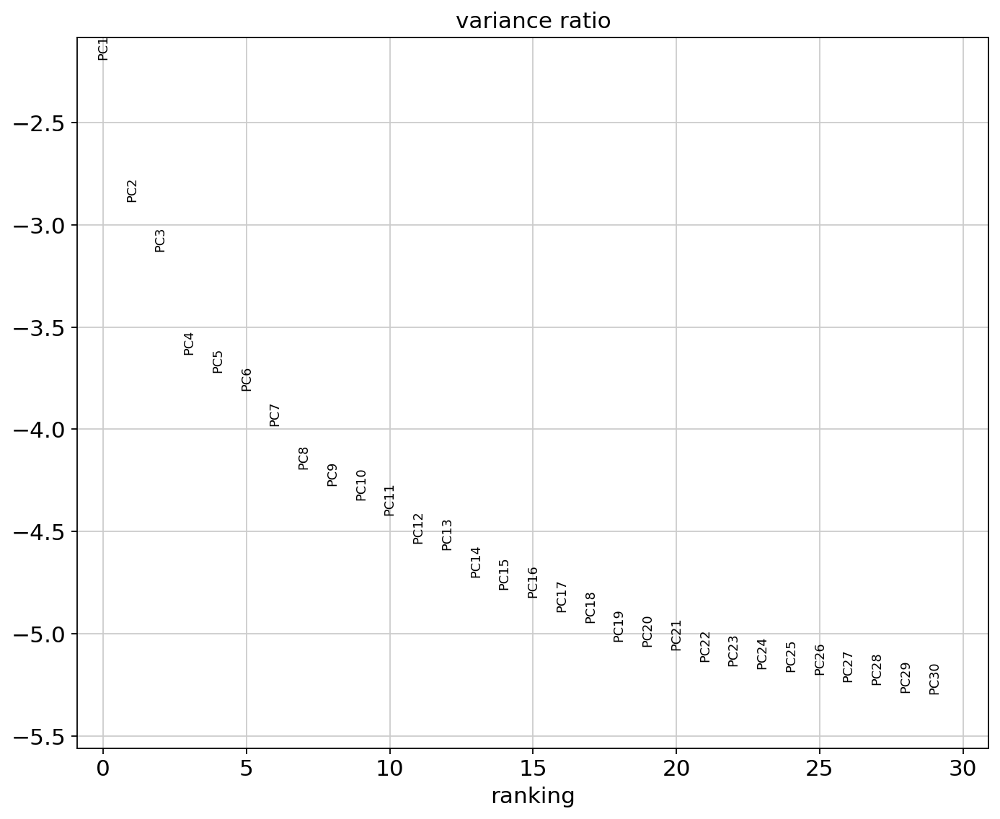

In [ ]:
sc.pl.pca_variance_ratio(
    bdata,
    n_pcs=30,
    log=True
)

In [ ]:
sc.pp.neighbors(
    bdata,
    n_neighbors=15,
    n_pcs=15
)
sc.tl.umap(
    bdata,
    random_state=42
)

In [ ]:
sc.tl.leiden(
    bdata,
    resolution=0.1,
    key_added="bcell_leiden",
    flavor="igraph",
    n_iterations=2,
    directed=False
)

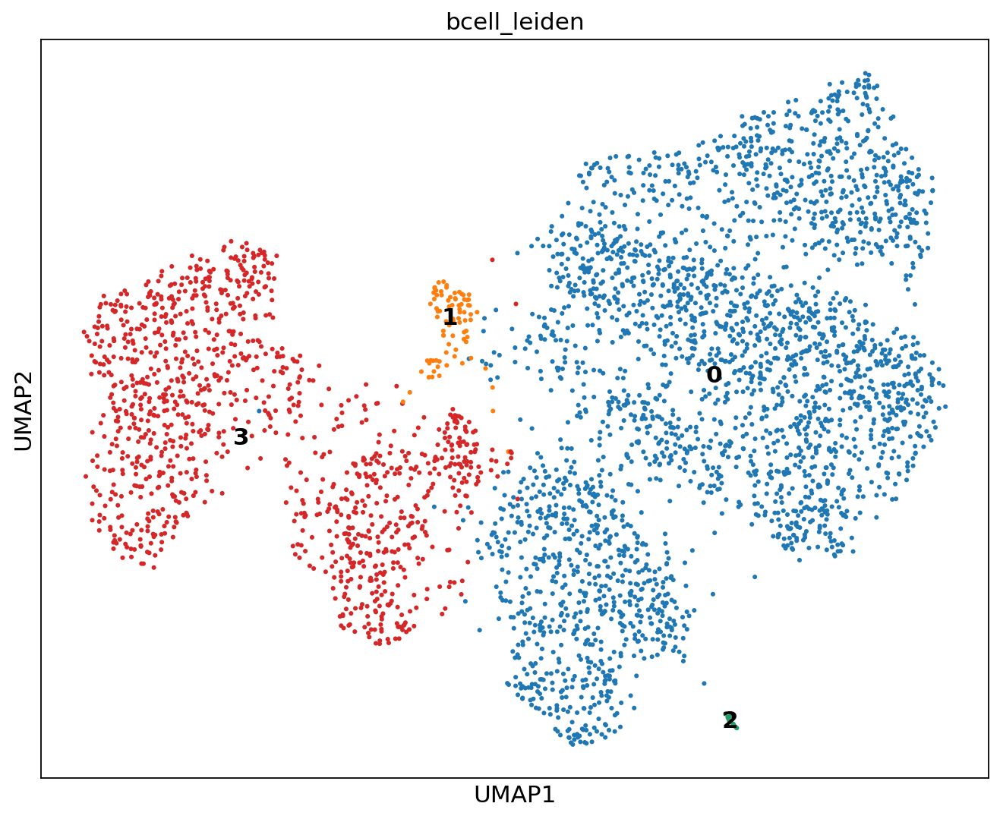

In [ ]:
sc.pl.umap(
    bdata,
    color="bcell_leiden",
    legend_loc="on data"
)

In [ ]:
print(bdata.obs["bcell_leiden"].value_counts().sort_index())

bcell_leiden
0    2813
1      82
2      15
3    1138
Name: count, dtype: int64


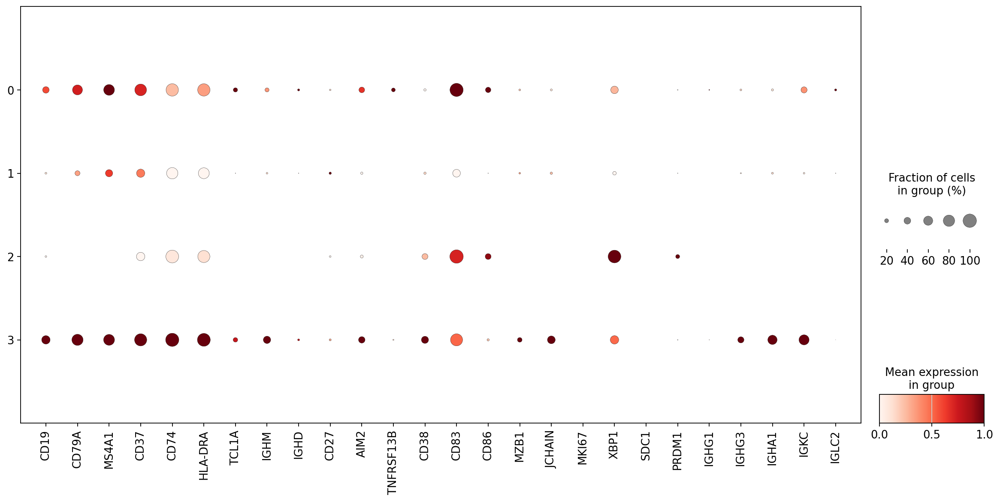

In [ ]:
bcell_markers = [
    "CD19", "CD79A", "MS4A1", "CD37", "CD74", "HLA-DRA",
    "TCL1A", "IGHM", "IGHD",
    "CD27", "AIM2", "TNFRSF13B",
    "CD38", "CD83", "CD86",
    "MZB1", "JCHAIN", "MKI67", "XBP1", "SDC1", "PRDM1",
    "IGHG1", "IGHG3", "IGHA1", "IGKC", "IGLC2"
]

sc.pl.dotplot(
    bdata,
    var_names=bcell_markers,
    groupby="bcell_leiden",
    standard_scale="var",
    figsize=(18, 8)
)

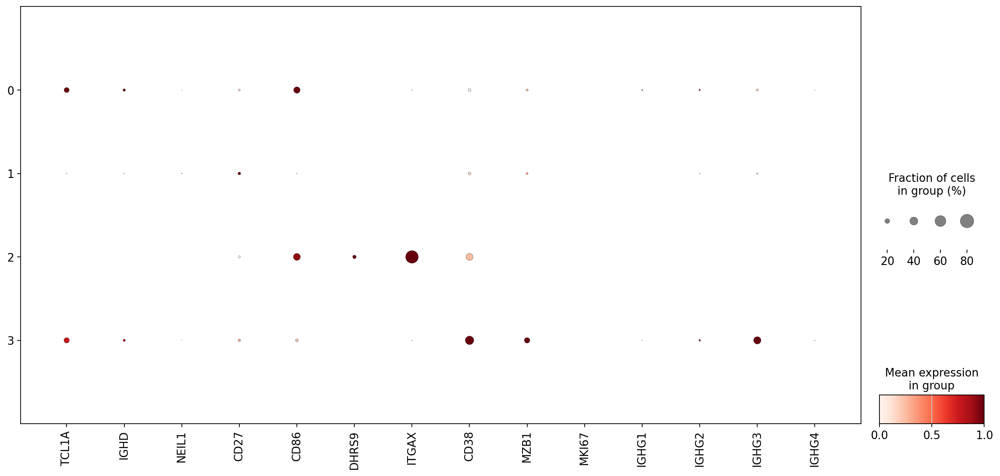

In [ ]:
bcell_markers2 = [
 "TCL1A", "IGHD","NEIL1", "CD27","CD86","DHRS9","ITGAX",
 "CD38","MZB1","MKI67","IGHG1","IGHG2","IGHG3","IGHG4"
]

sc.pl.dotplot(
    bdata,
    var_names=bcell_markers2,
    groupby="bcell_leiden",
    standard_scale="var",
    figsize=(18, 8)
)

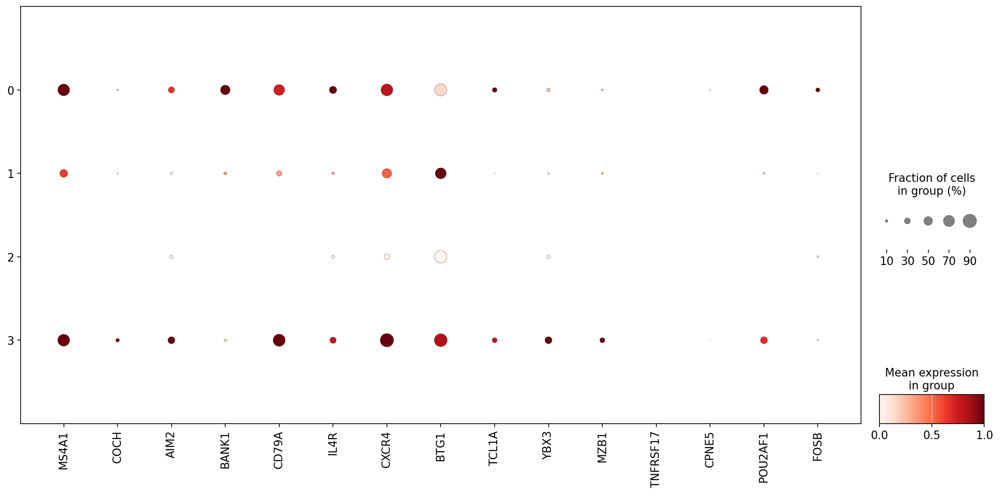

In [ ]:
bcell_markers3 = [
"MS4A1", "COCH", "AIM2", "BANK1", "CD79A",
"IL4R", "CXCR4", "BTG1", "TCL1A", "YBX3",
"MZB1", "TNFRSF17", "CPNE5", "POU2AF1",
"FOSB"
]

sc.pl.dotplot(
    bdata,
    var_names=bcell_markers3,
    groupby="bcell_leiden",
    standard_scale="var",
    figsize=(18, 8)
)

## 15. Differential expression in B-cell subpopulations


Differential-expression results are exploratory. Use adjusted p-values when applying false-discovery-rate criteria and avoid causal or mechanistic claims from this small donor cohort.


In [ ]:
sc.tl.rank_genes_groups(
    bdata,
    groupby = "bcell_leiden",
    method = "wilcoxon"
)

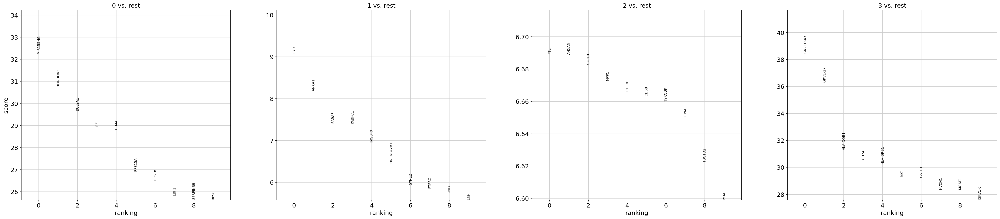

In [ ]:
sc.pl.rank_genes_groups(
    bdata,
    n_genes = 10,
    sharey = False
)

In [ ]:
for cluster in bdata.obs["bcell_leiden"].cat.categories:
    top_genes = bdata.uns["rank_genes_groups"]["names"][cluster][:10]

    print(f"\nCluster {cluster}:")
    print(top_genes)


Cluster 0:
['MIR155HG' 'HLA-DQA2' 'BCL2A1' 'REL' 'CD44' 'RPS15A' 'RPS18' 'EBF1'
 'SERPINB9' 'RPS6']

Cluster 1:
['IL7R' 'ANXA1' 'SARAF' 'PABPC1' 'TMSB4X' 'HNRNPA2B1' 'SYNE2' 'PTPRC'
 'GNLY' 'LBH']

Cluster 2:
['FTL' 'ANXA5' 'CXCL8' 'MPP1' 'PTPRE' 'CD68' 'TYROBP' 'CPM' 'TBC1D2' 'PKM']

Cluster 3:
['IGKV1D-43' 'IGKV1-27' 'HLA-DQB1' 'CD74' 'HLA-DRB1' 'MX1' 'GSTP1' 'HVCN1'
 'MGAT1' 'IGKV1-6']


Cluster 1 and 2 are contaminants from T and Myeloid cells


In [ ]:
# Keep only B-cell clusters 0 and 3
bdata_clean = bdata[
    bdata.obs["bcell_leiden"].isin(["0", "3"])
].copy()

print(bdata_clean)
print(bdata_clean.obs["bcell_leiden"].value_counts())

AnnData object with n_obs × n_vars = 3951 × 33538
    obs: 'n_genes', 'total_counts', 'mt_percent', 'Sample', 'Time', 'Donor', 'Response', 'leiden', 'cell_type', 'Time_Group', 'bcell_leiden'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'log1p', 'hvg', 'pca', 'neighbors', 'umap', 'leiden', 'rank_genes_groups', 'cell_type_colors', 'bcell_leiden', 'bcell_leiden_colors'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'
    layers: None (.X), 'counts'
bcell_leiden
0    2813
3    1138
Name: count, dtype: int64


In [ ]:
# Recalculate B-cell-specific representation
bdata_clean.X = bdata_clean.layers["counts"].copy()

sc.pp.normalize_total(bdata_clean, target_sum=1e4)
sc.pp.log1p(bdata_clean)

sc.pp.highly_variable_genes(
    bdata_clean,
    n_top_genes=1000
)

sc.tl.pca(
    bdata_clean,
    n_comps=30,
    use_highly_variable=True
)

sc.pp.neighbors(
    bdata_clean,
    n_neighbors=15,
    n_pcs=15
)

sc.tl.umap(
    bdata_clean,
    random_state=42
)

/tmp/ipykernel_1576/1854922298.py:12: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  sc.tl.pca(


In [ ]:
sc.tl.leiden(
    bdata_clean,
    resolution=0.3,
    key_added="bcell_leiden",
    flavor="igraph",
    n_iterations=2,
    directed=False
)

print(bdata_clean.obs["bcell_leiden"].value_counts())

bcell_leiden
1    1220
5     703
2     679
0     546
4     432
3     371
Name: count, dtype: int64


In [ ]:
sc.tl.rank_genes_groups(
    bdata_clean,
    groupby = "bcell_leiden",
    method = "wilcoxon"
)

In [ ]:
for cluster in bdata_clean.obs["bcell_leiden"].cat.categories:
    top_genes = bdata_clean.uns["rank_genes_groups"]["names"][cluster][:10]

    print(f"\nCluster {cluster}:")
    print(top_genes)


Cluster 0:
['EIF1' 'CD200' 'BCL2A1' 'ZFAS1' 'RPS19' 'RPL12' 'TCL1A' 'FTH1' 'CREM'
 'GPX4']

Cluster 1:
['RPSA' 'RPL7A' 'EEF1A1' 'RPS3' 'RPS21' 'RPL7' 'RPS16' 'RPLP2' 'RPS6'
 'FABP5']

Cluster 2:
['MALAT1' 'MT-ND2' 'MT-CO3' 'MT-CO2' 'MT-ATP6' 'MT-CYB' 'MT-ND4L' 'MT-CO1'
 'MT-ND1' 'MTRNR2L12']

Cluster 3:
['LY6E' 'ISG15' 'IFITM1' 'LAPTM5' 'IRF7' 'IFIT3' 'PLSCR1' 'IFI6' 'SP110'
 'IFITM2']

Cluster 4:
['NEAT1' 'MT-CO1' 'MALAT1' 'MT-CO3' 'SLC38A2' 'MT-CYB' 'MT-CO2' 'STAT2'
 'USP15' 'MT-ND4L']

Cluster 5:
['IGKV1D-43' 'GSTP1' 'IGKV1-27' 'RPS26' 'CD74' 'MYL6' 'HLA-DQB1' 'IGKV1-6'
 'RILPL2' 'ATOX1']


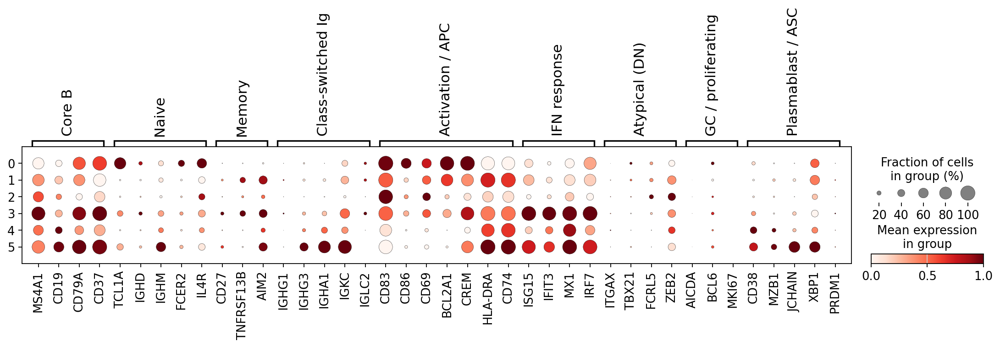

In [ ]:
bcell_sub_markers = {
    "Core B": ["MS4A1", "CD19", "CD79A", "CD37"],
    "Naive": ["TCL1A", "IGHD", "IGHM", "FCER2", "IL4R"],
    "Memory": ["CD27", "TNFRSF13B", "AIM2"],
    "Class-switched Ig": ["IGHG1", "IGHG3", "IGHA1", "IGKC", "IGLC2"],
    "Activation / APC": ["CD83", "CD86", "CD69", "BCL2A1", "CREM", "HLA-DRA", "CD74"],
    "IFN response": ["ISG15", "IFIT3", "MX1", "IRF7"],
    "Atypical (DN)": ["ITGAX", "TBX21", "FCRL5", "ZEB2"],
    "GC / proliferating": ["AICDA", "BCL6", "MKI67"],
    "Plasmablast / ASC": ["CD38", "MZB1", "JCHAIN", "XBP1", "PRDM1"],
}

# keep only genes present in the object
bcell_sub_markers = {k: [g for g in v if g in bdata_clean.var_names]
                     for k, v in bcell_sub_markers.items()}

sc.pl.dotplot(bdata_clean, bcell_sub_markers, groupby="bcell_leiden",
              standard_scale="var", dendrogram=False)

In [ ]:
cluster_names = {
    "0": "Activated Naive B cells",
    "1": "Activated B cells (High-ribosomal)",
    "2": "Stressed / low-RNA",
    "3": "IFN-responsive B cells",
    "4": "Stressed / low-RNA",
    "5": "Class-switched Plasmablasts / Antibody Secreting"
}

bdata_clean.obs["bcell_type"] = (
    bdata_clean.obs["bcell_leiden"].map(cluster_names).astype("category")
)

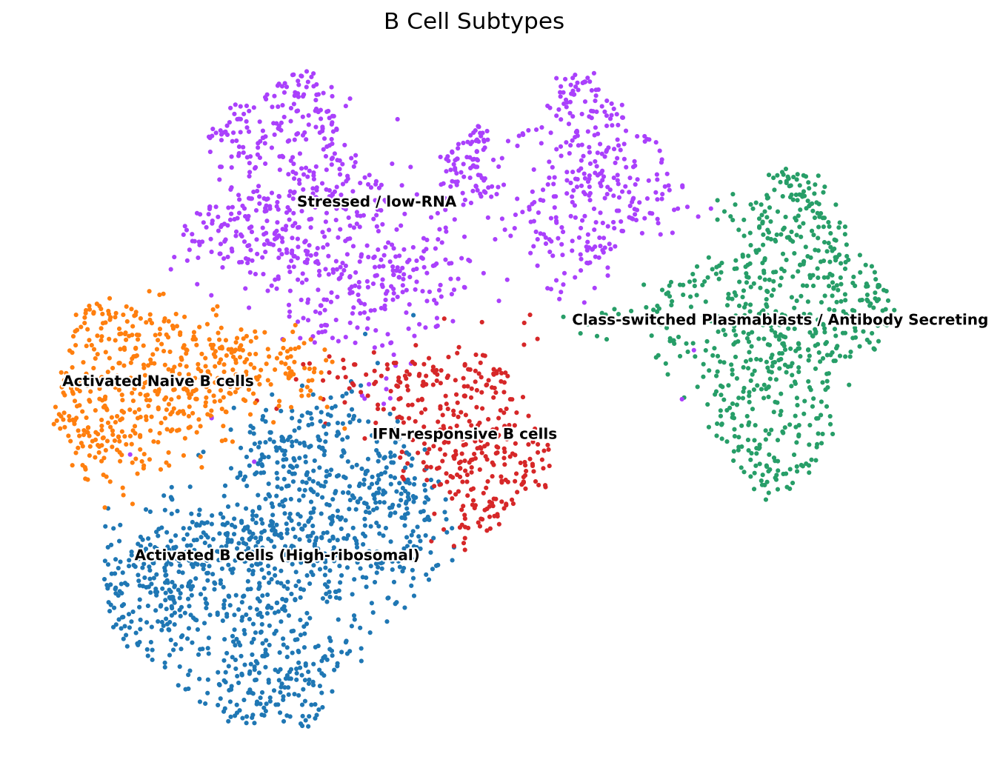

In [ ]:
# 3. Plot UMAP side-by-side (Cluster IDs vs Cell Type Labels)
sc.pl.umap(
    bdata_clean,
    color="bcell_type",
    legend_loc="on data",
    legend_fontsize=9,
    legend_fontoutline=2,
    frameon=False,
    title="B Cell Subtypes",
    wspace=0.35,
)

/usr/local/lib/python3.13/dist-packages/scanpy/plotting/_utils.py:509: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list
/usr/local/lib/python3.13/dist-packages/scanpy/plotting/_utils.py:509: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


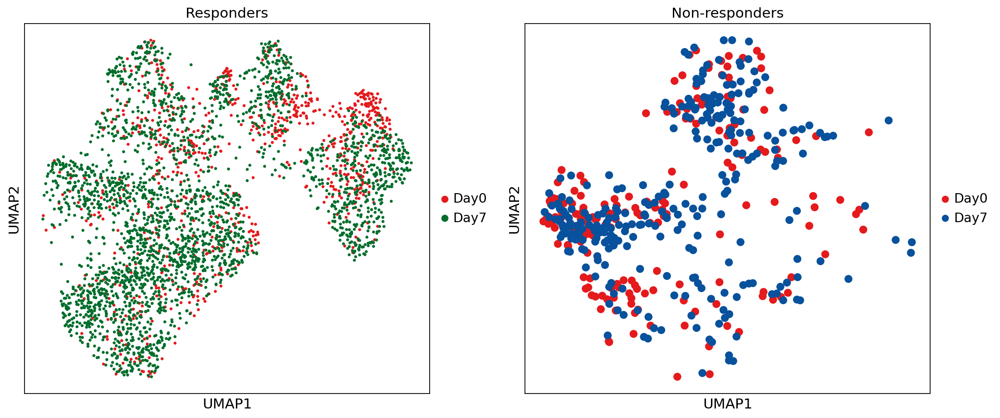

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Responders
sc.pl.umap(
    bdata_clean[bdata_clean.obs["Response"] == "Responder"],
    color="Time_Group",
    palette=["#E41A1C", "#006D2C"],
    title="Responders",
    ax=axes[0],
    show=False,
    legend_loc="right margin"
)

# Non-responders
sc.pl.umap(
    bdata_clean[bdata_clean.obs["Response"] == "Non-responder"],
    color="Time_Group",
    palette=["#E41A1C", "#08519C"],
    title="Non-responders",
    ax=axes[1],
    show=False,
    legend_loc="right margin"
)

plt.tight_layout()
plt.show()

In [ ]:
print(bdata_clean.obs["Response"].value_counts())
print(bdata_clean.obs["Time_Group"].value_counts())
print(
    pd.crosstab(
        bdata_clean.obs["Response"],
        bdata_clean.obs["Time_Group"]
    )
)

Response
Responder        3467
Non-responder     484
Name: count, dtype: int64
Time_Group
Day7    2923
Day0    1028
Name: count, dtype: int64
Time_Group     Day0  Day7
Response                 
Non-responder   191   293
Responder       837  2630


Non-responders have very few B cells
## B-cell Subpopulation Composition by Response and Time

Does the composition of B-cell subpopulations differ between responders and non-responders, and does it change from D0 to D7?

In [ ]:
#Six populations
print(bdata_clean.obs["bcell_type"].value_counts())

bcell_type
Activated B cells (High-ribosomal)                  1220
Stressed / low-RNA                                  1111
Class-switched Plasmablasts / Antibody Secreting     703
Activated Naive B cells                              546
IFN-responsive B cells                               371
Name: count, dtype: int64


In [ ]:
print(
    pd.crosstab(
        bdata_clean.obs["Response"],
        bdata_clean.obs["bcell_type"]
    )
)

bcell_type     Activated B cells (High-ribosomal)  Activated Naive B cells  \
Response                                                                     
Non-responder                                 114                      195   
Responder                                    1106                      351   

bcell_type     Class-switched Plasmablasts / Antibody Secreting  \
Response                                                          
Non-responder                                                 0   
Responder                                                   703   

bcell_type     IFN-responsive B cells  Stressed / low-RNA  
Response                                                   
Non-responder                      14                 161  
Responder                         357                 950  


In [ ]:
print(
    pd.crosstab(
        [bdata_clean.obs["Response"], bdata_clean.obs["Time_Group"]],
        bdata_clean.obs["bcell_type"]
    )
)

bcell_type                Activated B cells (High-ribosomal)  \
Response      Time_Group                                       
Non-responder Day0                                        52   
              Day7                                        62   
Responder     Day0                                       132   
              Day7                                       974   

bcell_type                Activated Naive B cells  \
Response      Time_Group                            
Non-responder Day0                             80   
              Day7                            115   
Responder     Day0                             45   
              Day7                            306   

bcell_type                Class-switched Plasmablasts / Antibody Secreting  \
Response      Time_Group                                                     
Non-responder Day0                                                       0   
              Day7                                            

In [ ]:
# Count B-cell subtypes for each donor and timepoint
bcell_counts = (
    bdata_clean.obs
    .groupby(["Donor", "Response", "Time_Group", "bcell_type"], observed=True)
    .size()
    .reset_index(name="n_cells")
)

print(bcell_counts)

   Donor       Response Time_Group  \
0    NR1  Non-responder       Day0   
1    NR1  Non-responder       Day0   
2    NR1  Non-responder       Day0   
3    NR1  Non-responder       Day7   
4    NR1  Non-responder       Day7   
5    NR1  Non-responder       Day7   
6    NR1  Non-responder       Day7   
7    NR2  Non-responder       Day0   
8    NR2  Non-responder       Day0   
9    NR2  Non-responder       Day0   
10   NR2  Non-responder       Day0   
11   NR2  Non-responder       Day7   
12   NR2  Non-responder       Day7   
13   NR2  Non-responder       Day7   
14   NR2  Non-responder       Day7   
15   NR3  Non-responder       Day0   
16   NR3  Non-responder       Day0   
17   NR3  Non-responder       Day0   
18   NR3  Non-responder       Day0   
19   NR3  Non-responder       Day7   
20   NR3  Non-responder       Day7   
21   NR3  Non-responder       Day7   
22   NR3  Non-responder       Day7   
23    R1      Responder       Day0   
24    R1      Responder       Day0   
25    R1    

In [ ]:
# Total B cells per donor and timepoint
bcell_counts["total_bcells"] = (
    bcell_counts
    .groupby(["Donor", "Response", "Time_Group"])["n_cells"]
    .transform("sum")
)

# Proportion of each B-cell subtype
bcell_counts["proportion"] = (
    bcell_counts["n_cells"] / bcell_counts["total_bcells"]
)

print(bcell_counts)

   Donor       Response Time_Group  \
0    NR1  Non-responder       Day0   
1    NR1  Non-responder       Day0   
2    NR1  Non-responder       Day0   
3    NR1  Non-responder       Day7   
4    NR1  Non-responder       Day7   
5    NR1  Non-responder       Day7   
6    NR1  Non-responder       Day7   
7    NR2  Non-responder       Day0   
8    NR2  Non-responder       Day0   
9    NR2  Non-responder       Day0   
10   NR2  Non-responder       Day0   
11   NR2  Non-responder       Day7   
12   NR2  Non-responder       Day7   
13   NR2  Non-responder       Day7   
14   NR2  Non-responder       Day7   
15   NR3  Non-responder       Day0   
16   NR3  Non-responder       Day0   
17   NR3  Non-responder       Day0   
18   NR3  Non-responder       Day0   
19   NR3  Non-responder       Day7   
20   NR3  Non-responder       Day7   
21   NR3  Non-responder       Day7   
22   NR3  Non-responder       Day7   
23    R1      Responder       Day0   
24    R1      Responder       Day0   
25    R1    

A substantial plasmablast population was detected in one responder donor at D7, whereas no plasmablast cells were detected in the three non-responder donors.

In [ ]:
# Create complete donor × time × B-cell type table
bcell_prop = (
    bcell_counts
    .pivot_table(
        index=["Donor", "Response", "Time_Group"],
        columns="bcell_type",
        values="proportion",
        fill_value=0
    )
    .reset_index()
)

print(bcell_prop)

bcell_type Donor       Response Time_Group  \
0            NR1  Non-responder       Day0   
1            NR1  Non-responder       Day7   
2            NR2  Non-responder       Day0   
3            NR2  Non-responder       Day7   
4            NR3  Non-responder       Day0   
5            NR3  Non-responder       Day7   
6             R1      Responder       Day0   
7             R1      Responder       Day7   
8             R2      Responder       Day0   
9             R2      Responder       Day7   
10            R3      Responder       Day0   
11            R3      Responder       Day7   

bcell_type  Activated B cells (High-ribosomal)  Activated Naive B cells  \
0                                     0.555556                 0.333333   
1                                     0.323529                 0.411765   
2                                     0.010526                 0.684211   
3                                     0.047904                 0.532934   
4                         

In [ ]:
print(bcell_prop.shape)
print(bcell_prop.columns.tolist())

(12, 8)
['Donor', 'Response', 'Time_Group', 'Activated B cells (High-ribosomal)', 'Activated Naive B cells', 'Class-switched Plasmablasts / Antibody Secreting', 'IFN-responsive B cells', 'Stressed / low-RNA']


In [ ]:
subtype_cols = [
    "Activated B cells (High-ribosomal)",
    "Activated Naive B cells",
    "Class-switched Plasmablasts / Antibody Secreting",
    "IFN-responsive B cells",
    "Stressed / low-RNA"
]

print(bcell_prop[subtype_cols].sum(axis=1))

0     1.0
1     1.0
2     1.0
3     1.0
4     1.0
5     1.0
6     1.0
7     1.0
8     1.0
9     1.0
10    1.0
11    1.0
dtype: float64


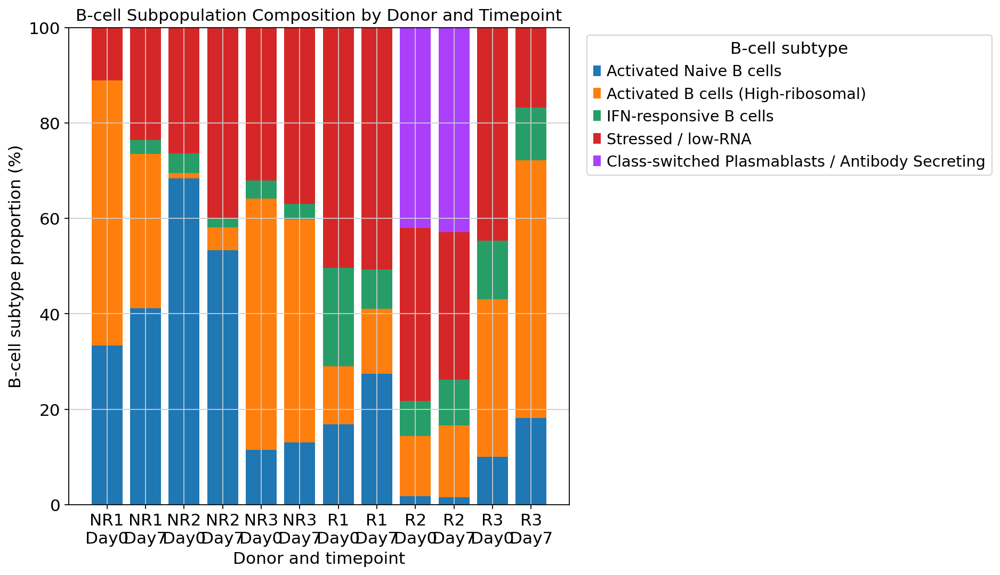

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Order donors by response group
donor_order = [
    "NR1", "NR2", "NR3",
    "R1", "R2", "R3"
]

# Make sure columns are in the desired order
subtype_cols = [
    "Activated Naive B cells",
    "Activated B cells (High-ribosomal)",
    "IFN-responsive B cells",
    "Stressed / low-RNA",
    "Class-switched Plasmablasts / Antibody Secreting"
]

# Create a plotting dataframe
plot_df = bcell_prop.copy()

plot_df["Donor"] = pd.Categorical(
    plot_df["Donor"],
    categories=donor_order,
    ordered=True
)

# Sort donor and timepoint
plot_df["Time_order"] = plot_df["Time_Group"].map({
    "Day0": 0,
    "Day7": 1
})

plot_df = plot_df.sort_values(["Donor", "Time_order"])

# Plot
fig, ax = plt.subplots(figsize=(12, 7))

x = np.arange(len(plot_df))
bottom = np.zeros(len(plot_df))

for subtype in subtype_cols:
    values = plot_df[subtype].values * 100

    ax.bar(
        x,
        values,
        bottom=bottom,
        label=subtype
    )

    bottom += values

# X-axis labels
ax.set_xticks(x)
ax.set_xticklabels(
    [f"{d}\n{t}" for d, t in zip(
        plot_df["Donor"],
        plot_df["Time_Group"]
    )]
)

ax.set_ylabel("B-cell subtype proportion (%)")
ax.set_xlabel("Donor and timepoint")
ax.set_ylim(0, 100)

ax.set_title(
    "B-cell Subpopulation Composition by Donor and Timepoint"
)

ax.legend(
    title="B-cell subtype",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

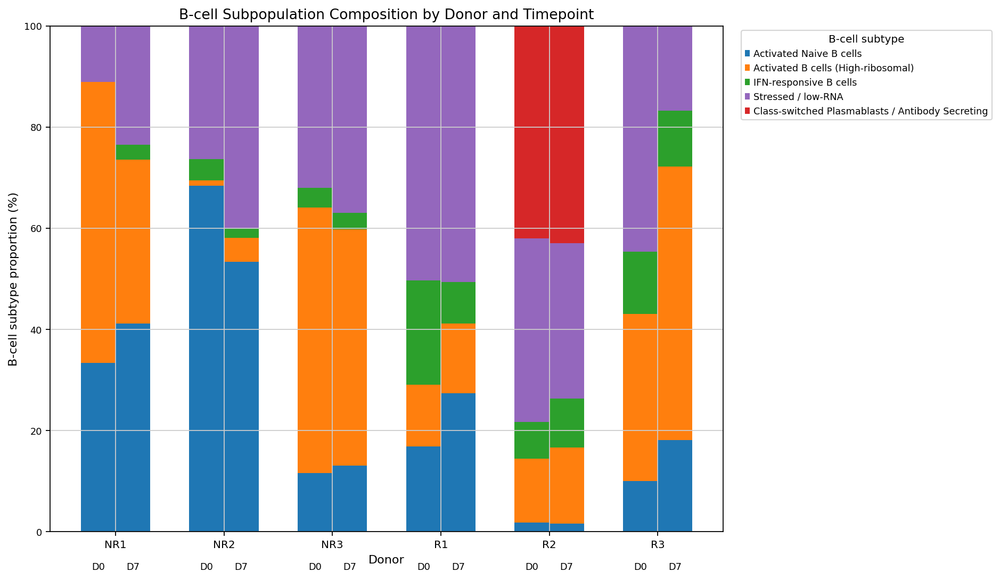

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Order donors by response group
donor_order = [
    "NR1", "NR2", "NR3",
    "R1", "R2", "R3"
]

# Fixed subtype order
subtype_cols = [
    "Activated Naive B cells",
    "Activated B cells (High-ribosomal)",
    "IFN-responsive B cells",
    "Stressed / low-RNA",
    "Class-switched Plasmablasts / Antibody Secreting"
]

# Fixed colors for each cell type
# The same subtype will always have the same color
subtype_colors = {
    "Activated Naive B cells": "#1f77b4",
    "Activated B cells (High-ribosomal)": "#ff7f0e",
    "IFN-responsive B cells": "#2ca02c",
    "Stressed / low-RNA": "#9467bd",
    "Class-switched Plasmablasts / Antibody Secreting": "#d62728"
}

plot_df = bcell_prop.copy()

plot_df["Donor"] = pd.Categorical(
    plot_df["Donor"],
    categories=donor_order,
    ordered=True
)

plot_df["Time_order"] = plot_df["Time_Group"].map({
    "Day0": 0,
    "Day7": 1
})

plot_df = plot_df.sort_values(["Donor", "Time_order"])

# Create figure
fig, ax = plt.subplots(figsize=(12, 7))

n_donors = len(donor_order)

x = np.arange(n_donors)
bar_width = 0.32

# Positions of D0 and D7 bars
x_d0 = x - bar_width / 2
x_d7 = x + bar_width / 2

# Plot D0 and D7
for timepoint, xpos in [
    ("Day0", x_d0),
    ("Day7", x_d7)
]:

    time_df = (
        plot_df[plot_df["Time_Group"] == timepoint]
        .set_index("Donor")
        .reindex(donor_order)
    )

    bottom = np.zeros(n_donors)

    for subtype in subtype_cols:

        values = (
            time_df[subtype]
            .fillna(0)
            .values * 100
        )

        ax.bar(
            xpos,
            values,
            width=bar_width,
            bottom=bottom,
            color=subtype_colors[subtype],
            label=subtype if timepoint == "Day0" else None
        )

        bottom += values

# Donor labels
ax.set_xticks(x)

ax.set_xticklabels(
    donor_order,
    fontsize=9
)

# D0 / D7 labels underneath each donor
for i, donor in enumerate(donor_order):

    ax.text(
        x_d0[i],
        -6,
        "D0",
        ha="center",
        va="top",
        fontsize=8
    )

    ax.text(
        x_d7[i],
        -6,
        "D7",
        ha="center",
        va="top",
        fontsize=8
    )

# Axis labels
ax.set_xlabel(
    "Donor",
    fontsize=10
)

ax.set_ylabel(
    "B-cell subtype proportion (%)",
    fontsize=10
)

# Y-axis
ax.set_ylim(0, 100)

ax.tick_params(
    axis="y",
    labelsize=8
)

# Title
ax.set_title(
    "B-cell Subpopulation Composition by Donor and Timepoint",
    fontsize=12
)

# Legend
ax.legend(
    title="B-cell subtype",
    title_fontsize=9,
    fontsize=8,
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

## 16. B-cell transcriptional response


In [ ]:
# Key genes relevant to B-cell activation, antigen presentation,
# interferon response, and plasma-cell differentiation

candidate_genes = [
    # B-cell activation
    "CD69", "CD80", "CD86", "CD40",

    # Antigen presentation
    "HLA-DRA", "HLA-DRB1", "CD74",
    "HLA-DPA1", "HLA-DPB1",

    # Interferon response
    "ISG15", "IFITM1", "IFITM3",
    "IFI6", "IFIT1", "IFIT3",
    "MX1", "OAS1",

    # Plasma-cell / ASC differentiation
    "MZB1", "JCHAIN", "XBP1",
    "PRDM1", "SDC1", "TNFRSF17",

    # Proliferation
    "MKI67"
]

# Keep only genes that are actually present in the dataset
available_genes = [
    gene for gene in candidate_genes
    if gene in bdata_clean.var_names
]

print("Genes found in dataset:")
print(available_genes)

print("\nGenes not found:")
print([
    gene for gene in candidate_genes
    if gene not in bdata_clean.var_names
])

Genes found in dataset:
['CD69', 'CD80', 'CD86', 'CD40', 'HLA-DRA', 'HLA-DRB1', 'CD74', 'HLA-DPA1', 'HLA-DPB1', 'ISG15', 'IFITM1', 'IFITM3', 'IFI6', 'IFIT1', 'IFIT3', 'MX1', 'OAS1', 'MZB1', 'JCHAIN', 'XBP1', 'PRDM1', 'SDC1', 'TNFRSF17', 'MKI67']

Genes not found:
[]


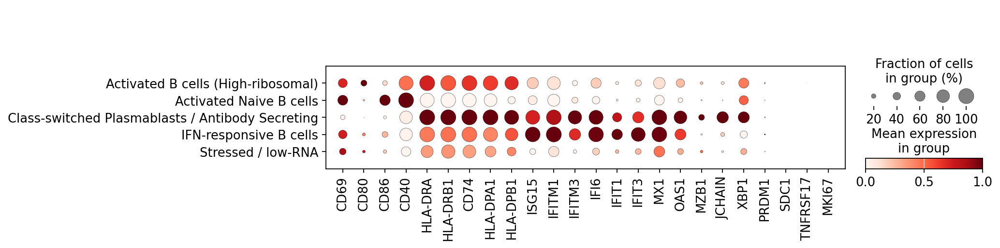

In [ ]:
sc.pl.dotplot(
    bdata_clean,
    var_names=available_genes,
    groupby="bcell_type",
    standard_scale="var"
)

In [ ]:
# Find marker genes for each B-cell subtype
sc.tl.rank_genes_groups(
    bdata_clean,
    groupby="bcell_type",
    method="wilcoxon"
)

In [ ]:
plasma_markers = sc.get.rank_genes_groups_df(
    bdata_clean,
    group="Class-switched Plasmablasts / Antibody Secreting"
)

print(plasma_markers.head(30))

        names     scores  logfoldchanges          pvals      pvals_adj
0   IGKV1D-43  36.578655        5.515894  6.249212e-293  2.095861e-288
1       GSTP1  36.511120        3.425422  7.387749e-292  1.238852e-287
2    IGKV1-27  35.346935        5.428607  1.117350e-273  1.249123e-269
3       RPS26  32.192677        1.445382  2.234716e-227  1.873698e-223
4        CD74  31.196608        2.374022  1.184550e-213  7.945489e-210
5        MYL6  31.058180        1.861051  8.847246e-212  4.945316e-208
6    HLA-DQB1  29.957104        2.262733  3.555755e-197  1.703613e-193
7     IGKV1-6  29.361639        4.825944  1.697284e-189  7.115439e-186
8      RILPL2  29.075739        2.295396  7.276344e-186  2.711489e-182
9       ATOX1  28.785173        2.401983  3.288839e-182  1.103011e-178
10     IFITM3  28.449114        3.428949  4.997584e-178  1.523718e-174
11      IGHA1  28.399921        3.806027  2.026681e-177  5.664237e-174
12   HLA-DRB1  27.844879        1.946064  1.242454e-170  3.205341e-167
13    

In [ ]:
# Get marker genes for all B-cell populations
marker_results = sc.get.rank_genes_groups_df(
    bdata_clean,
    group=None
)

# Show top 10 markers for each B-cell subtype
for cell_type in bdata_clean.obs["bcell_type"].cat.categories:

    print("\n==============================")
    print(cell_type)
    print("==============================")

    markers = marker_results[
        marker_results["group"] == cell_type
    ].head(10)

    print(
        markers[
            ["names", "scores", "logfoldchanges", "pvals_adj"]
        ]
    )


Activated B cells (High-ribosomal)
    names     scores  logfoldchanges      pvals_adj
0    RPSA  33.794083        1.543209  8.080172e-246
1   RPL7A  33.441978        1.347964  5.645284e-241
2  EEF1A1  32.763084        1.232043  2.210198e-231
3    RPS3  32.431042        1.318245  8.405283e-227
4   RPS21  32.330032        1.474409  1.776137e-225
5    RPL7  32.168114        1.761438  2.755503e-223
6   RPS16  31.874865        1.594578  2.853604e-219
7   RPLP2  31.846533        1.394554  6.163303e-219
8    RPS6  31.692148        1.475894  7.427471e-217
9   FABP5  30.966568        3.136555  5.099052e-207

Activated Naive B cells
        names     scores  logfoldchanges      pvals_adj
33538    EIF1  27.860352        1.145139  2.706612e-166
33539   CD200  27.728319        3.436232  5.335709e-165
33540  BCL2A1  26.887434        2.895596  3.443921e-155
33541   ZFAS1  26.165546        2.075121  5.498792e-147
33542   RPS19  24.634499        1.216806  2.585020e-130
33543   RPL12  24.543346       

In [ ]:
# Combine Response status and Timepoint into a single metadata column
# Adjust column names ('response' and 'timepoint') to match your adata.obs
bdata_clean.obs["condition_group"] = (
    bdata_clean.obs["Response"].astype(str)
    + "_"
    + bdata_clean.obs["Time_Group"].astype(str)
)
# Example values in condition_group: 'R_D0', 'NR_D0', 'R_D7', 'NR_D7'

In [ ]:
print(bdata_clean.obs_keys)

<bound method AnnData.obs_keys of AnnData object with n_obs × n_vars = 3951 × 33538
    obs: 'n_genes', 'total_counts', 'mt_percent', 'Sample', 'Time', 'Donor', 'Response', 'leiden', 'cell_type', 'Time_Group', 'bcell_leiden', 'bcell_type', 'condition_group'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'log1p', 'hvg', 'pca', 'neighbors', 'umap', 'leiden', 'rank_genes_groups', 'cell_type_colors', 'bcell_leiden', 'bcell_leiden_colors', 'bcell_type_colors'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'
    layers: None (.X), 'counts'>


In [ ]:
print(bdata_clean.obs.Response)

CATTATCCAGCTTCGG-1-Day0_NR1    Non-responder
CCTTACGAGGCAGGTT-1-Day0_NR1    Non-responder
CGTCACTCAATAGCGG-1-Day0_NR1    Non-responder
CTAACTTAGATCTGCT-1-Day0_NR1    Non-responder
CTCGGAGAGTAGGCCA-1-Day0_NR1    Non-responder
                                   ...      
TTTGCGCTCTGCGGCA-1-Day7_R3         Responder
TTTGGTTAGATCCTGT-1-Day7_R3         Responder
TTTGGTTGTTGTCTTT-1-Day7_R3         Responder
TTTGTCACACCAACCG-1-Day7_R3         Responder
TTTGTCACAGTCCTTC-1-Day7_R3         Responder
Name: Response, Length: 3951, dtype: category
Categories (2, str): ['Non-responder', 'Responder']


In [ ]:
# Select a subtype to test (e.g., IFN-responsive B cells or Activated Naive)
target_subtype = "IFN-responsive B cells"

# Subset the AnnData object to that specific cell type at Day 7
sub_adata = bdata_clean[
    (bdata_clean.obs["bcell_type"] == target_subtype)
    & (bdata_clean.obs["Time"] == "Day7")
].copy()

# Run Wilcoxon rank-sum test between Responders (R) and Non-Responders (NR)
sc.tl.rank_genes_groups(
    sub_adata,
    groupby="Response",
    reference="Non-responder",  # Non-Responders as baseline
    method="wilcoxon",
    pts=True,
)

# Format the differential expression results into a Pandas DataFrame
deg_df = sc.get.rank_genes_groups_df(sub_adata, group="Responder")
deg_df["abs_logfc"] = deg_df["logfoldchanges"].abs()

# Filter for significant DEGs (p_adj <= 0.05 and |log2FC| >= 0.25)
sig_degs = deg_df[
    (deg_df["pvals"] <= 0.05) & (deg_df["abs_logfc"] >= 0.25)
].sort_values("logfoldchanges", ascending=False)

In [ ]:
print(sig_degs.columns.tolist())

['names', 'scores', 'logfoldchanges', 'pvals', 'pvals_adj', 'pct_nz_group', 'abs_logfc']


In [ ]:
print(f"Top DEGs in {target_subtype} (Responders vs Non-Responders at Day 7):")
print(
    sig_degs[
        [
            "names",
            "logfoldchanges",
            "pvals_adj",
            "pct_nz_group",
            "scores",
        ]
    ].head(10)
)

Top DEGs in IFN-responsive B cells (Responders vs Non-Responders at Day 7):
      names  logfoldchanges  pvals_adj  pct_nz_group    scores
11    KLHL6       30.005686        1.0      0.533088  2.407765
25   PARP15       29.506405        1.0      0.488971  2.208502
21    ZMYM2       29.461126        1.0      0.492647  2.225107
37  GRIPAP1       29.311113        1.0      0.466912  2.108871
42    CELF1       29.215418        1.0      0.452206  2.042449
49    KPNA1       29.185350        1.0      0.444853  2.009239
7    ABLIM1        3.588313        1.0      0.658088  2.666333
18  AKIRIN2        3.285501        1.0      0.569853  2.244085
38  MATR3-1        3.085935        1.0      0.540441  2.101754
50   ATP5PB        3.040519        1.0      0.518382  2.006867


/tmp/ipykernel_1576/2219564279.py:50: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/tmp/ipykernel_1576/2219564279.py:78: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(
/tmp/ipykernel_1576/2219564279.py:50: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/tmp/ipykernel_1576/2219564279.py:78: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(
/tmp/ipykernel_1576/2219564279.py:50: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Ass

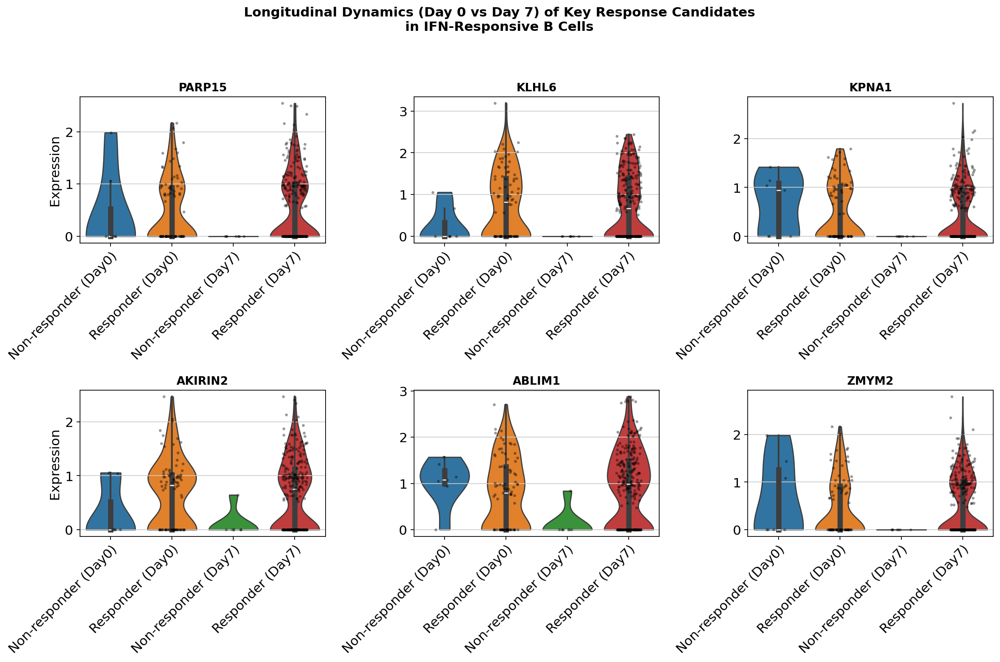

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import scipy.sparse as sp
import seaborn as sns

# 1. Subset IFN-responsive B cells
ifn_adata = bdata_clean[
    bdata_clean.obs["bcell_type"] == "IFN-responsive B cells"
].copy()

# 2. Create combined group label string
ifn_adata.obs["Group_Time"] = (
    ifn_adata.obs["Response"].astype(str)
    + " ("
    + ifn_adata.obs["Time"].astype(str)
    + ")"
)

# 3. Define explicit category order
ordered_categories = [
    "Non-responder (Day0)",
    "Responder (Day0)",
    "Non-responder (Day7)",
    "Responder (Day7)",
]

# 4. Extract gene expression into a single Pandas DataFrame
top_candidates = ["PARP15", "KLHL6", "KPNA1", "AKIRIN2", "ABLIM1", "ZMYM2"]
plot_df = ifn_adata.obs[["Group_Time"]].copy()

for gene in top_candidates:
    expr = ifn_adata[:, gene].X
    if sp.issparse(expr):
        expr = expr.toarray()
    plot_df[gene] = expr.flatten()

# Filter out any unassigned/missing categories
plot_df = plot_df[plot_df["Group_Time"].isin(ordered_categories)]

# 5. Create 2x3 Grid Plot using Seaborn directly
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

palette = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]  # Distinct colors per group

for i, gene in enumerate(top_candidates):
    ax = axes[i]

    # Draw Violins
    sns.violinplot(
        data=plot_df,
        x="Group_Time",
        y=gene,
        order=ordered_categories,
        palette=palette,
        ax=ax,
        inner="box",
        cut=0,
    )

    # Overlay Jitter Dots directly on top
    sns.stripplot(
        data=plot_df,
        x="Group_Time",
        y=gene,
        order=ordered_categories,
        color="black",
        alpha=0.4,
        size=3,
        jitter=0.2,
        ax=ax,
    )

    # Formatting
    ax.set_title(gene, fontsize=12, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("Expression" if i % 3 == 0 else "")
    ax.set_xticklabels(
        ordered_categories, rotation=45, ha="right", rotation_mode="anchor"
    )

fig.suptitle(
    "Longitudinal Dynamics (Day 0 vs Day 7) of Key Response Candidates\nin IFN-Responsive B Cells",
    fontsize=14,
    fontweight="bold",
    y=0.98,
)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

## 17. Differential-expression summaries across B-cell subpopulations


In [ ]:
import pandas as pd
import scanpy as sc

# Dictionary to store the full top 10 DataFrame per cell type
top10_per_subtype = {}
summary_list = []

# Iterate over each annotated B cell subtype
for subtype in bdata_clean.obs["bcell_type"].unique():
    # 1. Subset to the current cell subtype at Day 7
    sub_adata = bdata_clean[
        (bdata_clean.obs["bcell_type"] == subtype)
        & (bdata_clean.obs["Time"] == "Day7")
    ].copy()

    # Skip if either condition is completely missing cells
    groups_present = sub_adata.obs["Response"].unique()
    if "Responder" not in groups_present or "Non-responder" not in groups_present:
        print(
            f"Skipping {subtype}: missing one or both groups at Day 7.\n"
        )
        continue

    # 2. Run Wilcoxon rank-sum test (Responder vs Non-responder)
    sc.tl.rank_genes_groups(
        sub_adata,
        groupby="Response",
        reference="Non-responder",
        method="wilcoxon",
        pts=True,
    )

    # 3. Format result table for Responders
    deg_df = sc.get.rank_genes_groups_df(sub_adata, group="Responder")
    deg_df["bcell_type"] = subtype
    deg_df["abs_logfc"] = deg_df["logfoldchanges"].abs()

    # 4. Filter by raw p-value <= 0.05 and rank by test statistic (scores)
    filtered_df = deg_df[deg_df["pvals"] <= 0.05].sort_values(
        "scores", ascending=False
    )

    # Fallback to top scores if fewer than 10 pass p <= 0.05 threshold
    if len(filtered_df) < 10:
        top10 = deg_df.sort_values("scores", ascending=False).head(10)
    else:
        top10 = filtered_df.head(10)

    top10_per_subtype[subtype] = top10
    summary_list.append(top10)

    # 5. Display Top 10 DEGs for this subtype
    cols_to_display = [
        c
        for c in [
            "names",
            "logfoldchanges",
            "pvals",
            "pvals_adj",
            "scores",
            "pct_nz_group",
        ]
        if c in top10.columns
    ]

    print(f"==================================================")
    print(f"Top 10 Day 7 DEGs in: {subtype}")
    print(f"==================================================")
    print(top10[cols_to_display].to_string(index=False))
    print("\n")

# Combined master table across all subtypes
master_top10_df = pd.concat(summary_list, ignore_index=True)

Top 10 Day 7 DEGs in: Activated Naive B cells
   names  logfoldchanges        pvals    pvals_adj    scores  pct_nz_group
HLA-DRB5        3.489675 1.109413e-41 3.720750e-37 13.525267      0.980392
   HLA-B        0.921132 2.850667e-33 4.780284e-29 12.018214      1.000000
HLA-DQA2        4.023462 1.935689e-31 2.163971e-27 11.664486      0.839869
   HLA-C        0.891462 9.159378e-31 7.530155e-27 11.531445      1.000000
 MT-ATP8        1.625278 7.144556e-26 2.995176e-22 10.517903      0.983660
  SQSTM1        0.821431 1.333577e-19 3.440424e-16  9.057595      1.000000
    CD55        1.455129 5.242018e-19 1.255763e-15  8.907025      0.937908
    GNG2        1.481698 8.435049e-17 1.571637e-13  8.324969      0.875817
    IRF1        1.440765 1.702510e-16 3.005199e-13  8.241369      0.950980
   HLA-A        0.654762 1.908953e-14 2.783585e-11  7.656617      1.000000


Top 10 Day 7 DEGs in: Activated B cells (High-ribosomal)
   names  logfoldchanges        pvals    pvals_adj   scores  pct_nz_gr

/tmp/ipykernel_1576/3356678332.py:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/tmp/ipykernel_1576/3356678332.py:72: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(
/tmp/ipykernel_1576/3356678332.py:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/tmp/ipykernel_1576/3356678332.py:72: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(
/tmp/ipykernel_1576/3356678332.py:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Ass

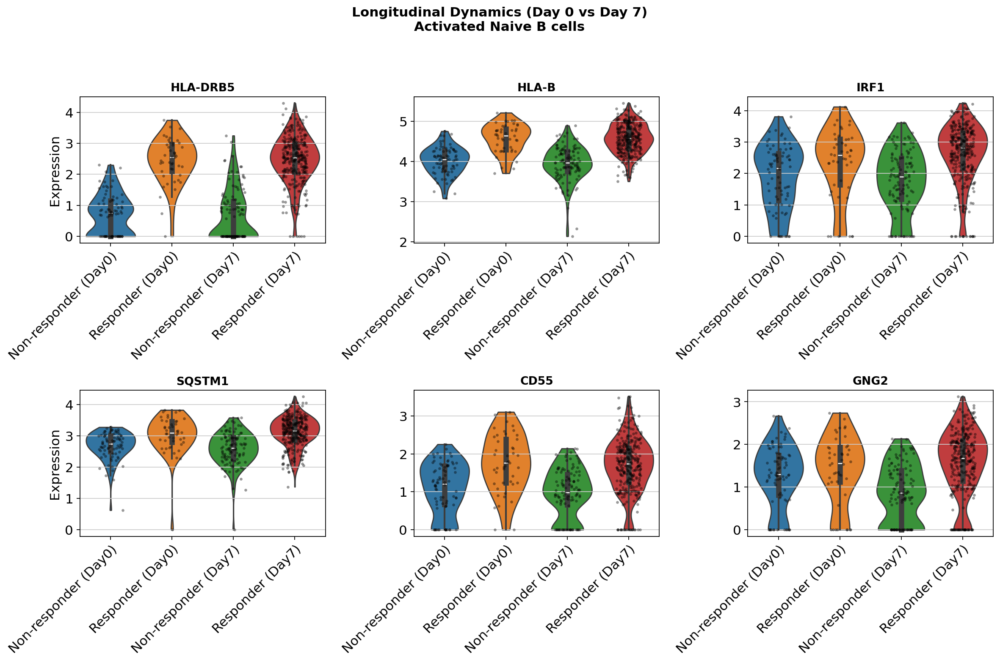

In [ ]:

# Define subtype and gene panel to visualize
target_subtype = "Activated Naive B cells"
top_candidates = ["HLA-DRB5", "HLA-B", "IRF1", "SQSTM1", "CD55", "GNG2"]

# 1. Subset to the target cell subtype across ALL timepoints
sub_adata = bdata_clean[bdata_clean.obs["bcell_type"] == target_subtype].copy()

# 2. Combine Response and Time metadata
sub_adata.obs["Group_Time"] = (
    sub_adata.obs["Response"].astype(str)
    + " ("
    + sub_adata.obs["Time"].astype(str)
    + ")"
)

ordered_categories = [
    "Non-responder (Day0)",
    "Responder (Day0)",
    "Non-responder (Day7)",
    "Responder (Day7)",
]

# 3. Extract expression values into a Pandas DataFrame
plot_df = sub_adata.obs[["Group_Time"]].copy()

for gene in top_candidates:
    if gene in sub_adata.var_names:
        expr = sub_adata[:, gene].X
        if sp.issparse(expr):
            expr = expr.toarray()
        plot_df[gene] = expr.flatten()

plot_df = plot_df[plot_df["Group_Time"].isin(ordered_categories)]

# 4. Render 2x3 Grid Plot
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

palette = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]

for i, gene in enumerate(top_candidates):
    ax = axes[i]
    if gene not in plot_df.columns:
        continue

    sns.violinplot(
        data=plot_df,
        x="Group_Time",
        y=gene,
        order=ordered_categories,
        palette=palette,
        ax=ax,
        inner="box",
        cut=0,
    )

    sns.stripplot(
        data=plot_df,
        x="Group_Time",
        y=gene,
        order=ordered_categories,
        color="black",
        alpha=0.4,
        size=3,
        jitter=0.2,
        ax=ax,
    )

    ax.set_title(gene, fontsize=12, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("Expression" if i % 3 == 0 else "")
    ax.set_xticklabels(
        ordered_categories, rotation=45, ha="right", rotation_mode="anchor"
    )

fig.suptitle(
    f"Longitudinal Dynamics (Day 0 vs Day 7)\n{target_subtype}",
    fontsize=14,
    fontweight="bold",
    y=0.98,
)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

/tmp/ipykernel_1576/1392605310.py:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/tmp/ipykernel_1576/1392605310.py:72: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(
/tmp/ipykernel_1576/1392605310.py:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/tmp/ipykernel_1576/1392605310.py:72: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(
/tmp/ipykernel_1576/1392605310.py:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Ass

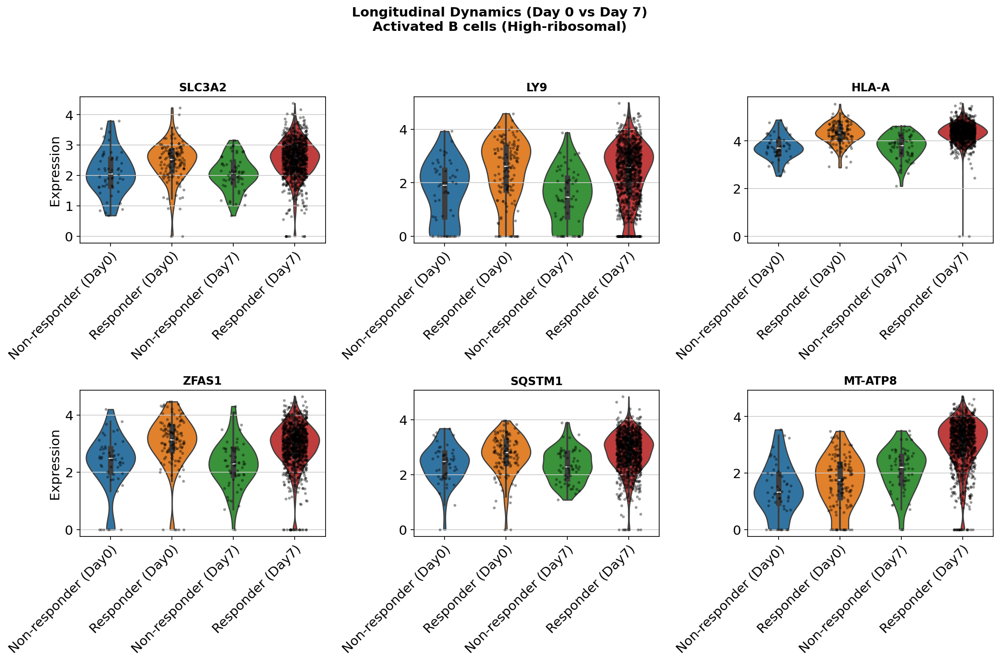

In [ ]:
# 1. Target subtype and selected top candidates
target_subtype = "Activated B cells (High-ribosomal)"
top_candidates = ["SLC3A2", "LY9", "HLA-A", "ZFAS1", "SQSTM1", "MT-ATP8"]

# 2. Subset data across all timepoints for this subtype
sub_adata = bdata_clean[bdata_clean.obs["bcell_type"] == target_subtype].copy()

# 3. Create unified metadata label
sub_adata.obs["Group_Time"] = (
    sub_adata.obs["Response"].astype(str)
    + " ("
    + sub_adata.obs["Time"].astype(str)
    + ")"
)

ordered_categories = [
    "Non-responder (Day0)",
    "Responder (Day0)",
    "Non-responder (Day7)",
    "Responder (Day7)",
]

# 4. Extract expression values into Pandas DataFrame
plot_df = sub_adata.obs[["Group_Time"]].copy()

for gene in top_candidates:
    if gene in sub_adata.var_names:
        expr = sub_adata[:, gene].X
        if sp.issparse(expr):
            expr = expr.toarray()
        plot_df[gene] = expr.flatten()

plot_df = plot_df[plot_df["Group_Time"].isin(ordered_categories)]

# 5. Render 2x3 Grid Plot
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

palette = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]

for i, gene in enumerate(top_candidates):
    ax = axes[i]
    if gene not in plot_df.columns:
        continue

    sns.violinplot(
        data=plot_df,
        x="Group_Time",
        y=gene,
        order=ordered_categories,
        palette=palette,
        ax=ax,
        inner="box",
        cut=0,
    )

    sns.stripplot(
        data=plot_df,
        x="Group_Time",
        y=gene,
        order=ordered_categories,
        color="black",
        alpha=0.4,
        size=3,
        jitter=0.2,
        ax=ax,
    )

    ax.set_title(gene, fontsize=12, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("Expression" if i % 3 == 0 else "")
    ax.set_xticklabels(
        ordered_categories, rotation=45, ha="right", rotation_mode="anchor"
    )

fig.suptitle(
    f"Longitudinal Dynamics (Day 0 vs Day 7)\n{target_subtype}",
    fontsize=14,
    fontweight="bold",
    y=0.98,
)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

/tmp/ipykernel_1576/4238058719.py:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/tmp/ipykernel_1576/4238058719.py:72: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(
/tmp/ipykernel_1576/4238058719.py:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/tmp/ipykernel_1576/4238058719.py:72: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(
/tmp/ipykernel_1576/4238058719.py:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Ass

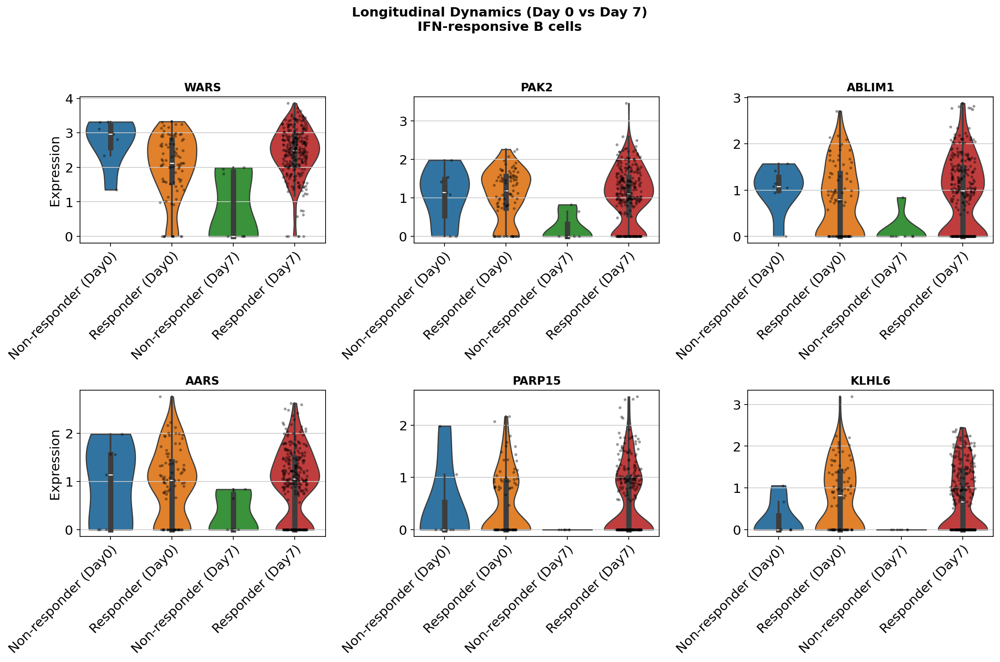

In [ ]:
# 1. Target subtype and selected top candidates
target_subtype = "IFN-responsive B cells"
top_candidates = ["WARS", "PAK2", "ABLIM1", "AARS", "PARP15", "KLHL6"]

# 2. Subset data across all timepoints for this subtype
sub_adata = bdata_clean[bdata_clean.obs["bcell_type"] == target_subtype].copy()

# 3. Create unified metadata label
sub_adata.obs["Group_Time"] = (
    sub_adata.obs["Response"].astype(str)
    + " ("
    + sub_adata.obs["Time"].astype(str)
    + ")"
)

ordered_categories = [
    "Non-responder (Day0)",
    "Responder (Day0)",
    "Non-responder (Day7)",
    "Responder (Day7)",
]

# 4. Extract expression values into Pandas DataFrame
plot_df = sub_adata.obs[["Group_Time"]].copy()

for gene in top_candidates:
    if gene in sub_adata.var_names:
        expr = sub_adata[:, gene].X
        if sp.issparse(expr):
            expr = expr.toarray()
        plot_df[gene] = expr.flatten()

plot_df = plot_df[plot_df["Group_Time"].isin(ordered_categories)]

# 5. Render 2x3 Grid Plot
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

palette = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]

for i, gene in enumerate(top_candidates):
    ax = axes[i]
    if gene not in plot_df.columns:
        continue

    sns.violinplot(
        data=plot_df,
        x="Group_Time",
        y=gene,
        order=ordered_categories,
        palette=palette,
        ax=ax,
        inner="box",
        cut=0,
    )

    sns.stripplot(
        data=plot_df,
        x="Group_Time",
        y=gene,
        order=ordered_categories,
        color="black",
        alpha=0.4,
        size=3,
        jitter=0.2,
        ax=ax,
    )

    ax.set_title(gene, fontsize=12, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("Expression" if i % 3 == 0 else "")
    ax.set_xticklabels(
        ordered_categories, rotation=45, ha="right", rotation_mode="anchor"
    )

fig.suptitle(
    f"Longitudinal Dynamics (Day 0 vs Day 7)\n{target_subtype}",
    fontsize=14,
    fontweight="bold",
    y=0.98,
)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

In [ ]:
# Define immunoglobulin constant region and TF candidate modules
isotype_genes = ["IGHM", "IGHD", "IGHG1", "IGHG3", "IGHA1"]
tf_genes = [
    "AICDA",
    "PAX5",
    "BACH2",
    "IRF4",
    "PRDM1",
    "XBP1",
    "TBX21",
    "CD86",
    "CXCR3",
]

# Extract present genes
available_genes = [
    g for g in isotype_genes + tf_genes if g in bdata_clean.var_names
]

# Create unified metadata
bdata_clean.obs["Group_Time"] = (
    bdata_clean.obs["Response"].astype(str)
    + " ("
    + bdata_clean.obs["Time"].astype(str)
    + ")"
)

ordered_categories = [
    "Non-responder (Day0)",
    "Responder (Day0)",
    "Non-responder (Day7)",
    "Responder (Day7)",
]

# Build plotting DataFrame
df = bdata_clean.obs[["Group_Time", "bcell_type"]].copy()
for g in available_genes:
    expr = bdata_clean[:, g].X
    if sp.issparse(expr):
        expr = expr.toarray()
    df[g] = expr.flatten()

# Mean expression summary grouped by Cell Type and Group_Time
summary_df = df.groupby(["bcell_type", "Group_Time"])[available_genes].mean()
print("Mean Expression of Isotype and TF Modules across Conditions:")
print(summary_df.head(10))

Mean Expression of Isotype and TF Modules across Conditions:
                                                                           IGHM  \
bcell_type                                       Group_Time                       
Activated B cells (High-ribosomal)               Non-responder (Day0)  0.281836   
                                                 Non-responder (Day7)  0.280246   
                                                 Responder (Day0)      0.199438   
                                                 Responder (Day7)      0.255770   
Activated Naive B cells                          Non-responder (Day0)  0.316148   
                                                 Non-responder (Day7)  0.436620   
                                                 Responder (Day0)      0.056652   
                                                 Responder (Day7)      0.254560   
Class-switched Plasmablasts / Antibody Secreting Responder (Day0)      0.870345   
                          

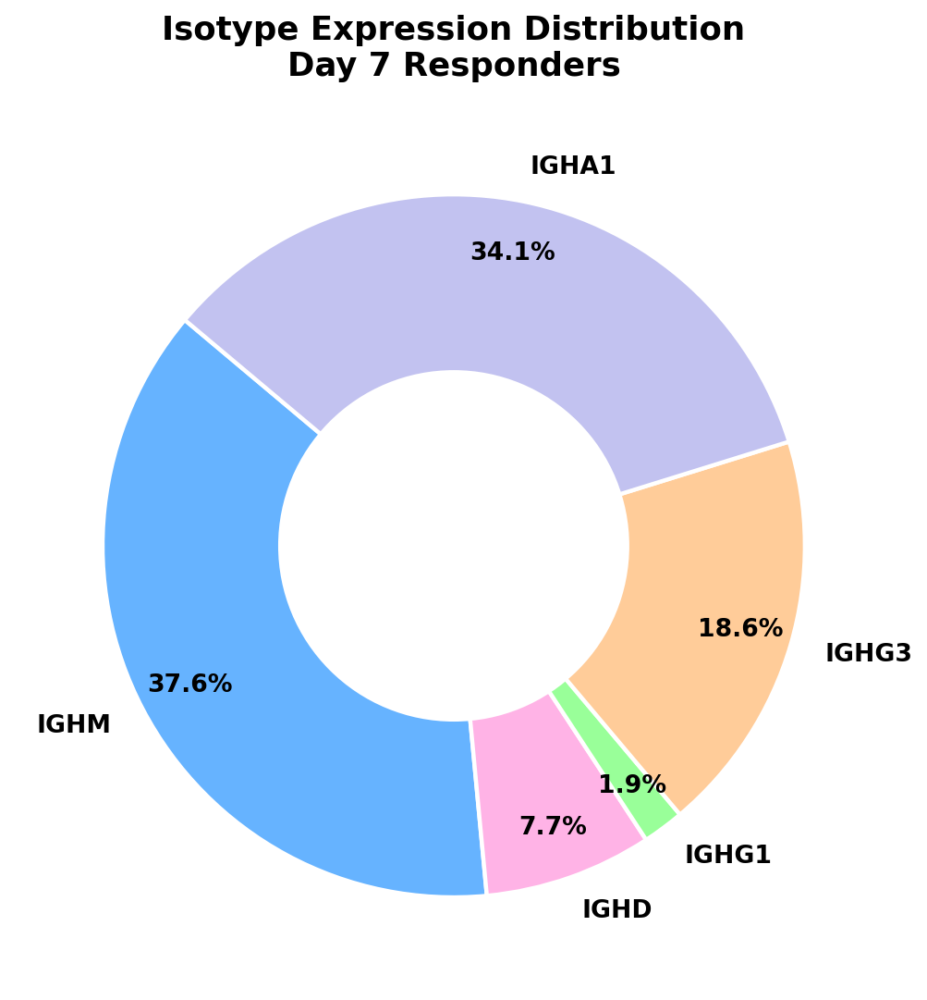

In [ ]:
# 1. Define the isotypes to analyze
isotype_genes = ["IGHM", "IGHD", "IGHG1", "IGHG3", "IGHA1"]

# 2. Filter for Day 7 Responders and exclude Stressed cells
# Note: Ensure your working dataframe 'df' has the individual cells or aggregated means
df_d7_responder = df[
    (df['Group_Time'] == 'Responder (Day7)') &
    (~df['bcell_type'].str.contains('Stressed', case=False, na=False))
]

# 3. Calculate the sum of expression for each isotype across the valid subsets
isotype_totals = df_d7_responder[isotype_genes].sum()

# 4. Filter out any isotypes with zero total expression to keep the chart clean
isotype_totals = isotype_totals[isotype_totals > 0]

# 5. Generate a publication-quality Pie Chart
plt.figure(figsize=(7, 7))

# Custom color palette to differentiate isotypes clearly
colors = ['#66b3ff', '#ffb3e6', '#99ff99', '#ffcc99', '#c2c2f0']

plt.pie(
    isotype_totals,
    labels=isotype_totals.index,
    autopct='%1.1f%%',       # Formats percentages to 1 decimal place
    startangle=140,          # Rotates chart for better label alignment
    colors=colors[:len(isotype_totals)],
    pctdistance=0.85,        # Pushes percentages slightly outward
    wedgeprops={'edgecolor': 'white', 'linewidth': 2}, # Clean white borders
    textprops={'fontsize': 12, 'fontweight': 'bold'}
)

# Draw a white circle in the center to turn it into a donut chart (optional, often looks cleaner)
centre_circle = plt.Circle((0,0), 0.50, fc='white')
fig = plt.gcf()
fig.gca().add_artist(centre_circle)

plt.title("Isotype Expression Distribution\nDay 7 Responders", fontsize=16, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

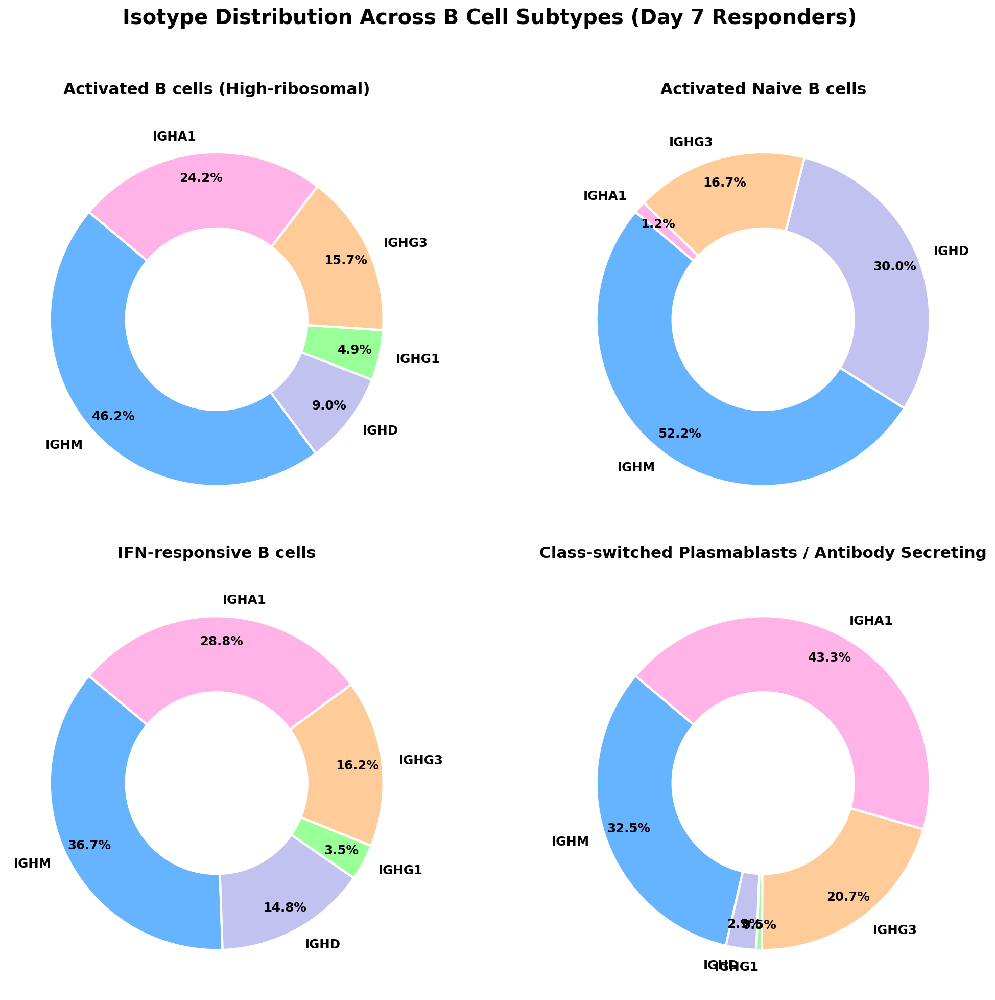

In [ ]:
# 1. Define the isotypes to analyze
isotype_genes = ["IGHM", "IGHD", "IGHG1", "IGHG3", "IGHA1"]

# 2. Filter for Day 7 Responders and strictly exclude Stressed cells
# Ensure your working dataframe 'df' contains individual cells or aggregated means
df_d7_responder = df[
    (df['Group_Time'] == 'Responder (Day7)') &
    (~df['bcell_type'].str.contains('Stressed', case=False, na=False))
]

# Extract the unique remaining cell types (should be 4)
cell_types = df_d7_responder['bcell_type'].unique()

# 3. Set up a 2x2 grid for the subplots
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.flatten()

# Custom color palette mapping specific isotypes to consistent colors
# Using a dictionary ensures IGHM is always the same color across different pie charts
color_map = {
    "IGHM": "#66b3ff",   # Blue
    "IGHD": "#c2c2f0",   # Purple
    "IGHG1": "#99ff99",  # Green
    "IGHG3": "#ffcc99",  # Orange
    "IGHA1": "#ffb3e6"   # Pink
}

# 4. Loop through each cell type and populate the grid
for i, ctype in enumerate(cell_types):
    if i >= 4:
        break  # Safety break if more than 4 cell types exist

    ax = axes[i]

    # Subset data for the specific cell type
    sub_df = df_d7_responder[df_d7_responder['bcell_type'] == ctype]

    # Calculate the sum of expression for each isotype
    isotype_totals = sub_df[isotype_genes].sum()

    # Filter out isotypes with zero expression for this specific cell type
    isotype_totals = isotype_totals[isotype_totals > 0]

    if isotype_totals.empty:
        ax.axis('off')
        ax.set_title(f"{ctype}\n(No Isotype Expression)", fontsize=12)
        continue

    # Map the correct colors from the dictionary
    pie_colors = [color_map[iso] for iso in isotype_totals.index]

    # Plot the pie chart
    ax.pie(
        isotype_totals,
        labels=isotype_totals.index,
        autopct='%1.1f%%',
        startangle=140,
        colors=pie_colors,
        pctdistance=0.85,
        wedgeprops={'edgecolor': 'white', 'linewidth': 2},
        textprops={'fontsize': 11, 'fontweight': 'bold'}
    )

    # Draw a white circle in the center to create the donut aesthetic
    centre_circle = plt.Circle((0,0), 0.55, fc='white')
    ax.add_artist(centre_circle)

    # Clean title per subplot
    ax.set_title(ctype, fontsize=14, fontweight='bold', pad=15)

# Hide any empty subplots if you have fewer than 4 cell types
for j in range(i + 1, len(axes)):
    axes[j].axis('off')

# Global Title and Layout adjustments
plt.suptitle(
    "Isotype Distribution Across B Cell Subtypes (Day 7 Responders)",
    fontsize=18,
    fontweight='bold',
    y=1.02
)
plt.tight_layout()
plt.show()

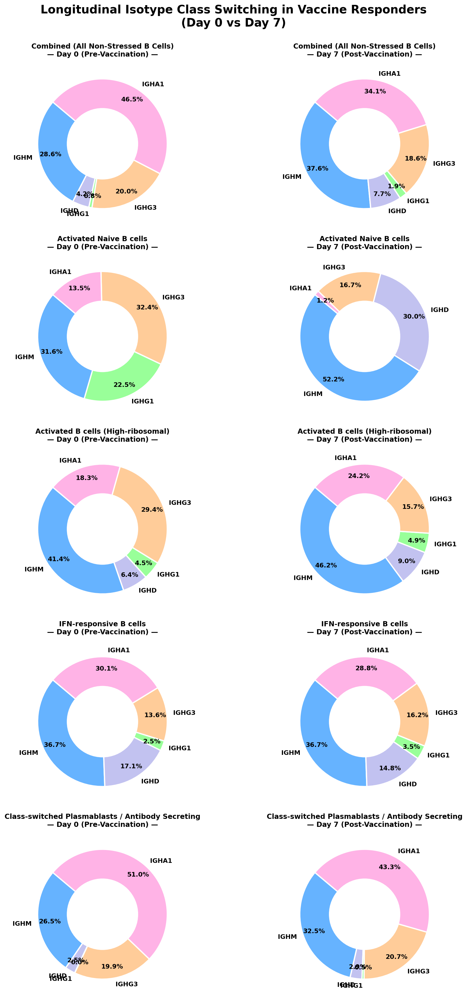

In [ ]:
# 1. Define isotype targets and consistent color palette
isotype_genes = ["IGHM", "IGHD", "IGHG1", "IGHG3", "IGHA1"]

color_map = {
    "IGHM": "#66b3ff",   # Soft Blue
    "IGHD": "#c2c2f0",   # Muted Purple
    "IGHG1": "#99ff99",  # Soft Green
    "IGHG3": "#ffcc99",  # Warm Peach
    "IGHA1": "#ffb3e6"   # Rose Pink
}

# 2. Filter dataset for Responders and exclude Stressed cells
df_responder = df[
    (df['Group_Time'].isin(['Responder (Day0)', 'Responder (Day7)'])) &
    (~df['bcell_type'].str.contains('Stressed', case=False, na=False))
].copy()

# Extract individual non-stressed subtypes (up to 4)
subtypes = list(df_responder['bcell_type'].unique())[:4]

# Define the 5 rows: Row 1 is Combined, Rows 2-5 are Subtypes
row_categories = ['Combined (All Non-Stressed B Cells)'] + subtypes

# 3. Create a 5-row x 2-column figure (10 charts total)
fig, axes = plt.subplots(5, 2, figsize=(13, 22))

days = ['Responder (Day0)', 'Responder (Day7)']
day_titles = ['Day 0 (Pre-Vaccination)', 'Day 7 (Post-Vaccination)']

# 4. Loop through categories and timepoints to render side-by-side charts
for row_idx, cat in enumerate(row_categories):
    for col_idx, (day_code, day_label) in enumerate(zip(days, day_titles)):
        ax = axes[row_idx, col_idx]

        # Subset data for row category and column timepoint
        if cat == 'Combined (All Non-Stressed B Cells)':
            sub_df = df_responder[df_responder['Group_Time'] == day_code]
        else:
            sub_df = df_responder[
                (df_responder['Group_Time'] == day_code) &
                (df_responder['bcell_type'] == cat)
            ]

        # Sum isotype expression
        isotype_totals = sub_df[isotype_genes].sum()
        isotype_totals = isotype_totals[isotype_totals > 0]

        # Fallback if no expression exists for a given subset/timepoint
        if isotype_totals.empty or isotype_totals.sum() == 0:
            ax.axis('off')
            ax.text(0.5, 0.5, 'No Expression\nDetected', ha='center', va='center', fontsize=11, color='gray')
            ax.set_title(f"{cat}\n— {day_label} —", fontsize=11, fontweight='bold')
            continue

        pie_colors = [color_map[iso] for iso in isotype_totals.index]

        # Render Donut Chart
        ax.pie(
            isotype_totals,
            labels=isotype_totals.index,
            autopct='%1.1f%%',
            startangle=140,
            colors=pie_colors,
            pctdistance=0.82,
            wedgeprops={'edgecolor': 'white', 'linewidth': 2},
            textprops={'fontsize': 10, 'fontweight': 'bold'}
        )

        # Donut hole cut-out
        centre_circle = plt.Circle((0, 0), 0.55, fc='white')
        ax.add_artist(centre_circle)

        # Subplot Title
        ax.set_title(f"{cat}\n— {day_label} —", fontsize=11, fontweight='bold', pad=10)

# 5. Global formatting and spacing
plt.suptitle(
    "Longitudinal Isotype Class Switching in Vaccine Responders\n(Day 0 vs Day 7)",
    fontsize=18,
    fontweight='bold',
    y=0.995
)
plt.tight_layout()
plt.show()

## 18. B-cell gene-set / pathway analysis


In [ ]:
%pip install gseapy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 689.7/689.7 kB 23.2 MB/s  0:00:00


In [ ]:
# 1. Isolate Day 7 cells and exclude the "Stressed" cluster to ensure clean biological signal
adata_day7 = bdata_clean[
    (bdata_clean.obs['Time'].astype(str) == 'Day7') &
    (~bdata_clean.obs['bcell_type'].astype(str).str.contains('Stressed / low-RNA', case=False, na=False))
].copy()

# 2. Run Differential Gene Expression (Responders vs Non-responders)
# Assuming your metadata column distinguishing them is called 'Response'
sc.tl.rank_genes_groups(
    adata_day7,
    groupby='Response',
    reference='Non-responder',  # Sets Non-responder as the baseline
    method='wilcoxon'
)

# 3. Extract the results for Responders into a Pandas DataFrame
deg_df = sc.get.rank_genes_groups_df(adata_day7, group='Responder')

# 4. Filter for strict statistical significance and positive fold-change (upregulated in Responders)
# Logfoldchange > 0.5 is a standard threshold to filter out biological noise
significant_degs = deg_df[
    (deg_df['pvals'] < 0.05) &
    (deg_df['logfoldchanges'] > 0.5)
].copy()

# 5. Sort the genes by the highest fold change and most significant p-value
significant_degs = significant_degs.sort_values(
    by=['logfoldchanges', 'pvals_adj'],
    ascending=[False, True]
)

# 6. Extract the top 100 gene names as a simple list
target_genes = significant_degs['names'].head(100).tolist()

print("target_genes =", target_genes)

target_genes = ['IGKV1D-43', 'IGKV1-6', 'FMOD', 'XIST', 'CLNK', 'COCH', 'IGHV7-4-1', 'KRT18', 'TESC', 'RAMP1', 'IGKV1-9', 'KLK2', 'IGKV1-27', 'JCHAIN', 'PTPRCAP', 'IGHA1', 'PAIP2B', 'WHRN', 'HLA-DRB5', 'COL9A3', 'MIER3', 'TVP23A', 'CCDC88A', 'AP001610.1', 'LINC02365', 'LINC00944', 'CAB39L', 'CIITA', 'RAB20', 'GNG7', 'PASK', 'VAV2', 'OAS1', 'ISY1', 'RHEBL1', 'UQCRHL', 'PLA2G4C', 'LINC00996', 'PDCD1', 'OAS3', 'IFIT1', 'FAM213B', 'SH3D21', 'HLA-DQA2', 'MX2', 'DDX11', 'CD3D', 'RILPL2', 'HERC5', 'IFIT3', 'DMD', 'TCF7', 'LY9', 'SERINC5', 'AIM2', 'SLFN5', 'PPFIBP2', 'CD38', 'PLAC8', 'U62317.5', 'CXCL16', 'HLA-DOA', 'BACE2', 'THEMIS2', 'NCF4', 'CCR6', 'STAT2', 'ASAH1', 'HLA-DRA', 'LINC01857', 'MGAT1', 'LGMN', 'HLA-DMA', 'PLSCR1', 'ARSA', 'TRAC', 'UTRN', 'SFMBT1', 'ZNF100', 'IGHG3', 'MCOLN2', 'MT-ATP8', 'DEF8', 'IFIT2', 'PLEKHG2', 'MX1', 'DDX58', 'ARRDC2', 'AMDHD2', 'LAP3', 'ADAM28', 'IFITM1', 'SPOCK2', 'FCMR', 'ISG15', 'RBM15', 'ZBTB32', 'ARID5B', 'CD24', 'IL10RA']


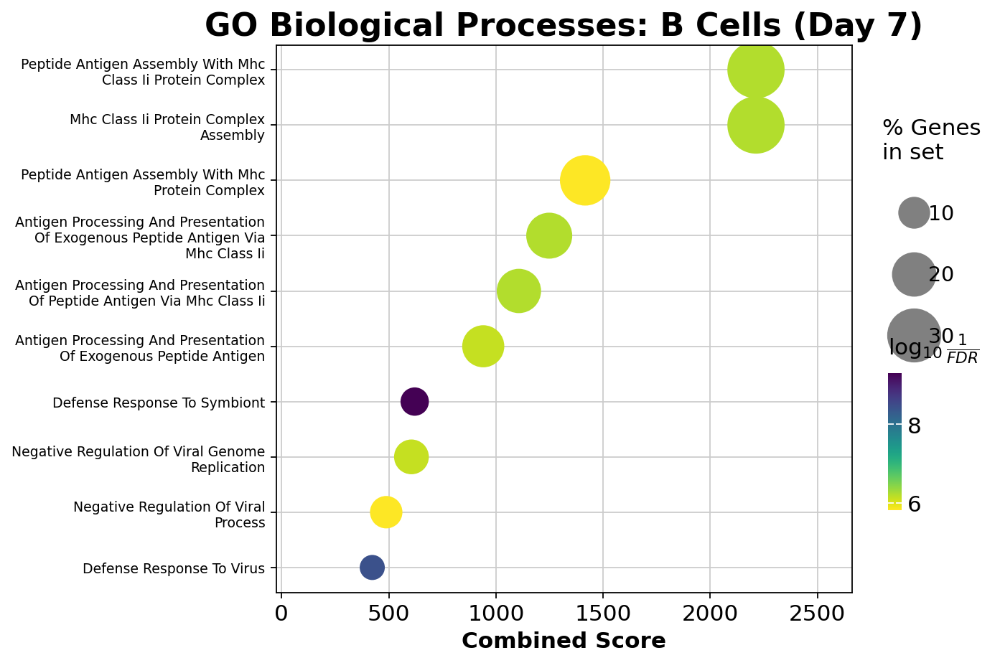

In [ ]:
import textwrap
import gseapy as gp

# 1. Run Enrichr on your top T cell DEGs
# Replace 't_cell_target_genes' with your extracted T cell gene list variable

target_genes = ['IGKV1D-43', 'IGKV1-6', 'FMOD', 'XIST', 'CLNK', 'COCH', 'IGHV7-4-1', 'KRT18', 'TESC', 'RAMP1', 'IGKV1-9', 'KLK2', 'IGKV1-27', 'JCHAIN', 'PTPRCAP', 'IGHA1', 'PAIP2B', 'WHRN', 'HLA-DRB5', 'COL9A3', 'MIER3', 'TVP23A', 'CCDC88A', 'AP001610.1', 'LINC02365', 'LINC00944', 'CAB39L', 'CIITA', 'RAB20', 'GNG7', 'PASK', 'VAV2', 'OAS1', 'ISY1', 'RHEBL1', 'UQCRHL', 'PLA2G4C', 'LINC00996', 'PDCD1', 'OAS3', 'IFIT1', 'FAM213B', 'SH3D21', 'HLA-DQA2', 'MX2', 'DDX11', 'CD3D', 'RILPL2', 'HERC5', 'IFIT3', 'DMD', 'TCF7', 'LY9', 'SERINC5', 'AIM2', 'SLFN5', 'PPFIBP2', 'CD38', 'PLAC8', 'U62317.5', 'CXCL16', 'HLA-DOA', 'BACE2', 'THEMIS2', 'NCF4', 'CCR6', 'STAT2', 'ASAH1', 'HLA-DRA', 'LINC01857', 'MGAT1', 'LGMN', 'HLA-DMA', 'PLSCR1', 'ARSA', 'TRAC', 'UTRN', 'SFMBT1', 'ZNF100', 'IGHG3', 'MCOLN2', 'MT-ATP8', 'DEF8', 'IFIT2', 'PLEKHG2', 'MX1', 'DDX58', 'ARRDC2', 'AMDHD2', 'LAP3', 'ADAM28', 'IFITM1', 'SPOCK2', 'FCMR', 'ISG15', 'RBM15', 'ZBTB32', 'ARID5B', 'CD24', 'IL10RA']

enr_bcells = gp.enrichr(
    gene_list= target_genes,
    gene_sets=['GO_Biological_Process_2023'],
    organism='human',
    outdir=None,
    cutoff=0.05
)

# 2. Clean up long GO terms and wrap text for better plotting room
results_clean = enr_bcells.results.copy()
results_clean['Term'] = results_clean['Term'].str.replace(r' \(GO:[0-9]+\)', '', regex=True).str.title()
results_clean['Term'] = results_clean['Term'].apply(lambda x: "\n".join(textwrap.wrap(x, width=35)))

# 3. Render the GO Dotplot
ax = gp.dotplot(
    results_clean,
    column="Adjusted P-value",
    x="Combined Score",
    size=10,
    top_term=10,
    cmap="viridis_r",
    title="GO Biological Processes: B Cells (Day 7)",
    figsize=(9, 6),
    ofname=None
)

# 4. Fine-tune axis labels and display
plt.tick_params(axis='y', labelsize=8.5)
plt.tight_layout()
plt.show()

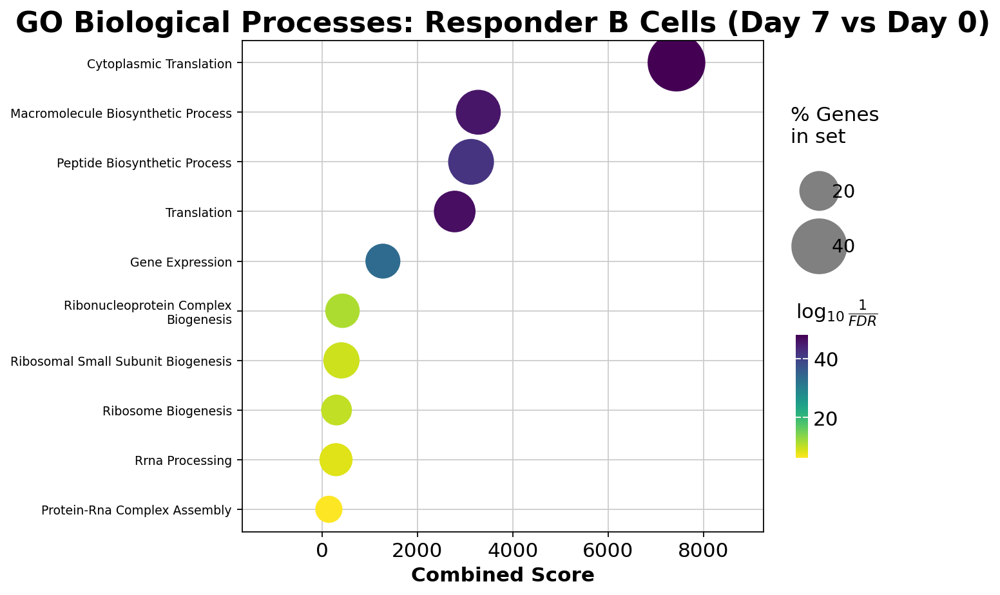

In [ ]:
import textwrap
import gseapy as gp
import scanpy as sc

# 1. Subset bdata for Responders only (Day 0 and Day 7)
bdata_resp = bdata_clean[
    (bdata_clean.obs['Response'].astype(str) == 'Responder') &
    (~bdata_clean.obs['bcell_type'].astype(str).str.contains('Stressed / low-RNA', case=False, na=False))
].copy()

# 2. Extract Differentially Expressed Genes (Day 7 relative to Day 0 baseline)
sc.tl.rank_genes_groups(
    bdata_resp,
    groupby='Time',
    reference='Day0',
    method='wilcoxon'
)

# 3. Get results for Day 7 upregulated genes
deg_df = sc.get.rank_genes_groups_df(bdata_resp, group='Day7')

# 4. Filter for strict significance and relax logFC slightly to capture more B cell biology
sig_degs = deg_df[
    (deg_df['pvals_adj'] < 0.05) &  # Changed from pvals to pvals_adj
    (deg_df['logfoldchanges'] > 0.25) # Relaxed from 0.5
].sort_values(by=['logfoldchanges', 'pvals_adj'], ascending=[False, True])

# Extract up to 300 genes instead of 100 to give Enrichr more statistical power
target_genes = sig_degs['names'].head(300).tolist()

# 5. Run GO Biological Process enrichment
enr_resp = gp.enrichr(
    gene_list=target_genes,
    gene_sets=['GO_Biological_Process_2023'],
    organism='human',
    outdir=None,
    cutoff=0.1 # Relaxed cutoff to avoid the ValueError crash
)

# 6. Safety check before plotting
if enr_resp.results.empty or enr_resp.results[enr_resp.results['Adjusted P-value'] < 0.1].empty:
    print("No pathways met the enrichment cutoff. The B cell shift is likely driven by specific isotype genes (e.g., IGHA1) rather than broad GO pathways.")
else:
    # Clean up and wrap Y-axis pathway labels
    results_clean = enr_resp.results.copy()
    results_clean['Term'] = results_clean['Term'].str.replace(r' \(GO:[0-9]+\)', '', regex=True).str.title()
    results_clean['Term'] = results_clean['Term'].apply(lambda x: "\n".join(textwrap.wrap(x, width=35)))

    # 7. Render GO Dotplot
    ax = gp.dotplot(
        results_clean,
        column="Adjusted P-value",
        x="Combined Score",
        size=10,
        top_term=10,
        cmap="viridis_r",
        title="GO Biological Processes: Responder B Cells (Day 7 vs Day 0)",
        figsize=(9, 6),
        ofname=None
    )

    # 8. Adjust Y-axis label sizing
    plt.tick_params(axis='y', labelsize=8.5)
    plt.tight_layout()
    plt.show()

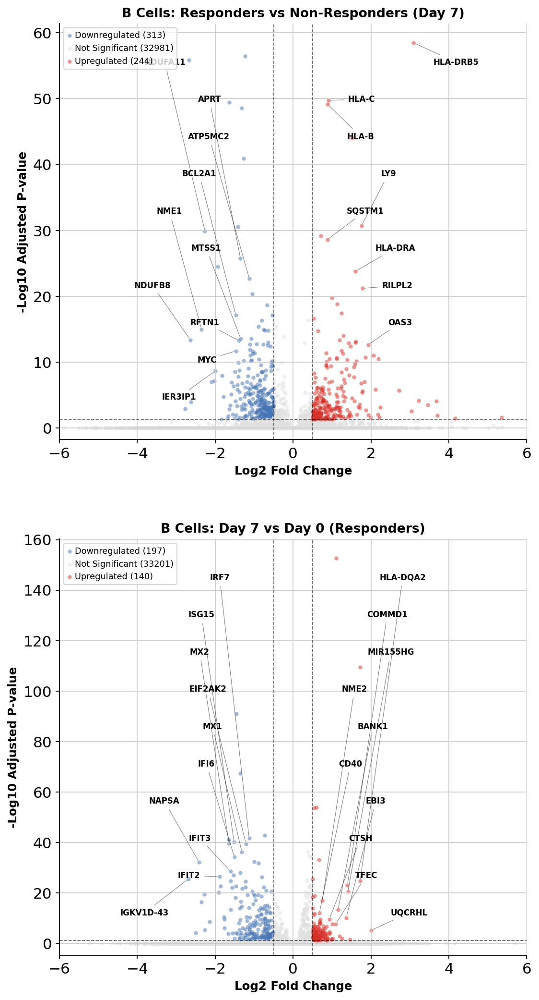

In [ ]:
import scanpy as sc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# 1. FILTERING & METADATA PREPARATION
# ==========================================

# Filter out stressed / low-RNA B cells
bdata_filtered = bdata_clean[
    ~bdata_clean.obs['bcell_type'].astype(str).str.contains('Stressed / low-RNA', case=False, na=False)
].copy()

# Create combined Group_Time column
bdata_filtered.obs['Group_Time'] = (
    bdata_filtered.obs['Response'].astype(str) + " (" + bdata_filtered.obs['Time'].astype(str) + ")"
)


# ==========================================
# 2. DIFFERENTIAL EXPRESSION ANALYSIS (DGE)
# ==========================================

# --- DGE 1: B Cells - Responders vs Non-Responders at Day 7 ---
bdata_d7 = bdata_filtered[
    bdata_filtered.obs['Group_Time'].isin(['Responder (Day7)', 'Non-responder (Day7)'])
].copy()

sc.tl.rank_genes_groups(
    bdata_d7,
    groupby='Group_Time',
    reference='Non-responder (Day7)',
    method='wilcoxon'
)
deg_d7_b = sc.get.rank_genes_groups_df(bdata_d7, group='Responder (Day7)')

# --- DGE 2: B Cells - Day 7 vs Day 0 in Responders ---
bdata_resp = bdata_filtered[
    bdata_filtered.obs['Group_Time'].isin(['Responder (Day0)', 'Responder (Day7)'])
].copy()

sc.tl.rank_genes_groups(
    bdata_resp,
    groupby='Group_Time',
    reference='Responder (Day0)',
    method='wilcoxon'
)
deg_resp_b = sc.get.rank_genes_groups_df(bdata_resp, group='Responder (Day7)')


# ==========================================
# 3. VOLCANO PLOTTING FUNCTION
# ==========================================

def plot_refined_volcano_bcells(deg_df, title, ax, x_limit=6, top_n=10):
    deg_df = deg_df.copy()

    # Handle absolute zero p-values cleanly for log transformation
    deg_df['pvals_adj'] = np.where(deg_df['pvals_adj'] == 0, 1e-300, deg_df['pvals_adj'])
    deg_df['nlog10_pvals'] = -np.log10(deg_df['pvals_adj'])

    # Categorize gene expression status
    def categorize(row):
        if row['pvals_adj'] < 0.05 and row['logfoldchanges'] > 0.5:
            return 'Upregulated'
        elif row['pvals_adj'] < 0.05 and row['logfoldchanges'] < -0.5:
            return 'Downregulated'
        return 'Not Significant'

    deg_df['Status'] = deg_df.apply(categorize, axis=1)

    colors = {
        'Upregulated': '#d73027',
        'Downregulated': '#4575b4',
        'Not Significant': '#e0e0e0'
    }

    # Plot scatter points
    for status, group in deg_df.groupby('Status'):
        ax.scatter(
            group['logfoldchanges'],
            group['nlog10_pvals'],
            c=colors[status],
            label=f"{status} ({len(group)})",
            alpha=0.5,
            s=14,
            linewidths=0
        )

    # Reference significance lines
    ax.axhline(-np.log10(0.05), color='black', linestyle='--', linewidth=0.8, alpha=0.6)
    ax.axvline(0.5, color='black', linestyle='--', linewidth=0.8, alpha=0.6)
    ax.axvline(-0.5, color='black', linestyle='--', linewidth=0.8, alpha=0.6)

    # Filter out non-coding, mitochondrial, sex, and ribosomal clutter
    filtered_deg = deg_df[~deg_df['names'].str.startswith(('MTRNR', 'RPS', 'RPL', 'XIST', 'MT-'))].copy()
    filtered_deg['score'] = filtered_deg['logfoldchanges'].abs() * filtered_deg['nlog10_pvals']

    # Select Top N Upregulated and Downregulated genes by score
    top_up = filtered_deg[filtered_deg['Status'] == 'Upregulated'].sort_values('score', ascending=False).head(top_n)
    top_down = filtered_deg[filtered_deg['Status'] == 'Downregulated'].sort_values('score', ascending=False).head(top_n)

    # Sort selected genes by Y-axis value (nlog10_pvals) to prevent intersecting leader lines
    top_up = top_up.sort_values('nlog10_pvals', ascending=True).reset_index(drop=True)
    top_down = top_down.sort_values('nlog10_pvals', ascending=True).reset_index(drop=True)

    # Dynamic vertical placement bounds to avoid overlap
    max_y = deg_df['nlog10_pvals'].max()
    y_texts_up = np.linspace(max_y * 0.08, max_y * 0.95, len(top_up)) if len(top_up) > 0 else []
    y_texts_down = np.linspace(max_y * 0.08, max_y * 0.95, len(top_down)) if len(top_down) > 0 else []

    # Annotate Top Upregulated Genes (Right side)
    for idx, row in top_up.iterrows():
        x_text = min(row['logfoldchanges'] + 0.5, x_limit - 0.2)
        ax.annotate(
            row['names'],
            xy=(row['logfoldchanges'], row['nlog10_pvals']),
            xytext=(x_text, y_texts_up[idx]),
            fontsize=7.5,
            fontweight='bold',
            ha='left',
            va='center',
            arrowprops=dict(arrowstyle='-', color='black', lw=0.5, alpha=0.5)
        )

    # Annotate Top Downregulated Genes (Left side)
    for idx, row in top_down.iterrows():
        x_text = max(row['logfoldchanges'] - 0.5, -x_limit + 0.2)
        ax.annotate(
            row['names'],
            xy=(row['logfoldchanges'], row['nlog10_pvals']),
            xytext=(x_text, y_texts_down[idx]),
            fontsize=7.5,
            fontweight='bold',
            ha='right',
            va='center',
            arrowprops=dict(arrowstyle='-', color='black', lw=0.5, alpha=0.5)
        )

    # Set constrained axis limits
    ax.set_xlim(-x_limit, x_limit)
    ax.set_ylim(-max_y * 0.03, max_y * 1.05)

    # Layout formatting
    ax.set_xlabel("Log2 Fold Change", fontsize=11, fontweight='bold')
    ax.set_ylabel("-Log10 Adjusted P-value", fontsize=11, fontweight='bold')
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.legend(loc="upper left", frameon=True, fontsize=8)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)


# ==========================================
# 4. RENDER STACKED FIGURE (2x1 COLUMN GRID)
# ==========================================

fig, axes = plt.subplots(2, 1, figsize=(8, 14))

# Plot 1: B Cells - Responders vs Non-Responders (Day 7)
plot_refined_volcano_bcells(
    deg_d7_b,
    "B Cells: Responders vs Non-Responders (Day 7)",
    axes[0],
    x_limit=6,
    top_n=10
)

# Plot 2: B Cells - Day 7 vs Day 0 (Responders)
plot_refined_volcano_bcells(
    deg_resp_b,
    "B Cells: Day 7 vs Day 0 (Responders)",
    axes[1],
    x_limit=6,
    top_n=10
)

plt.tight_layout(pad=3.0)
plt.show()

## 19. T-cell analysis


T-cell subclustering and differential expression are exploratory because donor numbers are limited. Cell-level comparisons do not replace donor-level replication.


In [ ]:
print(adata.obs.cell_type.value_counts())

cell_type
NK cells                              12578
Naive/Central Memory CD4 T cells      11763
Resting CD4 T cells                    8538
NK/T-like cytotoxic cells              8450
Cytotoxic CD8 T cells                  6375
Naive/central memory mixed T cells     4693
B cells                                4048
Name: count, dtype: int64


In [ ]:
# 1. Define the T cell
t_cell_subtypes = [
    'Naive/Central Memory CD4 T cells',
    'Resting CD4 T cells',
    'Cytotoxic CD8 T cells',
    'Naive/central memory mixed T cells'
]

# 2. Subset the AnnData object
tdata = adata[adata.obs['cell_type'].isin(t_cell_subtypes)].copy()

# 3. Verify the cell counts in the new dataset
print("T Cell Dataset Shape:", tdata.shape)
print("\nCell counts per subtype:")
print(tdata.obs['cell_type'].value_counts())

T Cell Dataset Shape: (31369, 33538)

Cell counts per subtype:
cell_type
Naive/Central Memory CD4 T cells      11763
Resting CD4 T cells                    8538
Cytotoxic CD8 T cells                  6375
Naive/central memory mixed T cells     4693
Name: count, dtype: int64


In [ ]:
# 1. Isolate Day 7 cells and exclude the "Stressed" cluster to ensure clean biological signal
tdata_day7 = tdata[
    (tdata.obs['Time'].astype(str) == 'Day7')
].copy()

# 2. Run Differential Gene Expression (Responders vs Non-responders)
# Assuming your metadata column distinguishing them is called 'Response'
sc.tl.rank_genes_groups(
    tdata_day7,
    groupby='Response',
    reference='Non-responder',  # Sets Non-responder as the baseline
    method='wilcoxon'
)

# 3. Extract the results for Responders into a Pandas DataFrame
deg_df = sc.get.rank_genes_groups_df(tdata_day7, group='Responder')

# 4. Filter for strict statistical significance and positive fold-change (upregulated in Responders)
# Logfoldchange > 0.5 is a standard threshold to filter out biological noise
significant_degs = deg_df[
    (deg_df['pvals'] < 0.05) &
    (deg_df['logfoldchanges'] > 0.5)
].copy()

# 5. Sort the genes by the highest fold change and most significant p-value
significant_degs = significant_degs.sort_values(
    by=['logfoldchanges', 'pvals_adj'],
    ascending=[False, True]
)

# 6. Extract the top 100 gene names as a simple list
target_genes = significant_degs['names'].head(100).tolist()

print("target_genes =", target_genes)

target_genes = ['XIST', 'IGKV1-27', 'FST', 'XKR9', 'CD8B2', 'TRGV4', 'HLA-DRA', 'ADARB2', 'TRGV5', 'UQCRHL', 'HLA-DQA1', 'HLA-DRB5', 'PLA2G4C', 'DDX11', 'PARVB', 'HNRNPA1P48', 'CCDC50', 'EEF1G', 'AD000671.2', 'COMMD1', 'CREM', 'ISG15', 'CMTM8', 'TRBV9', 'MS4A1', 'RPS29', 'TRAV1-2', 'GPR15', 'SCO2', 'TRBV28', 'EGLN2', 'TRBV29-1', 'PTPRCAP', 'MT-ATP8', 'FAM50B', 'TMEM187', 'CPNE2', 'IFI6', 'RPS16', 'ITM2A', 'BEST1', 'LY6E', 'NME2', 'RPS4X', 'IFITM3', 'CD8B', 'RPL13A', 'RPL38', 'CXCR4', 'AP002387.2', 'RTKN2', 'HLA-DQA2', 'BTN3A2', 'RPS20', 'TMEM14C', 'TAX1BP3', 'GSTM3', 'RPL7', 'SPATS2L', 'FTH1', 'RPL27', 'RPL10A', 'IFITM1', 'RPL24', 'RPL28', 'CCDC163', 'NDUFB11', 'RPS5', 'RPL9', 'RPS26', 'RPLP2', 'SNHG8', 'FAM27C', 'TMEM35B', 'RPL23', 'MIF', 'RPL29', 'RPL15', 'RPL37A', 'GATD3B', 'HLA-C', 'GPR171', 'RPL31', 'RPL22', 'NDUFA6', 'RPL35', 'AIM2', 'UBA52', 'RPS11', 'RPL32', 'RPS9', 'RACK1', 'RPS13', 'COTL1', 'CDK10', 'DUSP4', 'RPS25', 'GABARAP', 'ZFAS1', 'RPS8']


## 20. T-cell gene-set analysis


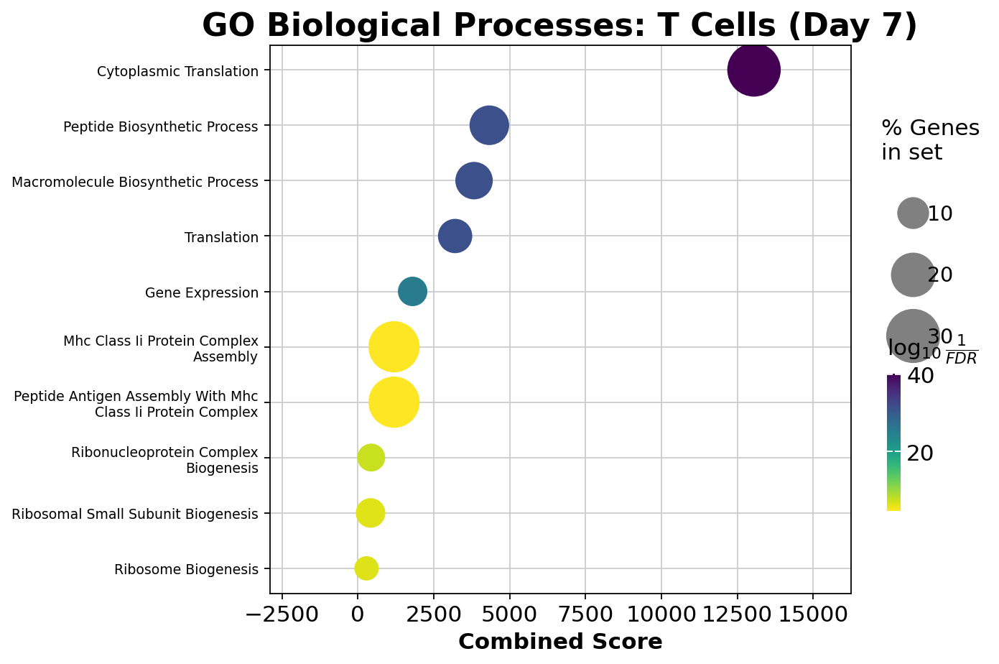

In [ ]:
import textwrap
import gseapy as gp

# 1. Run Enrichr on your top T cell DEGs
# Replace 't_cell_target_genes' with your extracted T cell gene list variable

t_cell_target_genes = ['XIST', 'IGKV1-27', 'FST', 'XKR9', 'CD8B2', 'TRGV4', 'HLA-DRA', 'ADARB2', 'TRGV5', 'UQCRHL', 'HLA-DQA1', 'HLA-DRB5', 'PLA2G4C', 'DDX11', 'PARVB', 'HNRNPA1P48', 'CCDC50', 'EEF1G', 'AD000671.2', 'COMMD1', 'CREM', 'ISG15', 'CMTM8', 'TRBV9', 'MS4A1', 'RPS29', 'TRAV1-2', 'GPR15', 'SCO2', 'TRBV28', 'EGLN2', 'TRBV29-1', 'PTPRCAP', 'MT-ATP8', 'FAM50B', 'TMEM187', 'CPNE2', 'IFI6', 'RPS16', 'ITM2A', 'BEST1', 'LY6E', 'NME2', 'RPS4X', 'IFITM3', 'CD8B', 'RPL13A', 'RPL38', 'CXCR4', 'AP002387.2', 'RTKN2', 'HLA-DQA2', 'BTN3A2', 'RPS20', 'TMEM14C', 'TAX1BP3', 'GSTM3', 'RPL7', 'SPATS2L', 'FTH1', 'RPL27', 'RPL10A', 'IFITM1', 'RPL24', 'RPL28', 'CCDC163', 'NDUFB11', 'RPS5', 'RPL9', 'RPS26', 'RPLP2', 'SNHG8', 'FAM27C', 'TMEM35B', 'RPL23', 'MIF', 'RPL29', 'RPL15', 'RPL37A', 'GATD3B', 'HLA-C', 'GPR171', 'RPL31', 'RPL22', 'NDUFA6', 'RPL35', 'AIM2', 'UBA52', 'RPS11', 'RPL32', 'RPS9', 'RACK1', 'RPS13', 'COTL1', 'CDK10', 'DUSP4', 'RPS25', 'GABARAP', 'ZFAS1', 'RPS8']

enr_tcells = gp.enrichr(
    gene_list=t_cell_target_genes,
    gene_sets=['GO_Biological_Process_2023'],
    organism='human',
    outdir=None,
    cutoff=0.05
)

# 2. Clean up long GO terms and wrap text for better plotting room
results_clean = enr_tcells.results.copy()
results_clean['Term'] = results_clean['Term'].str.replace(r' \(GO:[0-9]+\)', '', regex=True).str.title()
results_clean['Term'] = results_clean['Term'].apply(lambda x: "\n".join(textwrap.wrap(x, width=35)))

# 3. Render the GO Dotplot
ax = gp.dotplot(
    results_clean,
    column="Adjusted P-value",
    x="Combined Score",
    size=10,
    top_term=10,
    cmap="viridis_r",
    title="GO Biological Processes: T Cells (Day 7)",
    figsize=(9, 6),
    ofname=None
)

# 4. Fine-tune axis labels and display
plt.tick_params(axis='y', labelsize=8.5)
plt.tight_layout()
plt.show()

In [ ]:
print(tdata.obs_keys)

<bound method AnnData.obs_keys of AnnData object with n_obs × n_vars = 31369 × 33538
    obs: 'n_genes', 'total_counts', 'mt_percent', 'Sample', 'Time', 'Donor', 'Response', 'leiden', 'cell_type', 'Time_Group'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'log1p', 'hvg', 'pca', 'neighbors', 'umap', 'leiden', 'rank_genes_groups', 'cell_type_colors'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'
    layers: None (.X), 'counts'>


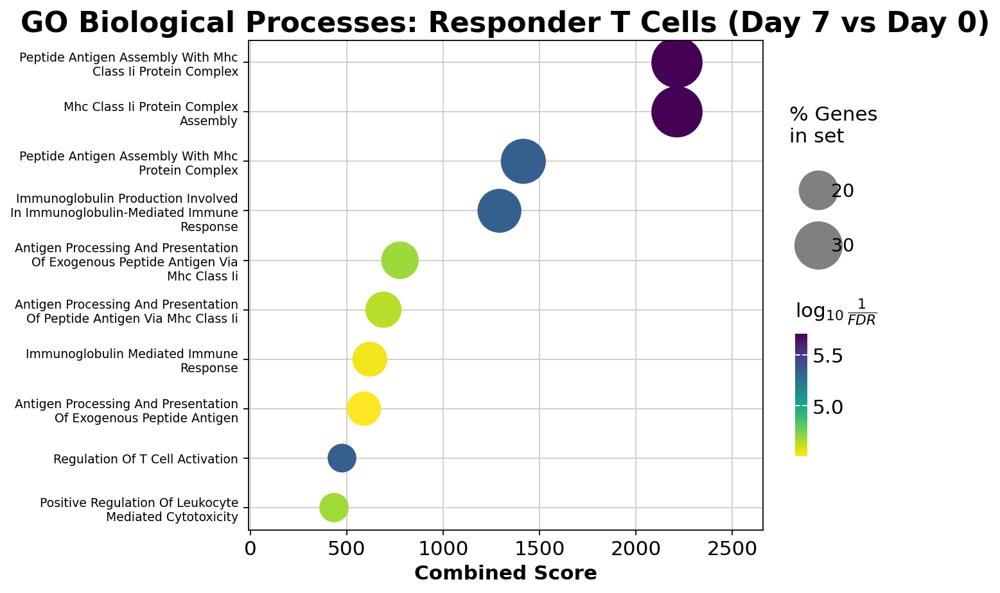

In [ ]:
import textwrap
import gseapy as gp

# 1. Subset tdata for Responders only (Day 0 and Day 7)
tdata_resp = tdata[
    tdata.obs['Response'].isin(['Responder'])
].copy()

# 2. Extract Differentially Expressed Genes (Day 7 relative to Day 0 baseline)
sc.tl.rank_genes_groups(
    tdata_resp,
    groupby='Time',
    reference='Day0',
    method='wilcoxon'
)

# 3. Get results for Day 7 upregulated genes
deg_df = sc.get.rank_genes_groups_df(tdata_resp, group='Day7')

# 4. Filter for strict significance (p_adj < 0.05 and logFC > 0.5)
sig_degs = deg_df[
    (deg_df['pvals'] < 0.05) &
    (deg_df['logfoldchanges'] > 0.5)
].sort_values(by=['logfoldchanges', 'pvals_adj'], ascending=[False, True])

target_genes = sig_degs['names'].head(100).tolist()

# 5. Run GO Biological Process enrichment
enr_resp = gp.enrichr(
    gene_list=target_genes,
    gene_sets=['GO_Biological_Process_2023'],
    organism='human',
    outdir=None,
    cutoff=0.05
)

# 6. Clean up and wrap Y-axis pathway labels
results_clean = enr_resp.results.copy()
results_clean['Term'] = results_clean['Term'].str.replace(r' \(GO:[0-9]+\)', '', regex=True).str.title()
results_clean['Term'] = results_clean['Term'].apply(lambda x: "\n".join(textwrap.wrap(x, width=35)))

# 7. Render GO Dotplot
ax = gp.dotplot(
    results_clean,
    column="Adjusted P-value",
    x="Combined Score",
    size=10,
    top_term=10,
    cmap="viridis_r",
    title="GO Biological Processes: Responder T Cells (Day 7 vs Day 0)",
    figsize=(9, 6),
    ofname=None
)

# 8. Adjust Y-axis label sizing
plt.tick_params(axis='y', labelsize=8.5)
plt.tight_layout()
plt.show()

## 21. T-cell differential-expression visualization


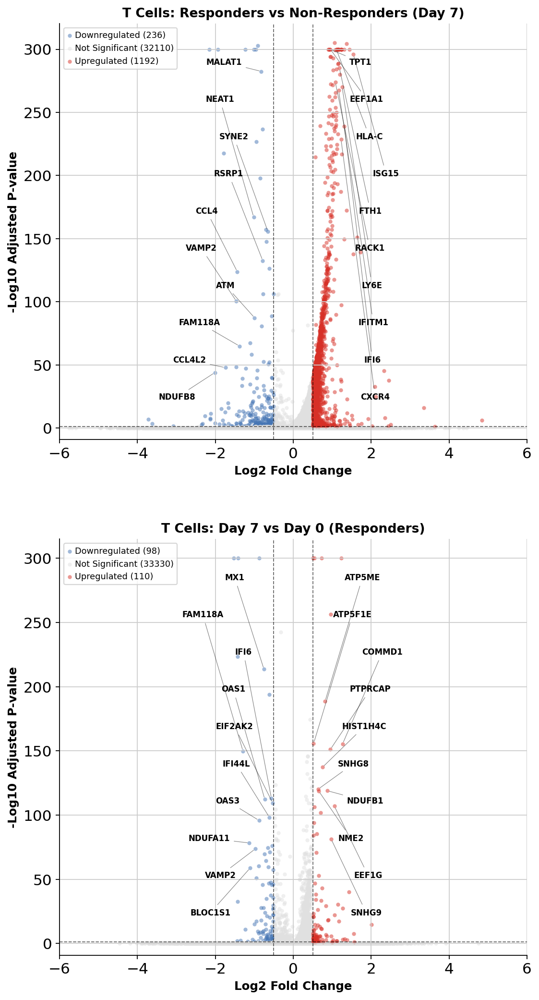

In [ ]:
import scanpy as sc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# 1. METADATA PREPARATION & DGE ANALYSIS
# ==========================================

# Ensure combined metadata column exists
if 'Group_Time' not in tdata.obs.columns:
    tdata.obs['Group_Time'] = (
        tdata.obs['Response'].astype(str) + " (" + tdata.obs['Time'].astype(str) + ")"
    )

# --- DGE 1: Responders vs Non-Responders at Day 7 ---
tdata_d7 = tdata[
    tdata.obs['Group_Time'].isin(['Responder (Day7)', 'Non-responder (Day7)'])
].copy()

sc.tl.rank_genes_groups(
    tdata_d7,
    groupby='Group_Time',
    reference='Non-responder (Day7)',
    method='wilcoxon'
)
deg_d7 = sc.get.rank_genes_groups_df(tdata_d7, group='Responder (Day7)')

# --- DGE 2: Day 7 vs Day 0 in Responders ---
tdata_resp = tdata[
    tdata.obs['Group_Time'].isin(['Responder (Day0)', 'Responder (Day7)'])
].copy()

sc.tl.rank_genes_groups(
    tdata_resp,
    groupby='Group_Time',
    reference='Responder (Day0)',
    method='wilcoxon'
)
deg_resp = sc.get.rank_genes_groups_df(tdata_resp, group='Responder (Day7)')


# ==========================================
# 2. VOLCANO PLOTTING FUNCTION
# ==========================================

def plot_refined_volcano(deg_df, title, ax, x_limit=6, top_n=10):
    deg_df = deg_df.copy()

    # Handle absolute zero p-values cleanly for log transformation
    deg_df['pvals_adj'] = np.where(deg_df['pvals_adj'] == 0, 1e-300, deg_df['pvals_adj'])
    deg_df['nlog10_pvals'] = -np.log10(deg_df['pvals_adj'])

    # Categorize gene expression status
    def categorize(row):
        if row['pvals_adj'] < 0.05 and row['logfoldchanges'] > 0.5:
            return 'Upregulated'
        elif row['pvals_adj'] < 0.05 and row['logfoldchanges'] < -0.5:
            return 'Downregulated'
        return 'Not Significant'

    deg_df['Status'] = deg_df.apply(categorize, axis=1)

    colors = {
        'Upregulated': '#d73027',
        'Downregulated': '#4575b4',
        'Not Significant': '#e0e0e0'
    }

    # Plot scatter points
    for status, group in deg_df.groupby('Status'):
        ax.scatter(
            group['logfoldchanges'],
            group['nlog10_pvals'],
            c=colors[status],
            label=f"{status} ({len(group)})",
            alpha=0.5,
            s=14,
            linewidths=0
        )

    # Reference significance lines
    ax.axhline(-np.log10(0.05), color='black', linestyle='--', linewidth=0.8, alpha=0.6)
    ax.axvline(0.5, color='black', linestyle='--', linewidth=0.8, alpha=0.6)
    ax.axvline(-0.5, color='black', linestyle='--', linewidth=0.8, alpha=0.6)

    # Filter out non-coding, mitochondrial, sex, and ribosomal clutter
    filtered_deg = deg_df[~deg_df['names'].str.startswith(('MTRNR', 'RPS', 'RPL', 'XIST', 'MT-'))].copy()
    filtered_deg['score'] = filtered_deg['logfoldchanges'].abs() * filtered_deg['nlog10_pvals']

    # Select Top N Upregulated and Downregulated genes by score
    top_up = filtered_deg[filtered_deg['Status'] == 'Upregulated'].sort_values('score', ascending=False).head(top_n)
    top_down = filtered_deg[filtered_deg['Status'] == 'Downregulated'].sort_values('score', ascending=False).head(top_n)

    # Sort selected genes by Y-axis value (nlog10_pvals) to prevent intersecting leader lines
    top_up = top_up.sort_values('nlog10_pvals', ascending=True).reset_index(drop=True)
    top_down = top_down.sort_values('nlog10_pvals', ascending=True).reset_index(drop=True)

    # Dynamic vertical placement bounds to avoid overlap
    max_y = deg_df['nlog10_pvals'].max()
    y_texts_up = np.linspace(max_y * 0.08, max_y * 0.95, len(top_up)) if len(top_up) > 0 else []
    y_texts_down = np.linspace(max_y * 0.08, max_y * 0.95, len(top_down)) if len(top_down) > 0 else []

    # Annotate Top Upregulated Genes (Right side)
    for idx, row in top_up.iterrows():
        x_text = min(row['logfoldchanges'] + 0.5, x_limit - 0.2)
        ax.annotate(
            row['names'],
            xy=(row['logfoldchanges'], row['nlog10_pvals']),
            xytext=(x_text, y_texts_up[idx]),
            fontsize=7.5,
            fontweight='bold',
            ha='left',
            va='center',
            arrowprops=dict(arrowstyle='-', color='black', lw=0.5, alpha=0.5)
        )

    # Annotate Top Downregulated Genes (Left side)
    for idx, row in top_down.iterrows():
        x_text = max(row['logfoldchanges'] - 0.5, -x_limit + 0.2)
        ax.annotate(
            row['names'],
            xy=(row['logfoldchanges'], row['nlog10_pvals']),
            xytext=(x_text, y_texts_down[idx]),
            fontsize=7.5,
            fontweight='bold',
            ha='right',
            va='center',
            arrowprops=dict(arrowstyle='-', color='black', lw=0.5, alpha=0.5)
        )

    # Set constrained axis limits
    ax.set_xlim(-x_limit, x_limit)
    ax.set_ylim(-max_y * 0.03, max_y * 1.05)

    # Layout formatting
    ax.set_xlabel("Log2 Fold Change", fontsize=11, fontweight='bold')
    ax.set_ylabel("-Log10 Adjusted P-value", fontsize=11, fontweight='bold')
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.legend(loc="upper left", frameon=True, fontsize=8)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)


# ==========================================
# 3. RENDER STACKED FIGURE (2x1 COLUMN GRID)
# ==========================================

fig, axes = plt.subplots(2, 1, figsize=(8, 14))

# Plot 1: Responders vs Non-Responders (Day 7)
plot_refined_volcano(
    deg_d7,
    "T Cells: Responders vs Non-Responders (Day 7)",
    axes[0],
    x_limit=6,
    top_n=10
)

# Plot 2: Day 7 vs Day 0 (Responders)
plot_refined_volcano(
    deg_resp,
    "T Cells: Day 7 vs Day 0 (Responders)",
    axes[1],
    x_limit=6,
    top_n=10
)

plt.tight_layout(pad=3.0)
plt.show()

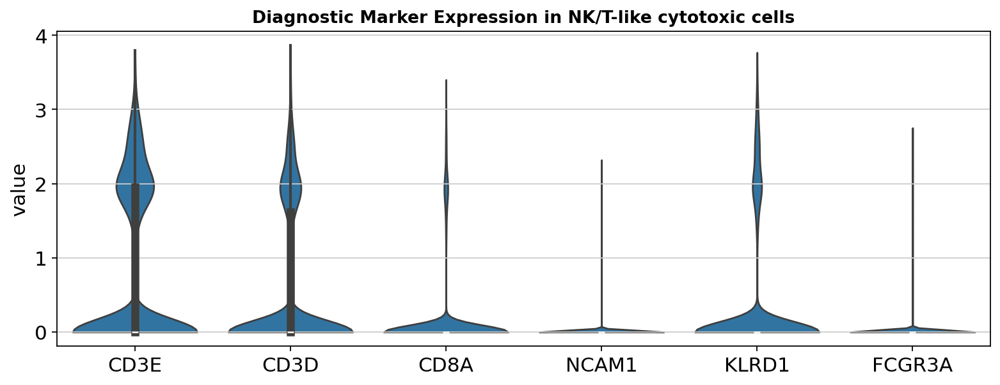

Mean Expression Values:
CD3E      0.854205
CD3D      0.566382
CD8A      0.163740
NCAM1     0.009973
KLRD1     0.381155
FCGR3A    0.013175
dtype: float32


In [ ]:
# 1. Define target diagnostic markers
markers = ['CD3E', 'CD3D', 'CD8A', 'NCAM1', 'KLRD1', 'FCGR3A']
valid_markers = [gene for gene in markers if gene in adata.var_names]

# Replace with your actual obs metadata column name if different
cluster_col = 'cell_type'
target_cluster = 'NK/T-like cytotoxic cells'

# 2. Subset object to the NK/T-like cluster
nkt_subset = adata[adata.obs[cluster_col] == target_cluster].copy()

# 3. Plot violin distribution for target markers
fig, ax = plt.subplots(figsize=(10, 4))
sc.pl.violin(
    nkt_subset,
    keys=valid_markers,
    rotation=0,
    stripplot=False,
    inner='box',
    show=False,
    ax=ax
)
ax.set_title(f"Diagnostic Marker Expression in {target_cluster}", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# 4. Print exact mean expression values
print("Mean Expression Values:")
print(nkt_subset[:, valid_markers].to_df().mean())

## 22. T-cell subclustering and annotation


In [ ]:
# 1. Subset the NK/T-like cluster from the global object
nkt_cells = adata[adata.obs['cell_type'] == 'NK/T-like cytotoxic cells'].copy()

# 2. Concatenate into tdata
tdata = sc.concat([tdata, nkt_cells], join='outer')

# 3. Re-calculate T-cell specific highly variable genes, PCA, and UMAP
sc.pp.highly_variable_genes(tdata, min_mean=0.0125, max_mean=3, min_disp=0.5)
sc.tl.pca(tdata, svd_solver='arpack')
sc.pp.neighbors(tdata, n_neighbors=15, n_pcs=20)
sc.tl.umap(tdata)

# 4. Perform high-resolution Leiden sub-clustering
sc.tl.leiden(tdata, resolution=0.6, key_added='leiden_t_subclusters')


/tmp/ipykernel_1576/2046932679.py:14: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(tdata, resolution=0.6, key_added='leiden_t_subclusters')


In [ ]:
print(tdata.obs.leiden_t_subclusters.value_counts())

leiden_t_subclusters
0    13621
1     9690
2     6158
3     3908
4     3078
5     1394
6     1077
7      893
Name: count, dtype: int64


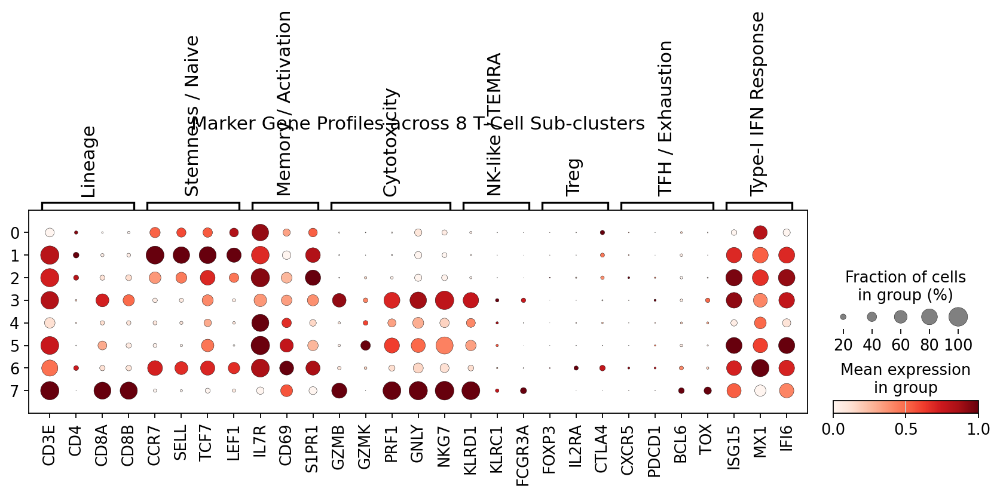

In [ ]:
#Annotating 8 T cell clusters

# Define comprehensive diagnostic gene panel for T-cell sub-populations
t_marker_dict = {
    'Lineage': ['CD3E', 'CD4', 'CD8A', 'CD8B'],
    'Stemness / Naive': ['CCR7', 'SELL', 'TCF7', 'LEF1'],
    'Memory / Activation': ['IL7R', 'CD69', 'S1PR1'],
    'Cytotoxicity': ['GZMB', 'GZMK', 'PRF1', 'GNLY', 'NKG7'],
    'NK-like / TEMRA': ['KLRD1', 'KLRC1', 'FCGR3A'],
    'Treg': ['FOXP3', 'IL2RA', 'CTLA4'],
    'TFH / Exhaustion': ['CXCR5', 'PDCD1', 'BCL6', 'TOX'],
    'Type-I IFN Response': ['ISG15', 'MX1', 'IFI6']
}

# Generate dotplot grouped by the 8 Leiden sub-clusters
sc.pl.dotplot(
    tdata,
    t_marker_dict,
    groupby='leiden_t_subclusters',
    standard_scale='var',
    title='Marker Gene Profiles across 8 T-Cell Sub-clusters'
)

In [ ]:
# T cell cluster mapping
tcell_annotation_map = {
    '0': 'CD4+ Central Memory / Naive',
    '1': 'CD4+ Pure Naive',
    '2': 'ISG-High T cells',
    '3': 'CD8+ Effector Memory (Tem)',
    '4': 'Early Effector T cells',
    '5': 'Activated Effector CD8+ T cells',
    '6': 'Regulatory T cells (Treg)',
    '7': 'Terminal Cytotoxic CD8+ T'  # Clean, readable label
}

tdata.obs['tcell_type'] = tdata.obs['leiden_t_subclusters'].map(tcell_annotation_map)

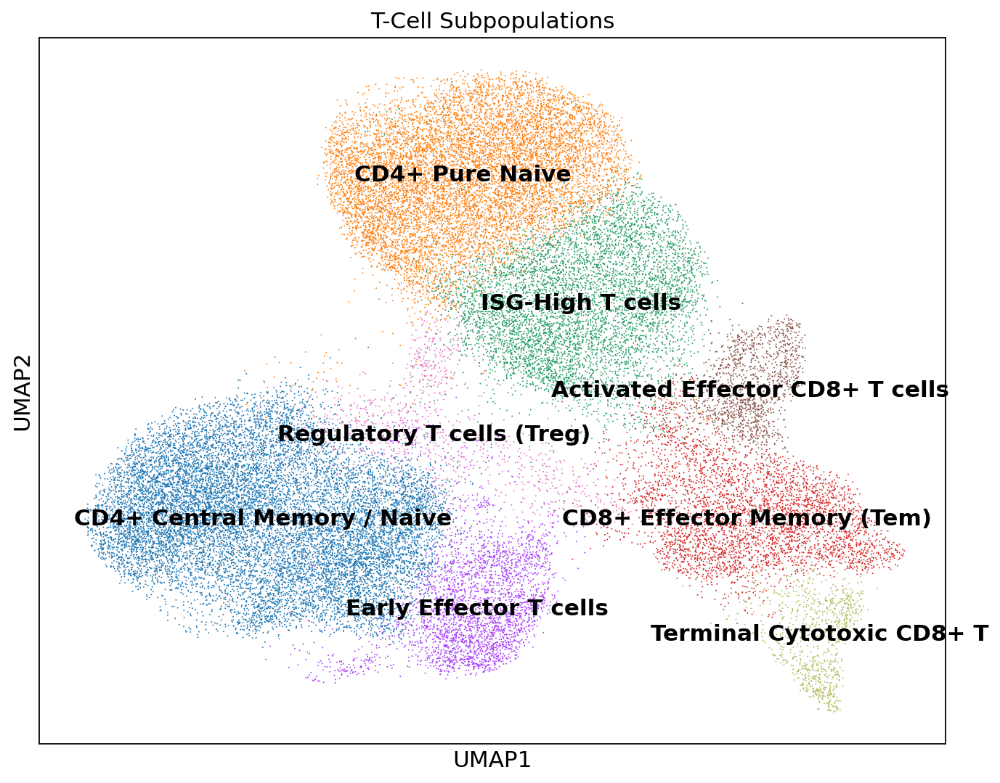

In [ ]:
# Plot UMAP with refined annotations
sc.pl.umap(tdata, color='tcell_type', legend_loc='on data', title='T-Cell Subpopulations')

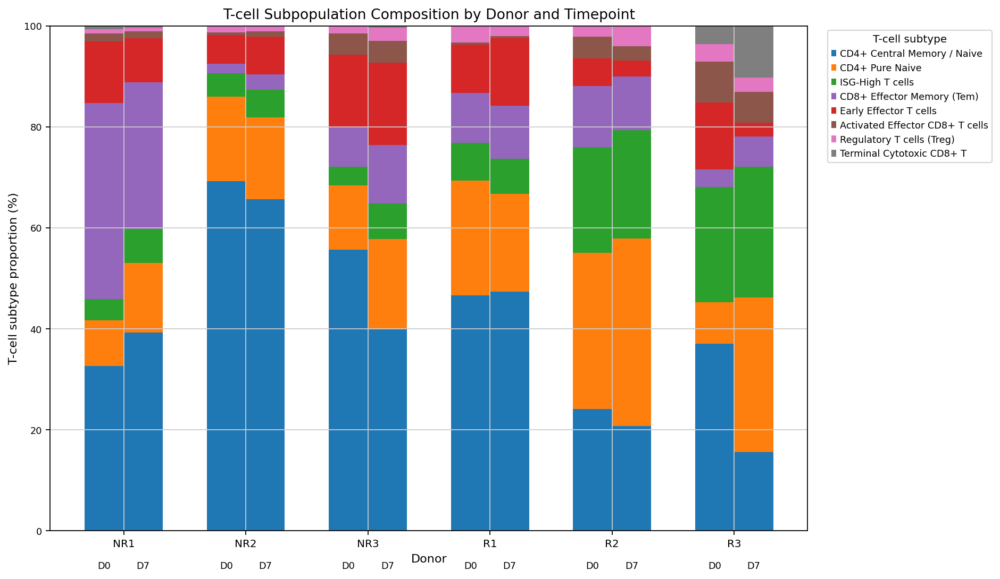

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Order donors by response group
donor_order = [
    "NR1", "NR2", "NR3",
    "R1", "R2", "R3"
]

# Fixed subtype order
subtype_cols = [
    'CD4+ Central Memory / Naive',
    'CD4+ Pure Naive',
    'ISG-High T cells',
    'CD8+ Effector Memory (Tem)',
    'Early Effector T cells',
    'Activated Effector CD8+ T cells',
    'Regulatory T cells (Treg)',
    'Terminal Cytotoxic CD8+ T'
]

# Fixed colors for each cell type
subtype_colors = {
    "CD4+ Central Memory / Naive": "#1f77b4",
    "CD4+ Pure Naive": "#ff7f0e",
    "ISG-High T cells": "#2ca02c",
    "CD8+ Effector Memory (Tem)": "#9467bd",
    "Early Effector T cells": "#d62728",
    "Activated Effector CD8+ T cells": "#8c564b",
    "Regulatory T cells (Treg)": "#e377c2",
    "Terminal Cytotoxic CD8+ T": "#7f7f7f"
}

# 1. Calculate counts of each T-cell subtype per Donor and Time_Group
t_counts = (
    tdata.obs
    .groupby(["Donor", "Time_Group", "tcell_type"], observed=True)
    .size()
    .reset_index(name="n_cells")
)

# 2. Compute total cells per donor & timepoint to get proportions
t_counts["total_cells"] = (
    t_counts
    .groupby(["Donor", "Time_Group"])["n_cells"]
    .transform("sum")
)
t_counts["proportion"] = t_counts["n_cells"] / t_counts["total_cells"]

# 3. Pivot to recreate a Donor x Timepoint matrix of subtype proportions
t_prop = (
    t_counts
    .pivot_table(
        index=["Donor", "Time_Group"],
        columns="tcell_type",
        values="proportion",
        fill_value=0
    )
    .reset_index()
)

plot_df = t_prop.copy()

plot_df["Donor"] = pd.Categorical(
    plot_df["Donor"],
    categories=donor_order,
    ordered=True
)

plot_df["Time_order"] = plot_df["Time_Group"].map({
    "Day0": 0,
    "Day7": 1
})

plot_df = plot_df.sort_values(["Donor", "Time_order"])

# Create figure
fig, ax = plt.subplots(figsize=(12, 7))

n_donors = len(donor_order)

x = np.arange(n_donors)
bar_width = 0.32

# Positions of D0 and D7 bars
x_d0 = x - bar_width / 2
x_d7 = x + bar_width / 2

# Plot D0 and D7
for timepoint, xpos in [
    ("Day0", x_d0),
    ("Day7", x_d7)
]:

    time_df = (
        plot_df[plot_df["Time_Group"] == timepoint]
        .set_index("Donor")
        .reindex(donor_order)
    )

    bottom = np.zeros(n_donors)

    for subtype in subtype_cols:
        # Ensure we don't crash if a subtype is missing from the pivoted columns
        val_col = time_df[subtype] if subtype in time_df.columns else pd.Series(0, index=time_df.index)
        values = (
            val_col
            .fillna(0)
            .values * 100
        )

        ax.bar(
            xpos,
            values,
            width=bar_width,
            bottom=bottom,
            color=subtype_colors[subtype],
            label=subtype if timepoint == "Day0" else None
        )

        bottom += values

# Donor labels
ax.set_xticks(x)
ax.set_xticklabels(
    donor_order,
    fontsize=9
)

# D0 / D7 labels underneath each donor
for i, donor in enumerate(donor_order):
    ax.text(
        x_d0[i],
        -6,
        "D0",
        ha="center",
        va="top",
        fontsize=8
    )

    ax.text(
        x_d7[i],
        -6,
        "D7",
        ha="center",
        va="top",
        fontsize=8
    )

# Axis labels
ax.set_xlabel(
    "Donor",
    fontsize=10
)

ax.set_ylabel(
    "T-cell subtype proportion (%)",
    fontsize=10
)

# Y-axis
ax.set_ylim(0, 100)
ax.tick_params(
    axis="y",
    labelsize=8
)

# Title
ax.set_title(
    "T-cell Subpopulation Composition by Donor and Timepoint",
    fontsize=12
)

# Legend
ax.legend(
    title="T-cell subtype",
    title_fontsize=9,
    fontsize=8,
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

/tmp/ipykernel_1576/4010503665.py:18: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(


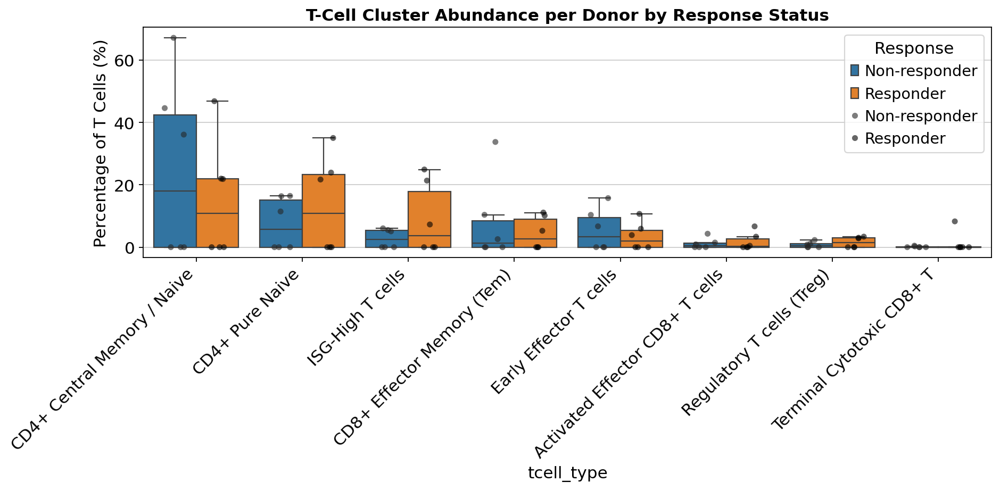

In [ ]:
# 1. Calculate percentage of each sub-cluster per Donor (clean & robust)
props = (
    tdata.obs.groupby(['Donor', 'Response'], observed=False)['tcell_type']
    .value_counts(normalize=True)
    .mul(100)
    .reset_index(name='percentage')
)

# 2. Visualize proportions with boxplots and overlaid donor points
plt.figure(figsize=(12, 6))
sns.boxplot(
    data=props,
    x='tcell_type',
    y='percentage',
    hue='Response',
    showfliers=False
)
sns.stripplot(
    data=props,
    x='tcell_type',
    y='percentage',
    hue='Response',
    dodge=True,
    color='black',
    alpha=0.6,
    jitter=0.2
)

plt.xticks(rotation=45, ha='right')
plt.ylabel('Percentage of T Cells (%)')
plt.title('T-Cell Cluster Abundance per Donor by Response Status', fontweight='bold')
plt.tight_layout()
plt.show()

/tmp/ipykernel_1576/1250940348.py:39: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(
/tmp/ipykernel_1576/1250940348.py:53: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(
/tmp/ipykernel_1576/1250940348.py:64: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_xticklabels(ax2.get_xticklabels(), rotation=35, ha='right', fontsize=11, fontweight='medium')


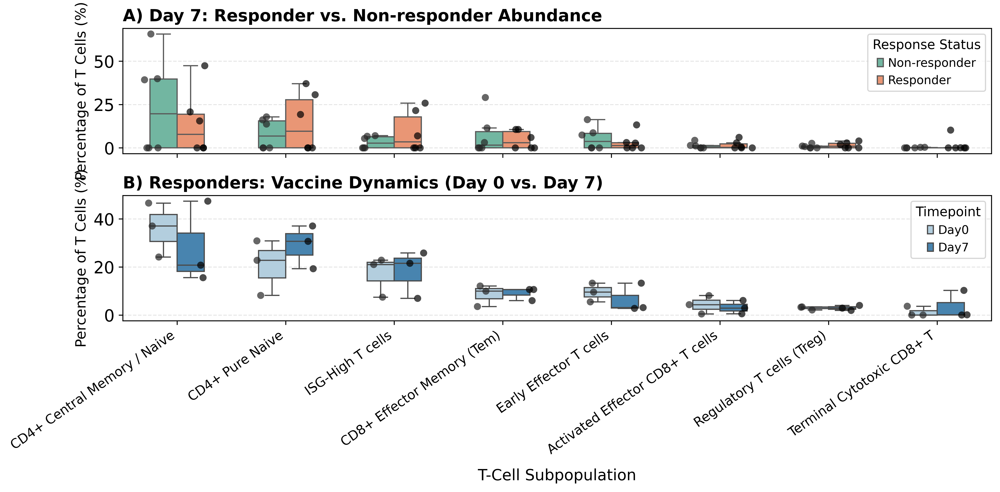

In [ ]:
# Specify your timepoint metadata column name (e.g., 'Day' or 'Timepoint')
day_col = 'Time'  # Change to your actual column name if different

# -------------------------------------------------------------------------
# 1. Compute Proportions for the Two Targeted Comparisons
# -------------------------------------------------------------------------

# Subset A: Day 7 samples (Responder vs. Non-responder)
tdata_d7 = tdata[tdata.obs[day_col].isin(['Day7'])].copy()
props_d7 = (
    tdata_d7.obs.groupby(['Donor', 'Response'], observed=False)['tcell_type']
    .value_counts(normalize=True)
    .mul(100)
    .reset_index(name='percentage')
)

# Subset B: Responders only (Day 0 vs. Day 7)
tdata_resp = tdata[
    (tdata.obs['Response'] == 'Responder') &
    (tdata.obs[day_col].isin(['Day0','Day7']))
].copy()
props_resp = (
    tdata_resp.obs.groupby(['Donor', day_col], observed=False)['tcell_type']
    .value_counts(normalize=True)
    .mul(100)
    .reset_index(name='percentage')
)

# -------------------------------------------------------------------------
# 2. Build Stacked Two-Panel Visualization
# -------------------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6), sharex=True, dpi=300)

# --- TOP PANEL: Responder vs Non-responder at Day 7 ---
sns.boxplot(
    data=props_d7, x='tcell_type', y='percentage', hue='Response',
    palette='Set2', showfliers=False, width=0.5, ax=ax1
)
sns.stripplot(
    data=props_d7, x='tcell_type', y='percentage', hue='Response',
    dodge=True, color='black', alpha=0.7, size=6, jitter=0.2, legend=False, ax=ax1
)
ax1.set_title('A) Day 7: Responder vs. Non-responder Abundance', fontsize=14, fontweight='bold', loc='left')
ax1.set_ylabel('Percentage of T Cells (%)', fontsize=12)
ax1.legend(title='Response Status', title_fontsize='11', fontsize='10', loc='upper right', frameon=True)
ax1.grid(axis='y', linestyle='--', alpha=0.5)

# --- BOTTOM PANEL: Day 0 vs Day 7 Dynamics in Responders ---
sns.boxplot(
    data=props_resp, x='tcell_type', y='percentage', hue=day_col,
    palette='Blues', showfliers=False, width=0.5, ax=ax2
)
sns.stripplot(
    data=props_resp, x='tcell_type', y='percentage', hue=day_col,
    dodge=True, color='black', alpha=0.7, size=6, jitter=0.2, legend=False, ax=ax2
)
ax2.set_title('B) Responders: Vaccine Dynamics (Day 0 vs. Day 7)', fontsize=14, fontweight='bold', loc='left')
ax2.set_xlabel('T-Cell Subpopulation', fontsize=13, labelpad=10)
ax2.set_ylabel('Percentage of T Cells (%)', fontsize=12)
ax2.legend(title='Timepoint', title_fontsize='11', fontsize='10', loc='upper right', frameon=True)
ax2.grid(axis='y', linestyle='--', alpha=0.5)

# Format X-axis tick labels on the bottom panel
ax2.set_xticklabels(ax2.get_xticklabels(), rotation=35, ha='right', fontsize=11, fontweight='medium')

plt.tight_layout()
plt.show()

/tmp/ipykernel_1576/3614467019.py:58: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(
/tmp/ipykernel_1576/3614467019.py:90: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(
/tmp/ipykernel_1576/3614467019.py:127: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_xticklabels(ax2.get_xticklabels(), rotation=35, ha='right', fontsize=11, fontweight='medium')


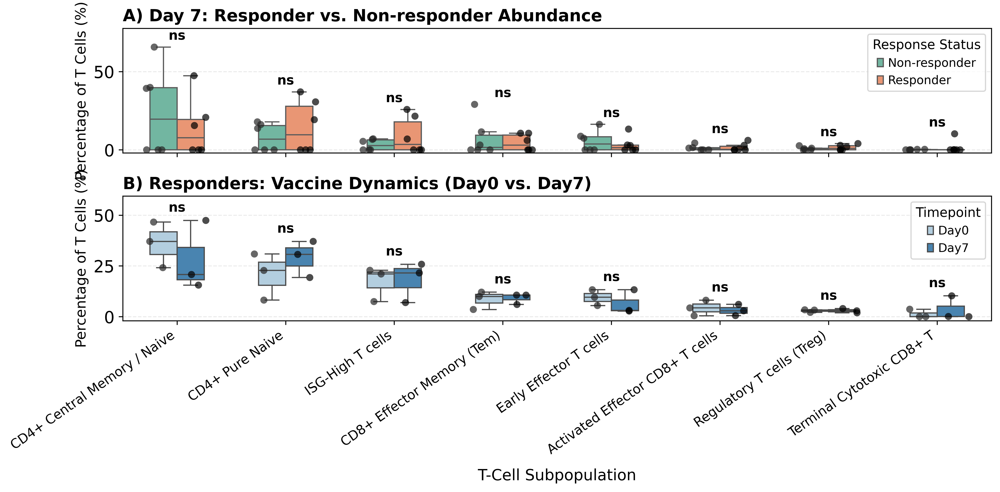

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu, wilcoxon

# -------------------------------------------------------------------------
# 1. Helper Function to Convert p-values to Star Symbols
# -------------------------------------------------------------------------
def p_to_star(p_val):
    if p_val < 0.001:
        return '***'
    elif p_val < 0.01:
        return '**'
    elif p_val < 0.05:
        return '*'
    else:
        return 'ns'

# -------------------------------------------------------------------------
# 2. Compute Proportions with Updated Metadata
# -------------------------------------------------------------------------

# Panel A: Day7 (Non-responder vs Responder)
tdata_d7 = tdata[tdata.obs['Time'] == 'Day7'].copy()
props_d7 = (
    tdata_d7.obs.groupby(['Donor', 'Response'], observed=False)['tcell_type']
    .value_counts(normalize=True)
    .mul(100)
    .reset_index(name='percentage')
)

# Panel B: Responders (Day0 vs Day7)
tdata_resp = tdata[
    (tdata.obs['Response'] == 'Responder') &
    (tdata.obs['Time'].isin(['Day0', 'Day7']))
].copy()
props_resp = (
    tdata_resp.obs.groupby(['Donor', 'Time'], observed=False)['tcell_type']
    .value_counts(normalize=True)
    .mul(100)
    .reset_index(name='percentage')
)

# List of clusters in display order
clusters = tdata.obs['tcell_type'].cat.categories if hasattr(tdata.obs['tcell_type'], 'cat') else tdata.obs['tcell_type'].unique()

# -------------------------------------------------------------------------
# 3. Visualization and Automated Statistical Annotation
# -------------------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6), sharex=True, dpi=300)

# --- TOP PANEL: Responder vs Non-responder at Day 7 ---
sns.boxplot(
    data=props_d7, x='tcell_type', y='percentage', hue='Response',
    palette='Set2', showfliers=False, width=0.5, ax=ax1
)
sns.stripplot(
    data=props_d7, x='tcell_type', y='percentage', hue='Response',
    dodge=True, color='black', alpha=0.7, size=6, jitter=0.2, legend=False, ax=ax1
)

ax1.set_title('A) Day 7: Responder vs. Non-responder Abundance', fontsize=14, fontweight='bold', loc='left')
ax1.set_ylabel('Percentage of T Cells (%)', fontsize=12)
ax1.legend(title='Response Status', title_fontsize='11', fontsize='10', loc='upper right', frameon=True)
ax1.grid(axis='y', linestyle='--', alpha=0.4)

# Calculate and annotate stats for Panel A
for i, cluster in enumerate(clusters):
    nr_vals = props_d7[(props_d7['tcell_type'] == cluster) & (props_d7['Response'] == 'Non-responder')]['percentage']
    r_vals = props_d7[(props_d7['tcell_type'] == cluster) & (props_d7['Response'] == 'Responder')]['percentage']

    if len(nr_vals) > 0 and len(r_vals) > 0:
        stat, p = mannwhitneyu(nr_vals, r_vals, alternative='two-sided')
        stars = p_to_star(p)

        # Position height above maximum data point
        y_max = max(nr_vals.max() if len(nr_vals) else 0, r_vals.max() if len(r_vals) else 0)
        y_pos = y_max + 3

        ax1.text(i, y_pos, stars, ha='center', va='bottom', fontsize=11, fontweight='bold', color='black')

ax1.set_ylim(bottom=-2, top=props_d7['percentage'].max() + 12)

# --- BOTTOM PANEL: Day 0 vs Day 7 Dynamics in Responders ---
sns.boxplot(
    data=props_resp, x='tcell_type', y='percentage', hue='Time',
    palette='Blues', showfliers=False, width=0.5, ax=ax2
)
sns.stripplot(
    data=props_resp, x='tcell_type', y='percentage', hue='Time',
    dodge=True, color='black', alpha=0.7, size=6, jitter=0.2, legend=False, ax=ax2
)

ax2.set_title('B) Responders: Vaccine Dynamics (Day0 vs. Day7)', fontsize=14, fontweight='bold', loc='left')
ax2.set_xlabel('T-Cell Subpopulation', fontsize=13, labelpad=10)
ax2.set_ylabel('Percentage of T Cells (%)', fontsize=12)
ax2.legend(title='Timepoint', title_fontsize='11', fontsize='10', loc='upper right', frameon=True)
ax2.grid(axis='y', linestyle='--', alpha=0.4)

# Calculate and annotate stats for Panel B
for i, cluster in enumerate(clusters):
    d0_vals = props_resp[(props_resp['tcell_type'] == cluster) & (props_resp['Time'] == 'Day0')]['percentage']
    d7_vals = props_resp[(props_resp['tcell_type'] == cluster) & (props_resp['Time'] == 'Day7')]['percentage']

    if len(d0_vals) > 0 and len(d7_vals) > 0:
        try:
            # Paired test if equal lengths, otherwise Mann-Whitney U
            if len(d0_vals) == len(d7_vals):
                stat, p = wilcoxon(d0_vals, d7_vals)
            else:
                stat, p = mannwhitneyu(d0_vals, d7_vals)
        except ValueError:
            p = 1.0

        stars = p_to_star(p)

        # Position height above maximum data point
        y_max = max(d0_vals.max() if len(d0_vals) else 0, d7_vals.max() if len(d7_vals) else 0)
        y_pos = y_max + 3

        ax2.text(i, y_pos, stars, ha='center', va='bottom', fontsize=11, fontweight='bold', color='black')

ax2.set_ylim(bottom=-2, top=props_resp['percentage'].max() + 12)

# Format X-axis tick labels
ax2.set_xticklabels(ax2.get_xticklabels(), rotation=35, ha='right', fontsize=11, fontweight='medium')

plt.tight_layout()
plt.show()

In [ ]:
print(adata.obs.cell_type.value_counts())

cell_type
NK cells                              12578
Naive/Central Memory CD4 T cells      11763
Resting CD4 T cells                    8538
NK/T-like cytotoxic cells              8450
Cytotoxic CD8 T cells                  6375
Naive/central memory mixed T cells     4693
B cells                                4048
Name: count, dtype: int64


## 23. NK-cell analysis


Interpret NK-cell differential-expression and gene-module patterns as hypothesis-generating. Distinguish descriptive cell-level results from conclusions supported by independent biological replicates.


In [ ]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import gseapy as gp

# Subset NK cells
nk_data = adata[adata.obs['cell_type'] == 'NK cells'].copy()

In [ ]:
# Differential Gene Expression
# Helper function to extract clean DGE results
def extract_dge_df(adata_sub, groupby, group_target, group_ref):
    sub = adata_sub[adata_sub.obs[groupby].isin([group_target, group_ref])].copy()

    sc.tl.rank_genes_groups(
        sub,
        groupby=groupby,
        groups=[group_target],
        reference=group_ref,
        method='wilcoxon'
    )

    result = sub.uns['rank_genes_groups']
    df = pd.DataFrame({
        'gene': result['names'][group_target],
        'log2foldchange': result['logfoldchanges'][group_target],
        'pvals': result['pvals'][group_target],
        'pvals_adj': result['pvals_adj'][group_target]
    })
    return df

# 1. Comparison 1: Day 7 (Responder vs. Non-responder)
nk_d7 = nk_data[nk_data.obs['Time'] == 'Day7'].copy()
df_comp1 = extract_dge_df(
    nk_d7, groupby='Response', group_target='Responder', group_ref='Non-responder'
)

# 2. Comparison 2: Responders (Day 7 vs. Day 0)
nk_resp = nk_data[nk_data.obs['Response'] == 'Responder'].copy()
df_comp2 = extract_dge_df(
    nk_resp, groupby='Time', group_target='Day7', group_ref='Day0'
)

In [ ]:
%pip install adjustText

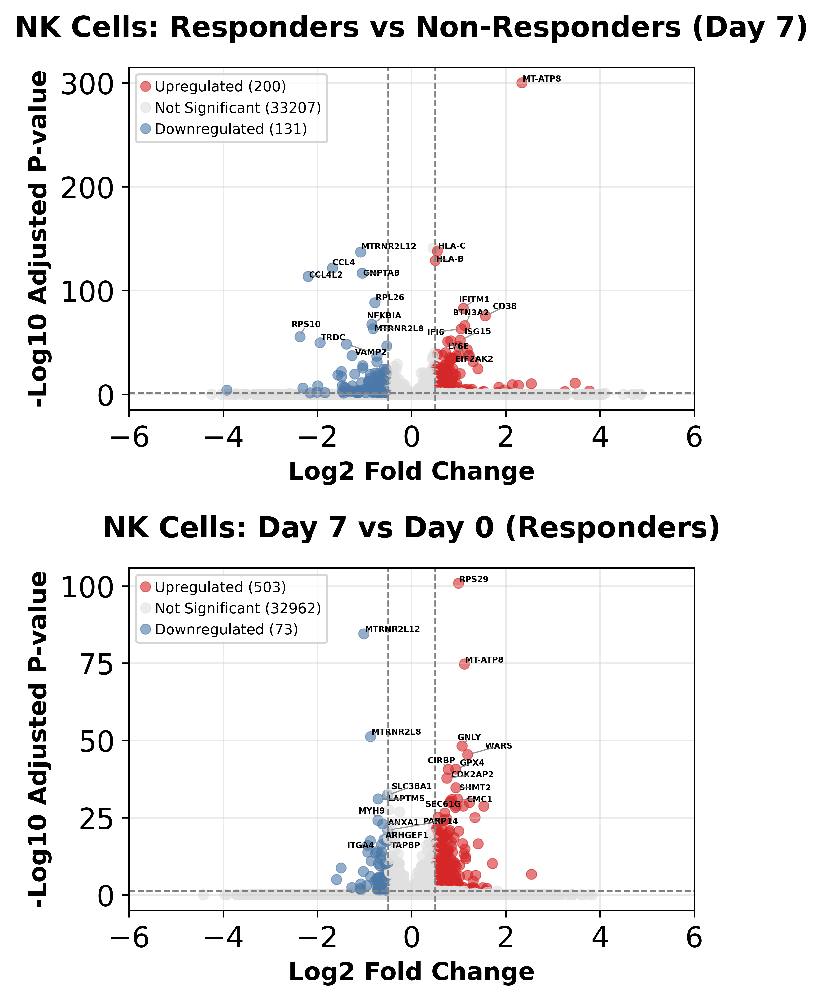

In [ ]:
from adjustText import adjust_text

# Set up vertical canvas (2 rows, 1 column)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(5, 7), dpi=300)

def draw_volcano_adjusted(ax, df, title, log2fc_thresh=0.5, pval_thresh=0.05, top_n=10):
    df = df.copy()
    # Prevent log10(0) errors
    df['pvals_adj'] = df['pvals_adj'].replace(0, 1e-300)
    df['-log10_pval'] = -np.log10(df['pvals_adj'])

    # Identify significance groups
    cond_up = (df['log2foldchange'] > log2fc_thresh) & (df['pvals_adj'] < pval_thresh)
    cond_down = (df['log2foldchange'] < -log2fc_thresh) & (df['pvals_adj'] < pval_thresh)

    n_up, n_down = cond_up.sum(), cond_down.sum()
    n_ns = len(df) - (n_up + n_down)

    # Create descriptive labels matching your T cell plot style
    label_up = f'Upregulated ({n_up})'
    label_down = f'Downregulated ({n_down})'
    label_ns = f'Not Significant ({n_ns})'

    df['Significance'] = label_ns
    df.loc[cond_up, 'Significance'] = label_up
    df.loc[cond_down, 'Significance'] = label_down

    # Map colors
    palette = {label_ns: '#E0E0E0', label_up: '#D62728', label_down: '#4C78A8'}

    # Plot scatter
    sns.scatterplot(
        data=df, x='log2foldchange', y='-log10_pval',
        hue='Significance', palette=palette, alpha=0.6, s=25, edgecolor=None, ax=ax
    )

    # Draw reference thresholds
    ax.axvline(x=log2fc_thresh, color='gray', linestyle='--', linewidth=0.8)
    ax.axvline(x=-log2fc_thresh, color='gray', linestyle='--', linewidth=0.8)
    ax.axhline(y=-np.log10(pval_thresh), color='gray', linestyle='--', linewidth=0.8)

    # Enforce strict axis limits
    ax.set_xlim(-6, 6)

    # Extract genes for labeling
    up_genes = df[cond_up].nlargest(top_n, '-log10_pval')
    down_genes = df[cond_down].nlargest(top_n, '-log10_pval')

    # Collect text objects for collision adjustment
    texts = []
    for _, row in pd.concat([up_genes, down_genes]).iterrows():
        texts.append(ax.text(
            row['log2foldchange'], row['-log10_pval'], row['gene'],
            fontsize=4, fontweight='bold', color='black'
        ))

    # Apply adjust_text to repel labels and draw connecting lines
    adjust_text(
        texts,
        ax=ax,
        arrowprops=dict(arrowstyle='-', color='gray', lw=0.6, alpha=0.8),
        expand_points=(1.5, 1.5),
        force_text=(0.5, 1.0)
    )

    # Formatting to match reference image
    ax.set_title(title, fontsize=14, fontweight='bold', pad=15)
    ax.set_xlabel('Log2 Fold Change', fontsize=12, fontweight='bold')
    ax.set_ylabel('-Log10 Adjusted P-value', fontsize=12, fontweight='bold')
    ax.grid(True, linestyle='-', alpha=0.4)
    ax.legend(title='', loc='upper left', frameon=True, prop={'size': 7})

# Plot Panel A and Panel B
draw_volcano_adjusted(ax1, df_comp1, title='NK Cells: Responders vs Non-Responders (Day 7)')
draw_volcano_adjusted(ax2, df_comp2, title='NK Cells: Day 7 vs Day 0 (Responders)')

plt.tight_layout()
plt.show()

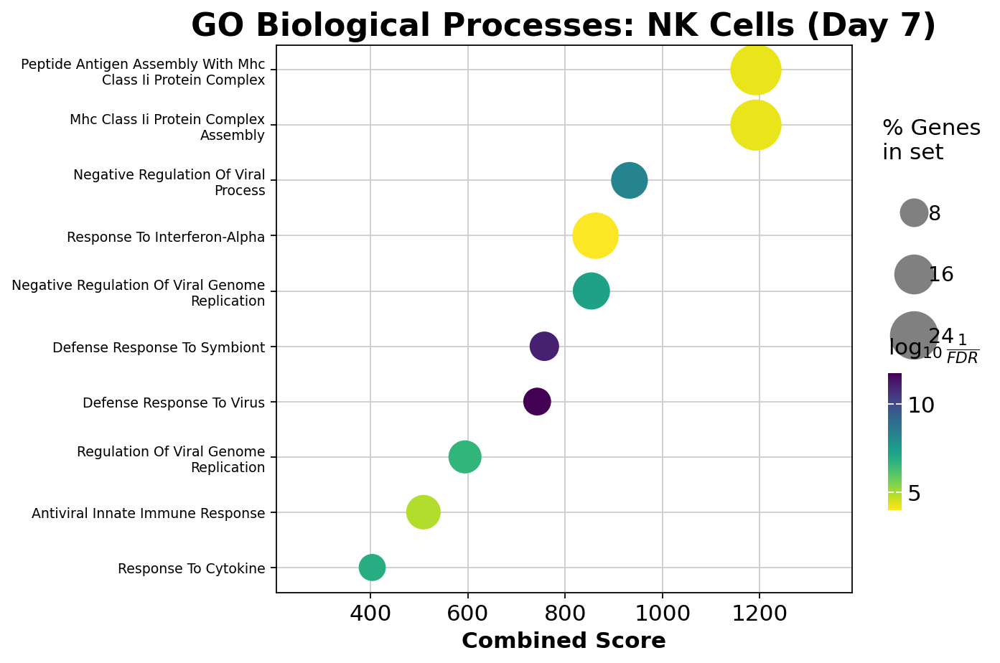

In [ ]:
# 1. Isolate Day 7 cells and exclude the "Stressed" cluster to ensure clean biological signal
nk_data_day7 = nk_data[
    (nk_data.obs['Time'].astype(str) == 'Day7')
].copy()

# 2. Run Differential Gene Expression (Responders vs Non-responders)
# Assuming your metadata column distinguishing them is called 'Response'
sc.tl.rank_genes_groups(
    nk_data_day7,
    groupby='Response',
    reference='Non-responder',  # Sets Non-responder as the baseline
    method='wilcoxon'
)

# 3. Extract the results for Responders into a Pandas DataFrame
deg_df = sc.get.rank_genes_groups_df(nk_data_day7, group='Responder')

# 4. Filter for strict statistical significance and positive fold-change (upregulated in Responders)
# Logfoldchange > 0.5 is a standard threshold to filter out biological noise
significant_degs = deg_df[
    (deg_df['pvals'] < 0.05) &
    (deg_df['logfoldchanges'] > 0.5)
].copy()

# 5. Sort the genes by the highest fold change and most significant p-value
significant_degs = significant_degs.sort_values(
    by=['logfoldchanges', 'pvals_adj'],
    ascending=[False, True]
)

# 6. Extract the top 100 gene names as a simple list
nk_target_genes = significant_degs['names'].head(100).tolist()

import textwrap
import gseapy as gp

enr_nkcells = gp.enrichr(
    gene_list= nk_target_genes,
    gene_sets=['GO_Biological_Process_2023'],
    organism='human',
    outdir=None,
    cutoff=0.05
)

# 2. Clean up long GO terms and wrap text for better plotting room
results_clean = enr_nkcells.results.copy()
results_clean['Term'] = results_clean['Term'].str.replace(r' \(GO:[0-9]+\)', '', regex=True).str.title()
results_clean['Term'] = results_clean['Term'].apply(lambda x: "\n".join(textwrap.wrap(x, width=35)))

# 3. Render the GO Dotplot
ax = gp.dotplot(
    results_clean,
    column="Adjusted P-value",
    x="Combined Score",
    size=10,
    top_term=10,
    cmap="viridis_r",
    title="GO Biological Processes: NK Cells (Day 7)",
    figsize=(9, 6),
    ofname=None
)

# 4. Fine-tune axis labels and display
plt.tick_params(axis='y', labelsize=8.5)
plt.tight_layout()
plt.show()

Number of input DEGs for GO analysis: 100

Top 5 Enriched Terms:
                                                Term   P-value  \
0  Positive Regulation Of Calcium Ion Transport I...  0.000680   
1  Nucleoside Triphosphate Metabolic Process (GO:...  0.001085   
2  Establishment Of Protein Localization To Mitoc...  0.001384   
3  Protein Insertion Into Mitochondrial Inner Mem...  0.001581   
4  Regulation Of Retrograde Protein Transport, ER...  0.001581   

   Adjusted P-value  Combined Score  
0          0.217195      493.565548  
1          0.217195      346.391772  
2          0.217195       98.609757  
3          0.217195      261.803919  
4          0.217195      261.803919  


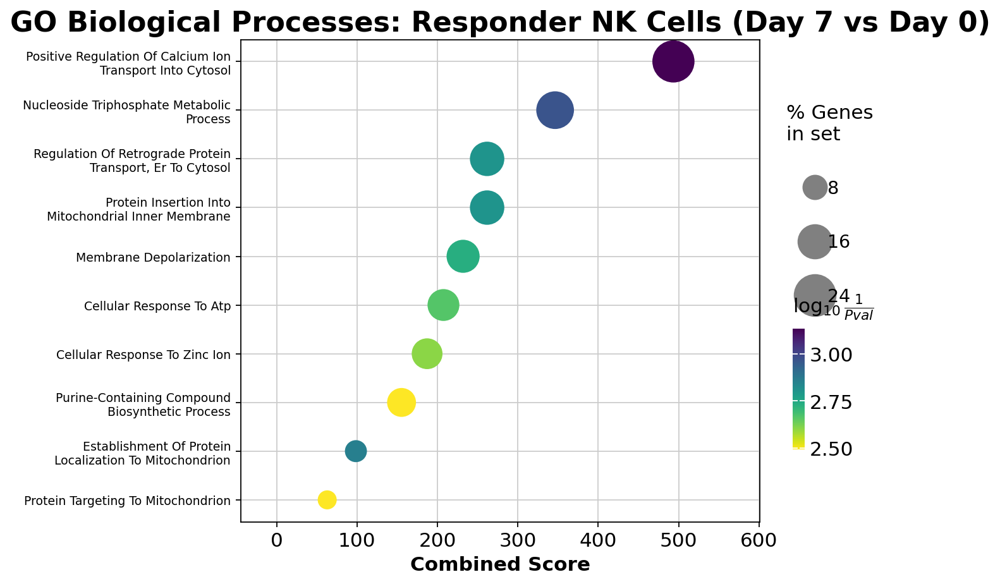

In [ ]:
# 1. Subset for Responders only
nk_data_resp = nk_data[
    nk_data.obs['Response'].isin(['Responder'])
].copy()

# 2. Extract DEGs (Day 7 vs Day 0)
sc.tl.rank_genes_groups(
    nk_data_resp,
    groupby='Time',
    reference='Day0',
    method='wilcoxon'
)

# 3. Get results for Day 7 upregulated genes
deg_df = sc.get.rank_genes_groups_df(nk_data_resp, group='Day7')

# 4. Filter DEGs
sig_degs = deg_df[
    (deg_df['pvals_adj'] < 0.05) &
    (deg_df['logfoldchanges'] > 0.5)
].sort_values(by=['logfoldchanges', 'pvals_adj'], ascending=[False, True])

nk_target_genes = sig_degs['names'].head(100).tolist()

print(f"Number of input DEGs for GO analysis: {len(nk_target_genes)}")

# 5. Run GO Biological Process enrichment (set cutoff=1.0 to avoid the crash)
enr_resp = gp.enrichr(
    gene_list=nk_target_genes,
    gene_sets=['GO_Biological_Process_2023'],
    organism='human',
    outdir=None,
    cutoff=1.0  # <--- Set to 1.0 so gseapy returns raw results without crashing
)

# 6. Clean up and wrap Y-axis pathway labels
results_clean = enr_resp.results.copy()

# Print top 5 terms to see what Enrichr returned
print("\nTop 5 Enriched Terms:")
print(results_clean[['Term', 'P-value', 'Adjusted P-value', 'Combined Score']].head())

if not results_clean.empty:
    results_clean['Term'] = results_clean['Term'].str.replace(r' \(GO:[0-9]+\)', '', regex=True).str.title()
    results_clean['Term'] = results_clean['Term'].apply(lambda x: "\n".join(textwrap.wrap(x, width=35)))

    # 7. Render GO Dotplot (plot top terms by P-value or Combined Score)
    ax = gp.dotplot(
        results_clean,
        column="P-value", # or "Adjusted P-value"
        x="Combined Score",
        size=10,
        top_term=10,
        cmap="viridis_r",
        title="GO Biological Processes: Responder NK Cells (Day 7 vs Day 0)",
        figsize=(9, 6),
        ofname=None
    )

    plt.tick_params(axis='y', labelsize=8.5)
    plt.tight_layout()
    plt.show()
else:
    print("No GO terms were matched. Try relaxing logfoldchanges threshold (e.g., > 0.25).")

/tmp/ipykernel_1576/720011812.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/tmp/ipykernel_1576/720011812.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/tmp/ipykernel_1576/720011812.py:51: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/tmp/ipykernel_1576/720011812.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


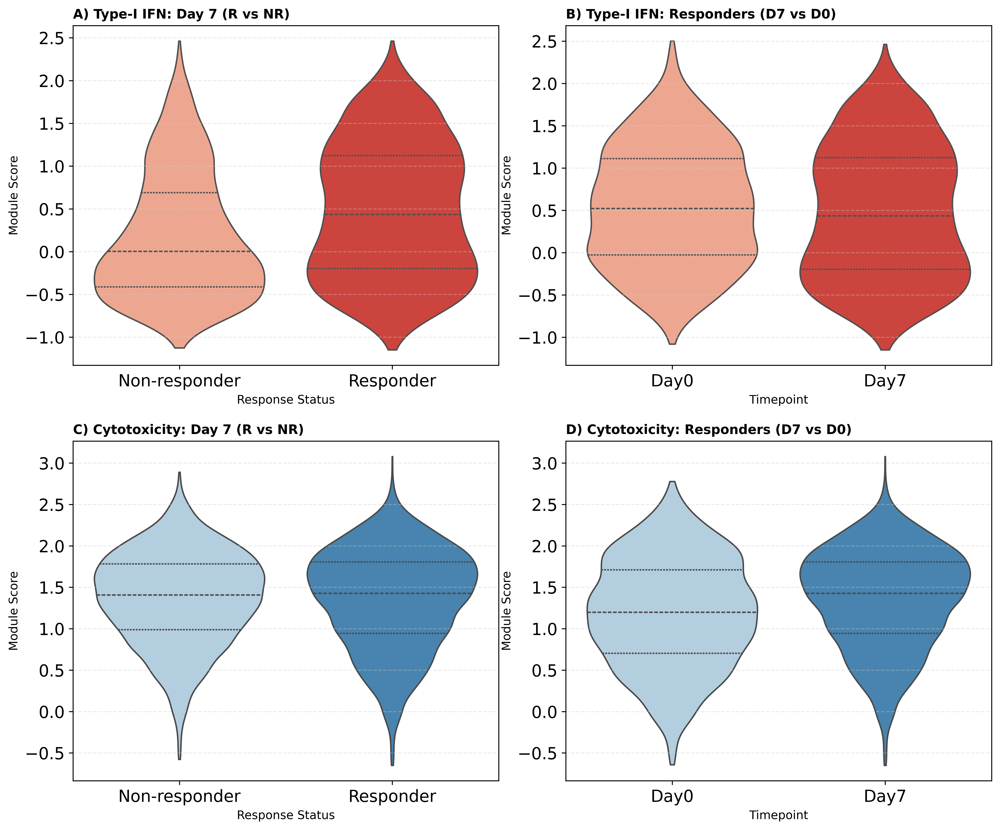

In [ ]:
import scanpy as sc
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Define Gene Lists for Core Modules
ifn_genes = ['ISG15', 'MX1', 'IFI6', 'IFIT1', 'IRF7', 'IFIT3', 'OAS1']
cyto_genes = ['GZMB', 'GZMA', 'PRF1', 'GNLY', 'NKG7', 'KLRD1']

# Filter for genes present in dataset
ifn_genes = [g for g in ifn_genes if g in nk_data.var_names]
cyto_genes = [g for g in cyto_genes if g in nk_data.var_names]

# 2. Compute Module Scores on Full NK Object
sc.tl.score_genes(nk_data, gene_list=ifn_genes, score_name='IFN_Response_Score')
sc.tl.score_genes(nk_data, gene_list=cyto_genes, score_name='Cytotoxicity_Score')

# 3. Define Analysis Subsets
nk_d7 = nk_data[nk_data.obs['Time'] == 'Day7'].copy()
nk_resp = nk_data[nk_data.obs['Response'] == 'Responder'].copy()

# 4. Generate 2x2 Grid Figure
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(12, 10), dpi=300)

# -------------------------------------------------------------------------
# Panel A (Top-Left): IFN Score — Day 7 (Responder vs Non-responder)
# -------------------------------------------------------------------------
sns.violinplot(
    data=nk_d7.obs, x='Response', y='IFN_Response_Score',
    palette='Reds', inner='quartile', cut=0, ax=ax1
)
ax1.set_title('A) Type-I IFN: Day 7 (R vs NR)', fontsize=11, fontweight='bold', loc='left')
ax1.set_ylabel('Module Score', fontsize=10)
ax1.set_xlabel('Response Status', fontsize=10)
ax1.grid(axis='y', linestyle='--', alpha=0.4)

# -------------------------------------------------------------------------
# Panel B (Top-Right): IFN Score — Responders (Day 7 vs Day 0)
# -------------------------------------------------------------------------
sns.violinplot(
    data=nk_resp.obs, x='Time', y='IFN_Response_Score',
    palette='Reds', inner='quartile', cut=0, ax=ax2
)
ax2.set_title('B) Type-I IFN: Responders (D7 vs D0)', fontsize=11, fontweight='bold', loc='left')
ax2.set_ylabel('Module Score', fontsize=10)
ax2.set_xlabel('Timepoint', fontsize=10)
ax2.grid(axis='y', linestyle='--', alpha=0.4)

# -------------------------------------------------------------------------
# Panel C (Bottom-Left): Cytotoxicity Score — Day 7 (Responder vs Non-responder)
# -------------------------------------------------------------------------
sns.violinplot(
    data=nk_d7.obs, x='Response', y='Cytotoxicity_Score',
    palette='Blues', inner='quartile', cut=0, ax=ax3
)
ax3.set_title('C) Cytotoxicity: Day 7 (R vs NR)', fontsize=11, fontweight='bold', loc='left')
ax3.set_ylabel('Module Score', fontsize=10)
ax3.set_xlabel('Response Status', fontsize=10)
ax3.grid(axis='y', linestyle='--', alpha=0.4)

# -------------------------------------------------------------------------
# Panel D (Bottom-Right): Cytotoxicity Score — Responders (Day 7 vs Day 0)
# -------------------------------------------------------------------------
sns.violinplot(
    data=nk_resp.obs, x='Time', y='Cytotoxicity_Score',
    palette='Blues', inner='quartile', cut=0, ax=ax4
)
ax4.set_title('D) Cytotoxicity: Responders (D7 vs D0)', fontsize=11, fontweight='bold', loc='left')
ax4.set_ylabel('Module Score', fontsize=10)
ax4.set_xlabel('Timepoint', fontsize=10)
ax4.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()